## 데이터 불러오기

- **하는 일:** 프로젝트 경로를 찾고 원본 JSON 하나와 연결된 이미지를 읽어 `img`와 `annotations`에 저장한다.
- **사용 이유:** 파일 경로와 라벨 구조를 먼저 확인해 이후 집계·시각화에 사용할 기준을 준비한다.
- **결과 읽기:** 이미지 해상도와 해당 JSON에 들어 있는 라벨 수가 나온다. 아직 같은 사진의 다른 JSON까지 합친 결과는 아니다.
- **실행 조건:** 처음 실행하는 준비 셀이다. 프로젝트 폴더 또는 그 하위에서 실행한다.


In [ ]:
import json
from pathlib import Path

import cv2
import numpy as np

# 1. 프로젝트 최상위 폴더를 찾는다.
# 현재 폴더부터 상위 폴더까지 확인한다.
# src/config.py와 pyproject.toml이 함께 있는 곳을 프로젝트 루트로 판단한다.
PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "config.py").is_file() and (folder / "pyproject.toml").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("pill-bbox 프로젝트 안에서 노트북을 실행해 주세요.")

# 2. JSON 라벨 폴더와 이미지 폴더의 경로를 만든다.
annotation_dir = PROJECT_ROOT / "data" / "raw" / "train_annotations"
image_dir = PROJECT_ROOT / "data" / "raw" / "train_images"

# 3. 하위 폴더까지 탐색해서 JSON 파일 하나를 선택한다.
annotation_path = next(annotation_dir.rglob("*.json"), None)
if annotation_path is None:
    raise FileNotFoundError(f"JSON 라벨 파일이 없습니다: {annotation_dir}")

# 4. JSON 파일을 읽어 파이썬 딕셔너리로 바꾼다.
with annotation_path.open(encoding="utf-8") as file:
    data = json.load(file)

# 5. JSON에 기록된 첫 번째 이미지의 정보를 가져온다.
image_info = data["images"][0]

# 이미지 폴더 경로와 파일명을 합쳐 실제 이미지 경로를 만든다.
image_path = image_dir / image_info["file_name"]

# 6. 이미지 파일을 바이트 배열로 읽고, 이미지 배열로 변환한다.
# 이 방식은 한글이 포함된 경로에서도 이미지를 읽을 수 있게 한다.
img = cv2.imdecode(
    np.fromfile(image_path, dtype=np.uint8),
    cv2.IMREAD_COLOR,
)

# 파일을 이미지로 해석하지 못했다면 오류를 발생시킨다.
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")

# OpenCV 기본 색상 순서인 BGR을 RGB로 바꾼다.
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 7. JSON의 라벨 중 선택한 이미지에 연결된 것만 모은다.
annotations = [
    annotation for annotation in data["annotations"] if annotation["image_id"] == image_info["id"]
]

# 8. 읽은 결과를 확인한다.

print(f"이미지 로드 완료: {img.shape[1]}×{img.shape[0]}px / 이 JSON의 라벨 {len(annotations)}개")

## 데이터 파일 수 집계

- **하는 일:** 학습·테스트 이미지와 학습 annotation JSON의 파일 수를 센다.
- **사용 이유:** 보유한 데이터 규모를 파악하고 이후 검사에서 읽은 개수와 대조하기 위해 사용한다.
- **결과 읽기:** 이미지 수와 JSON 수가 따로 나온다. 한 사진의 라벨이 여러 JSON에 나뉘어 있어 두 수가 같지 않을 수 있다.
- **실행 조건:** `데이터 불러오기` 셀 다음에 실행한다. 파일 내용이나 픽셀은 읽지 않는다.


In [ ]:
# 이미지 확장자는 대소문자 구분 없이 확인한다.
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

# 학습 이미지와 테스트 이미지 수를 각각 센다.
for folder_name in ("train_images", "test_images"):
    folder = PROJECT_ROOT / "data" / "raw" / folder_name
    if not folder.is_dir():
        raise FileNotFoundError(f"데이터 폴더가 없습니다: {folder}")
    image_count = sum(
        1
        for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    print(f"{folder_name}: 이미지 {image_count:,}개")

# 라벨 JSON 수는 이미지 수와 구분해서 출력한다.
annotation_dir = PROJECT_ROOT / "data" / "raw" / "train_annotations"
if not annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {annotation_dir}")
annotation_count = sum(
    1 for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
)
print(f"train_annotations: JSON {annotation_count:,}개")

## 학습·테스트 이미지 구조 비교

- **하는 일:** 이미지 헤더를 읽어 데이터별 이미지 수·해상도·색상 모드·읽기 오류를 비교한다.
- **사용 이유:** 학습·테스트 입력의 구조 차이와 읽을 수 없는 파일을 먼저 확인하기 위해 사용한다.
- **결과 읽기:** 작은 비교표와 같은 파일명 개수가 나온다. 헤더가 정상이어도 전체 픽셀의 손상 여부까지 확인된 것은 아니다. 상세 자료는 `image_structure`에 남는다.
- **실행 조건:** `데이터 불러오기`와 `데이터 파일 수 집계` 셀을 먼저 실행한다.


In [ ]:
from collections import Counter

import pandas as pd
from IPython.display import display
from PIL import Image

# 전체 픽셀을 읽지 않고 이미지 헤더에서 크기와 색상 모드를 확인한다.
image_structure_rows = []
image_path_sets = {}
for split_name in ("train_images", "test_images"):
    split_dir = PROJECT_ROOT / "data" / "raw" / split_name
    if not split_dir.is_dir():
        raise FileNotFoundError(f"이미지 폴더가 없습니다: {split_dir}")
    image_paths = sorted(
        path
        for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    image_path_sets[split_name] = {path.name for path in image_paths}

    for path in image_paths:
        row = {"구분": split_name, "파일명": path.relative_to(split_dir).as_posix()}
        try:
            with Image.open(path) as image:
                row.update({"너비": image.width, "높이": image.height, "색상 모드": image.mode})
        except (OSError, ValueError) as error:
            row["읽기 오류"] = str(error)
        image_structure_rows.append(row)

    split_rows = [row for row in image_structure_rows if row["구분"] == split_name]

image_structure = pd.DataFrame(image_structure_rows)
shared_image_names = image_path_sets["train_images"] & image_path_sets["test_images"]

# 파일명 예시 대신 학습·테스트 데이터의 구조만 비교한다.

image_structure_summary = []
for split, rows in image_structure.groupby("구분", sort=False):
    valid = rows.loc[rows["너비"].notna()] if "너비" in rows else rows.iloc[:0]
    image_structure_summary.append(
        {
            "데이터": split,
            "이미지 수": len(rows),
            "해상도": sorted(
                {f"{int(row['너비'])}×{int(row['높이'])}" for row in valid.to_dict("records")}
            ),
            "색상 모드": sorted(valid["색상 모드"].unique()) if "색상 모드" in valid else [],
            "읽기 오류": len(rows) - len(valid),
        }
    )
display(pd.DataFrame(image_structure_summary).set_index("데이터"))
print(f"학습·테스트 간 같은 파일명: {len(shared_image_names)}개")

## 사진별 JSON·라벨 연결 집계

- **하는 일:** JSON 내부 이미지 정보를 기준으로 사진별 annotation 파일과 라벨 수를 모은다.
- **사용 이유:** 같은 사진의 라벨이 여러 파일에 나뉜 구조를 확인하고, 사진 또는 라벨 파일 연결이 빠진 경우를 찾기 위해 사용한다.
- **결과 읽기:** 전체 개수·연결 누락 개수와 사진당 라벨 수 분포가 나온다. 라벨 수는 중복 제거 전 값이며, 전체 연결표는 `image_summary`에 남는다.
- **실행 조건:** `데이터 불러오기`와 `데이터 파일 수 집계` 셀을 먼저 실행한다.


In [ ]:
import pandas as pd
from IPython.display import display

# 사진별 연결 관계를 확인하기 위해 이번에는 모든 JSON을 하나씩 읽는다.
# 이미지 픽셀은 읽지 않고, 파일명과 라벨 개수만 메모리에 저장한다.
image_json_paths = {}
image_label_counts = Counter()
json_count = 0
for annotation_path in annotation_dir.rglob("*"):
    if not annotation_path.is_file() or annotation_path.suffix.lower() != ".json":
        continue
    with annotation_path.open(encoding="utf-8") as file:
        annotation_data = json.load(file)
    json_count += 1
    image_names = {image["id"]: image["file_name"] for image in annotation_data["images"]}
    for image_name in image_names.values():
        image_json_paths.setdefault(image_name, set()).add(annotation_path)
    for label in annotation_data["annotations"]:
        # JSON 안의 image_id로 연결한다. 서로 다른 JSON의 ID를 직접 합치지 않는다.
        image_name = image_names[label["image_id"]]
        image_label_counts[image_name] += 1

# 실제 사진 파일과 JSON에서 참조한 파일을 비교한다.
image_dir = PROJECT_ROOT / "data" / "raw" / "train_images"
actual_image_names = {
    path.relative_to(image_dir).as_posix()
    for path in image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
}
referenced_image_names = set(image_json_paths)
missing_image_names = referenced_image_names - actual_image_names
unlabeled_image_names = actual_image_names - referenced_image_names

# 파일명이 같으면 같은 이미지로 묶는다. 라벨 개수는 중복 제거 전 원본 항목 수다.
image_summary = pd.DataFrame(
    [
        {
            "이미지 파일명": image_name,
            "JSON 수": len(image_json_paths.get(image_name, set())),
            "라벨 수(중복 제거 전)": image_label_counts[image_name],
            "이미지 파일 존재": image_name in actual_image_names,
        }
        for image_name in sorted(actual_image_names | referenced_image_names)
    ],
    columns=["이미지 파일명", "JSON 수", "라벨 수(중복 제거 전)", "이미지 파일 존재"],
)


print(
    f"학습 이미지 {len(actual_image_names)}장 / "
    f"JSON {json_count}개 / "
    f"라벨 {sum(image_label_counts.values())}개"
)
print(
    f"사진 누락 {len(missing_image_names)}장 / 라벨 파일 연결 누락 {len(unlabeled_image_names)}장"
)
display(
    image_summary["라벨 수(중복 제거 전)"]
    .value_counts()
    .sort_index()
    .rename_axis("사진당 라벨 수")
    .rename("이미지 수")
    .to_frame()
)

- train_annotations은 알약 종류뿐 아니라 사진 속 위치도 알려주는 정답 데이터
- 데이터는 사진 하나에 JSON이 여러 개 연결되어 있음
- 학습할 때는 같은 사진에 해당하는 라벨들을 모아줘야함

## 선택한 사진의 라벨 모으기

- **하는 일:** 선택한 사진을 참조하는 JSON을 모두 찾아 라벨을 합치고, 해당 사진을 다시 읽는다.
- **사용 이유:** JSON 하나만 읽었을 때 일부 알약의 라벨만 보이는 문제를 피하고 사진 전체의 라벨을 시각화하기 위해 사용한다.
- **결과 읽기:** 연결된 JSON과 라벨 개수가 나온다. 경로는 `matched_json_paths`, 모은 라벨은 `all_annotations`에 보관하며 다음 셀에서 그림으로 확인한다.
- **실행 조건:** `데이터 불러오기` 후 실행한다. 다른 사진을 보려면 `target_image_name`을 바꾼다.


In [ ]:
# 앞의 데이터 로드 셀에서 선택한 사진을 기준으로 찾는다.
# 다른 사진을 확인하려면 이 값을 train_images 안의 파일명으로 바꾼다.
target_image_name = image_info["file_name"]
matched_json_paths = []
all_annotations = []

# JSON 파일명 대신 내부 images의 file_name을 비교해야 정확하게 연결할 수 있다.
for json_path in sorted(annotation_dir.rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)

    # image_id는 JSON마다 다를 수 있으므로 현재 JSON 안에서 찾아 연결한다.
    matched_image_ids = {
        image["id"] for image in json_data["images"] if image["file_name"] == target_image_name
    }
    if not matched_image_ids:
        continue

    matched_json_paths.append(json_path)
    matched_annotations = [
        label for label in json_data["annotations"] if label["image_id"] in matched_image_ids
    ]
    category_names = {
        category["id"]: category.get("name", "이름 없음") for category in json_data["categories"]
    }
    all_annotations.extend(matched_annotations)

    for label in matched_annotations:
        category_id = label["category_id"]


# 아래 시각화 셀에서 선택한 사진과 모은 라벨 전체를 사용한다.
image_path = image_dir / target_image_name
img = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError(f"이미지를 읽을 수 없습니다: {image_path}")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
annotations = all_annotations

print(f"선택한 사진: 연결 JSON {len(matched_json_paths)}개 / 표시할 라벨 {len(all_annotations)}개")

- 이미지 하나에 JSON이 모두 연결되어 있다는 것을 확인하기 위함

## 선택한 사진의 bbox 시각화

- **하는 일:** 모아 둔 라벨을 사진 위에 빨간 bbox와 원본 클래스 ID로 표시한다.
- **사용 이유:** 알약과 박스의 위치가 맞는지, 라벨이 겹치거나 빠져 보이는 부분이 있는지 눈으로 검토하기 위해 사용한다.
- **결과 읽기:** 박스는 JSON에 기록된 좌표다. 클래스 ID가 표시된다고 실제 종류까지 정확하다는 뜻은 아니며, 그림만으로 전체 라벨의 완전성을 확정하지 않는다.
- **실행 조건:** `선택한 사진의 라벨 모으기` 셀을 먼저 실행한다.


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# JSON에 위치와 종류 정보가 있는지 확인한다.

# 사진 위에 bbox를 그린다.
fig, ax = plt.subplots(figsize=(6, 7), dpi=85)
ax.imshow(img)

for annotation in annotations:
    # bbox를 [왼쪽 x, 위쪽 y, 너비, 높이] 형식으로 해석한다.
    left, top, width, height = annotation["bbox"]

    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            edgecolor="red",
            facecolor="none",
            linewidth=2,
        )
    )
    ax.text(
        left,
        top,
        str(annotation["category_id"]),
        color="white",
        backgroundcolor="red",
    )

ax.set_title(f"Recorded labels: {len(annotations)} pills")
ax.axis("off")
plt.show()

- 이미지 안에 있는 알약이 JSON이 다 연결되어 있다는걸 시각화를 통해 직접 확인

## JSON 내용·라벨 중복 검사

- **하는 일:** JSON 전체 내용의 중복과 같은 사진·클래스·bbox가 반복된 라벨을 구분해 센다.
- **사용 이유:** 파일명만 같다는 이유로 서로 다른 알약의 annotation을 중복으로 삭제하지 않도록 확인하기 위해 사용한다.
- **결과 읽기:** 내용 중복·라벨 중복·같은 파일명 그룹 수가 나온다. 같은 파일명은 내용 중복과 별개이며, 상세 자료는 `duplicate_json_groups`, `duplicate_label_groups`, `same_filename_groups`에 남는다.
- **실행 조건:** `데이터 불러오기` 후 실행한다. 이 셀은 중복을 검사하며 파일을 삭제하지 않는다.


In [ ]:
import hashlib
from collections import defaultdict

# 파일명이 같다는 이유만으로 중복으로 판단하지 않는다.
# 1. JSON 전체 내용이 같은지 검사한다 (공백과 객체 키 순서는 무시).
# 2. 같은 사진에 동일한 종류 ID와 bbox가 반복되는지 별도로 검사한다.
content_groups = defaultdict(list)
filename_groups = defaultdict(list)
label_groups = defaultdict(list)
checked_json_count = 0

for json_path in sorted(annotation_dir.rglob("*")):
    if not json_path.is_file() or json_path.suffix.lower() != ".json":
        continue
    with json_path.open(encoding="utf-8") as file:
        json_data = json.load(file)
    checked_json_count += 1
    relative_path = json_path.relative_to(PROJECT_ROOT).as_posix()
    filename_groups[json_path.name].append(relative_path)

    # 배열 순서와 모든 필드 값은 유지하여 전체 내용이 같은 파일만 묶는다.
    normalized_json = json.dumps(json_data, sort_keys=True, ensure_ascii=False)
    content_hash = hashlib.sha256(normalized_json.encode("utf-8")).hexdigest()
    content_groups[content_hash].append(relative_path)

    image_names = {image["id"]: image["file_name"] for image in json_data["images"]}
    for label_index, label in enumerate(json_data["annotations"]):
        # JSON마다 달라질 수 있는 라벨 ID 대신 사진·종류·위치로 비교한다.
        label_key = (
            image_names[label["image_id"]],
            label["category_id"],
            tuple(label["bbox"]),
        )
        label_groups[label_key].append(
            {"JSON 경로": relative_path, "라벨 인덱스": label_index, "라벨 ID": label.get("id")}
        )

# 이 변수에는 중복 그룹 전체를 보관한다. 원본 파일은 삭제하거나 수정하지 않는다.
duplicate_json_groups = [paths for paths in content_groups.values() if len(paths) > 1]
duplicate_label_groups = {key: entries for key, entries in label_groups.items() if len(entries) > 1}
same_filename_groups = {name: paths for name, paths in filename_groups.items() if len(paths) > 1}


# 상세 중복 경로는 결과 변수에만 보관한다.

print(
    f"JSON {checked_json_count}개 검사: 내용 중복 {len(duplicate_json_groups)}그룹 / "
    f"동일 라벨 중복 {len(duplicate_label_groups)}그룹"
)
print(f"같은 파일명: {len(same_filename_groups)}그룹 (내용 중복과 구분)")

- 파일명만 같은 JSON = 232그룹 : train_images와 크기가 같음
- JSON 763개가 232그룹안에 여러개씩 나눠서 들어있다고 생각할 수 있음

## 데이터 품질·누락·픽셀 중복 검사

- **하는 일:** 이미지 픽셀과 JSON을 검사해 읽기 오류·연결 누락·좌표 오류·동일 픽셀 이미지와 bbox 면적의 통계적 후보를 찾는다.
- **사용 이유:** 학습 전에 기계적으로 확인할 수 있는 데이터 문제를 한 번에 점검하고, 사진으로 검토할 대상을 추리기 위해 사용한다.
- **결과 읽기:** 문제 유형별 건수와 중복·통계 후보 수가 나온다. `quality_report`는 검사 기록이고 `bbox_outlier_candidates`는 크기가 특이한 후보다. 통계 후보를 오류로 확정하지 않는다.
- **실행 조건:** `데이터 불러오기`와 `데이터 파일 수 집계` 후 실행한다. 전체 픽셀을 읽으므로 파일 수만 세는 셀보다 오래 걸린다.


In [ ]:
import hashlib
import math
from collections import defaultdict

import pandas as pd
from IPython.display import display
from PIL import Image

# 파일을 삭제하지 않고 검사 결과만 저장한다. 이미지는 한 장씩 읽고 메모리에서 해제한다.
quality_issues = []
pixel_groups = defaultdict(list)
perceptual_hashes = []
image_metadata = {}
split_image_counts = {}
for split_name in ("train_images", "test_images"):
    split_dir = PROJECT_ROOT / "data" / "raw" / split_name
    if not split_dir.is_dir():
        raise FileNotFoundError(f"이미지 폴더가 없습니다: {split_dir}")
    image_paths = sorted(
        path
        for path in split_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    split_image_counts[split_name] = len(image_paths)
    for image_path in image_paths:
        name = image_path.relative_to(split_dir).as_posix()
        image_metadata[(split_name, name)] = None
        try:
            # verify로 파일 형식을 검사한 뒤 다시 열어 전체 픽셀을 디코딩한다.
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.load()
                image_metadata[(split_name, name)] = image.size
                rgb = image.convert("RGB")
                digest = hashlib.sha256(rgb.tobytes()).hexdigest()
                # 64비트 차이 해시는 유사 후보용이다. 완전 중복 판정에는 사용하지 않는다.
                small = list(rgb.convert("L").resize((9, 8)).getdata())
                difference_hash = 0
                for row_index in range(8):
                    for column_index in range(8):
                        offset = row_index * 9 + column_index
                        difference_hash = (difference_hash << 1) | (
                            small[offset] > small[offset + 1]
                        )
                perceptual_hashes.append((split_name, name, difference_hash, digest))
                pixel_groups[(rgb.size, digest)].append((split_name, name))
        except (OSError, ValueError, SyntaxError) as error:
            quality_issues.append(
                {
                    "구분": split_name,
                    "파일": name,
                    "문제": "이미지 손상/읽기 실패",
                    "상세": str(error),
                }
            )

# 픽셀이 완전히 같은 사진만 중복으로 잡는다. 회전·재촬영·유사 사진 검사는 별도다.
exact_image_duplicates = [entries for entries in pixel_groups.values() if len(entries) > 1]
cross_split_duplicates = [
    entries for entries in exact_image_duplicates if len({split for split, name in entries}) > 1
]

annotation_dir = PROJECT_ROOT / "data" / "raw" / "train_annotations"
if not annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {annotation_dir}")
referenced_images = set()
labeled_images = set()
json_content_groups = defaultdict(list)
quality_label_groups = defaultdict(list)
bbox_rows = []
json_paths = sorted(
    path for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
)
for json_path in json_paths:
    relative_path = json_path.relative_to(PROJECT_ROOT).as_posix()
    try:
        with json_path.open(encoding="utf-8") as file:
            json_data = json.load(file)
        if not isinstance(json_data, dict) or any(
            not isinstance(json_data.get(key), list)
            for key in ("images", "annotations", "categories")
        ):
            raise ValueError("images, annotations, categories 배열이 필요합니다.")
        normalized = json.dumps(json_data, sort_keys=True, ensure_ascii=False)
        json_content_groups[hashlib.sha256(normalized.encode()).hexdigest()].append(relative_path)
        images_by_id = {}
        for image in json_data["images"]:
            if image["id"] in images_by_id:
                raise ValueError("JSON 내부의 이미지 ID가 중복됩니다.")
            images_by_id[image["id"]] = image
            name = image["file_name"]
            referenced_images.add(name)
            actual_size = image_metadata.get(("train_images", name))
            if ("train_images", name) not in image_metadata:
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "연결된 이미지 파일 없음",
                        "상세": name,
                    }
                )
            elif actual_size is not None and actual_size != (image["width"], image["height"]):
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "JSON과 실제 이미지 크기 불일치",
                        "상세": name,
                    }
                )
            if image["width"] <= 0 or image["height"] <= 0:
                raise ValueError("이미지 너비와 높이는 양수여야 합니다.")
        category_ids = {category["id"] for category in json_data["categories"]}
        for label_index, label in enumerate(json_data["annotations"]):
            # 오류가 있는 라벨 하나 때문에 나머지 라벨 검사가 중단되지 않게 한다.
            try:
                image = images_by_id[label["image_id"]]
                name = image["file_name"]
                labeled_images.add(name)
                if label["category_id"] not in category_ids:
                    raise ValueError("category_id에 해당하는 category가 없습니다.")
                bbox = label["bbox"]
                if (
                    not isinstance(bbox, list)
                    or len(bbox) != 4
                    or any(
                        isinstance(value, bool)
                        or not isinstance(value, (int, float))
                        or not math.isfinite(value)
                        for value in bbox
                    )
                ):
                    raise ValueError("bbox는 유한한 숫자 4개여야 합니다.")
                left, top, width, height = bbox
                if width <= 0 or height <= 0:
                    raise ValueError("bbox 너비 또는 높이가 0 이하입니다.")
                if (
                    left < 0
                    or top < 0
                    or left + width > image["width"]
                    or top + height > image["height"]
                ):
                    raise ValueError("bbox가 이미지 경계를 벗어납니다.")
                quality_label_groups[(name, label["category_id"], tuple(bbox))].append(
                    (relative_path, label_index)
                )
                bbox_rows.append(
                    {
                        "이미지": name,
                        "JSON": relative_path,
                        "종류 ID": label["category_id"],
                        "bbox": bbox,
                        "면적 비율": width * height / (image["width"] * image["height"]),
                    }
                )
            except (KeyError, TypeError, ValueError) as error:
                quality_issues.append(
                    {
                        "구분": "annotation",
                        "파일": relative_path,
                        "문제": "라벨 오류",
                        "상세": f"인덱스 {label_index}: {error}",
                    }
                )
    except (OSError, UnicodeError, ValueError, KeyError, TypeError) as error:
        quality_issues.append(
            {
                "구분": "annotation",
                "파일": relative_path,
                "문제": "JSON 파싱/구조 오류",
                "상세": str(error),
            }
        )

train_names = {name for split, name in image_metadata if split == "train_images"}
images_without_json = sorted(train_names - referenced_images)
images_without_labels = sorted(train_names - labeled_images)
duplicate_contents = [paths for paths in json_content_groups.values() if len(paths) > 1]
duplicate_labels = [entries for entries in quality_label_groups.values() if len(entries) > 1]
quality_report = pd.DataFrame(quality_issues, columns=["구분", "파일", "문제", "상세"])

# IQR 기준은 오류 판정이 아니라, 시각적으로 확인할 후보를 추리는 용도다.
bbox_quality = pd.DataFrame(bbox_rows, columns=["이미지", "JSON", "종류 ID", "bbox", "면적 비율"])
bbox_outlier_candidates = bbox_quality.copy()
if not bbox_quality.empty:
    lower_quartile = bbox_quality["면적 비율"].quantile(0.25)
    upper_quartile = bbox_quality["면적 비율"].quantile(0.75)
    spread = upper_quartile - lower_quartile
    bbox_outlier_candidates = bbox_quality[
        (bbox_quality["면적 비율"] < lower_quartile - 1.5 * spread)
        | (bbox_quality["면적 비율"] > upper_quartile + 1.5 * spread)
    ]

for split_name in ("train_images", "test_images"):
    within_split = [
        entries
        for entries in exact_image_duplicates
        if sum(split == split_name for split, name in entries) > 1
    ]


print(f"JSON {len(json_paths)}개 검사 / 라벨 없는 사진 {len(images_without_labels)}장")
if quality_report.empty:
    print("손상·누락·좌표 오류 없음")
else:
    display(
        quality_report["문제"].value_counts().rename_axis("검토 항목").rename("건수").to_frame()
    )
print(f"중복: JSON {len(duplicate_contents)}그룹 / 라벨 {len(duplicate_labels)}그룹")
print(f"동일 픽셀 {len(exact_image_duplicates)}그룹 / 교차 분할 {len(cross_split_duplicates)}그룹")
print(f"면적 비율의 통계적 검토 후보: {len(bbox_outlier_candidates)}개 (오류 확정 아님)")

- 확인해야할 데이터가 라벨 오류 1개, 이상치 후보 24개임 이것들을 확인

## 오류·통계적 후보의 대표 시각화

- **하는 일:** bbox 면적 분포와 통계 후보 중 최대 8개를 그리고, 이미지 밖으로 나간 좌표는 확장한 화면에서 확인한다.
- **사용 이유:** 원래 큰 알약과 잘못 그려진 박스를 구분하고, 사진 밖의 bbox가 일반 이미지 화면에서 보이지 않는 문제를 확인하기 위해 사용한다.
- **결과 읽기:** 분포의 선은 IQR(사분위 범위) 기준이다. 후보 그림의 빨간 박스가 알약을 잘 감싸면 정상일 수 있다. 경계 오류 그림은 초록색 이미지 영역과 빨간 박스의 위치를 비교한다. 전체 후보 설명은 `candidate_review`에 남는다.
- **실행 조건:** `데이터 품질·누락·픽셀 중복 검사` 셀을 먼저 실행한다.


In [ ]:
import math

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 먼저 '데이터 이상·누락·중복 검사' 셀을 실행한다.
# IQR 기준: 전체 유효 bbox 면적 비율의 중앙 50% 구간을 기준으로 후보를 찾는다.
review_rows = []
if not bbox_quality.empty:
    lower_limit = lower_quartile - 1.5 * spread
    upper_limit = upper_quartile + 1.5 * spread

    # 전체 분포에 후보와 판정 기준선을 함께 표시한다.
    fig, ax = plt.subplots(figsize=(8, 2.5), dpi=85)
    ax.hist(bbox_quality["면적 비율"] * 100, bins=30, color="steelblue")
    ax.axvline(lower_limit * 100, color="orange", linestyle="--", label="Lower IQR fence")
    ax.axvline(upper_limit * 100, color="red", linestyle="--", label="Upper IQR fence")
    ax.set(
        xlabel="BBox area / image area (%)", ylabel="Label count", title="BBox area distribution"
    )
    ax.legend()
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # 전체 후보 목록을 유지하고 대표 8개만 네 개씩 표시한다.
    candidates = bbox_outlier_candidates.to_dict("records")
    review_rows = [
        {
            "후보 번호": number,
            "이미지": row["이미지"],
            "종류 ID": row["종류 ID"],
            "면적 비율(%)": round(row["면적 비율"] * 100, 2),
            "상한(%)": round(upper_limit * 100, 2),
            "이유": "면적 비율이 IQR 상한 초과"
            if row["면적 비율"] > upper_limit
            else "면적 비율이 IQR 하한 미만",
        }
        for number, row in enumerate(candidates, 1)
    ]
    candidate_previews = candidates[:8]
    for start in range(0, len(candidate_previews), 4):
        page = candidate_previews[start : start + 4]
        fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85, squeeze=False)
        for offset, ax in enumerate(axes.flat):
            if offset >= len(page):
                ax.axis("off")
                continue
            row = page[offset]
            number = start + offset + 1
            with Image.open(
                PROJECT_ROOT / "data" / "raw" / "train_images" / row["이미지"]
            ) as image:
                preview_image = image.convert("RGB")
                preview_image.thumbnail((640, 640))
                ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
                image_width, image_height = image.size
            left, top, width, height = row["bbox"]
            ax.add_patch(
                Rectangle((left, top), width, height, fill=False, color="red", linewidth=2)
            )
            ax.set_xlim(0, image_width)
            ax.set_ylim(image_height, 0)
            direction = "large" if row["면적 비율"] > upper_limit else "small"
            ax.set_title(
                f"Candidate {number}: unusually {direction} bbox\n"
                f"class={row['종류 ID']}, area={row['면적 비율']:.2%}\n"
                f"bbox={row['bbox']}",
                fontsize=10,
            )
        fig.suptitle("Area outlier examples: review candidates")
        plt.tight_layout()
        plt.show()
        plt.close(fig)

# 경계 오류는 원래 사진과 좌표를 확장한 그림을 나란히 보여 준다.
# 사진 범위 밖의 bbox는 원래 사진 위에서는 보이지 않을 수 있다.
boundary_count = 0
for relative_json_path in quality_report.loc[
    quality_report["문제"] == "라벨 오류", "파일"
].unique():
    with (PROJECT_ROOT / relative_json_path).open(encoding="utf-8") as file:
        json_data = json.load(file)
    images_by_id = {image["id"]: image for image in json_data["images"]}
    for label in json_data["annotations"]:
        bbox = label.get("bbox")
        if (
            not isinstance(bbox, list)
            or len(bbox) != 4
            or not all(isinstance(value, (int, float)) and math.isfinite(value) for value in bbox)
        ):
            continue
        image_info = images_by_id.get(label.get("image_id"))
        if image_info is None:
            continue
        image_path = PROJECT_ROOT / "data" / "raw" / "train_images" / image_info["file_name"]
        if not image_path.is_file():
            continue
        left, top, width, height = bbox
        with Image.open(image_path) as image:
            image_width, image_height = image.size
            if (
                width <= 0
                or height <= 0
                or not (
                    left < 0 or top < 0 or left + width > image_width or top + height > image_height
                )
            ):
                continue
            boundary_count += 1
            fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), dpi=85)
            for ax in axes:
                preview_image = image.convert("RGB")
                preview_image.thumbnail((640, 640))
                ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
                ax.add_patch(
                    Rectangle(
                        (0, 0), image_width, image_height, fill=False, color="lime", linewidth=2
                    )
                )
                ax.add_patch(
                    Rectangle((left, top), width, height, fill=False, color="red", linewidth=2)
                )
            axes[0].set(
                xlim=(0, image_width), ylim=(image_height, 0), title="Original image extent"
            )
            axes[1].set(
                xlim=(min(0, left) - 100, max(image_width, left + width) + 100),
                ylim=(max(image_height, top + height) + 100, min(0, top) - 100),
                title="Expanded coordinates: green=image, red=bbox",
            )
            fig.suptitle(f"Boundary error: class={label['category_id']}, bbox={bbox}")
            plt.tight_layout()
            plt.show()
            plt.close(fig)

candidate_review = pd.DataFrame(review_rows)

print(f"통계적 후보 {len(candidate_review)}개 중 최대 8개 표시 / 경계 오류 {boundary_count}개")

- 평균적인 면적 범위에 벗어나서(더 넓음) 이상치 후보로 등록된거같음
- 이미지 확인 결과 그냥 면적만 큰거같음 다른 이상이 없음
- 라벨 오류는 해결이 필요해보임

## 시각화 결과 해석

### 1. 좌표 오류 1개: 수정 검토가 필요한 라벨

- 이미지: `K-003351-016262-018357_0_2_0_2_75_000_200.png`
- 종류 ID: `18357`, bbox: `[6567, 625, 311, 315]`
- 사진 범위는 x=0~976, y=0~1280인데 박스의 x 범위가 6567~6878이므로 사진 밖에 있다.
- 왼쪽은 원본 사진, 오른쪽은 bbox까지 포함하도록 좌표를 확장한 그림이다. 초록색은 사진 경계, 빨간색은 라벨이다.
- 학습에 그대로 쓰면 잘못된 위치를 전달할 수 있다. 올바른 좌표를 사진·원본 자료와 대조한 후 수정하거나 해당 라벨의 제외를 검토한다. 6567의 의도된 값을 추측해서 바꾸지 않는다.

### 2. 면적 이상치 후보 24개: 오류 확정이 아닌 크기 검토 대상

- 면적 비율 = `(bbox 너비 × bbox 높이) / (이미지 너비 × 이미지 높이)`.
- 유효 bbox들의 면적 비율에서 Q1(25% 지점), Q3(75% 지점)을 구하고 `IQR = Q3 - Q1`로 계산한다.
- `Q1 - 1.5 × IQR`보다 작거나 `Q3 + 1.5 × IQR`보다 크면 후보로 표시한다. 이 기준은 정답의 허용 범위가 아니라 통계적 참고 기준이다.
- 현재 후보 24개는 모두 상한 약 **14.24%**보다 큰 bbox다. 그림의 `area`는 해당 bbox의 면적 비율이다.
- 빨간 박스가 큰 캡슐이나 정제를 감싸는 모습이므로, 시각 검토상 크기만으로 잘못된 라벨이라고 판단할 근거는 없다. 회전한 긴 알약은 축에 평행한 bbox 안에 배경이 더 들어갈 수 있다.
- 같은 종류의 알약이 크면 여러 사진이 함께 후보로 잡힐 수 있다. 종류별 크기 차이도 고려해야 한다.
- `Candidate 1`~`Candidate 24`를 아래 `candidate_review` 표의 후보 번호와 비교하면 사진·종류·면적 비율·선택 이유를 확인할 수 있다.

### 그림에서 확인할 것

1. 박스가 대상 알약 전체를 포함하는가?
2. 알약과 관계없는 위치나 다른 알약을 과도하게 포함하지 않는가?
3. 알약 일부가 박스 밖으로 잘려 있지 않은가?

여기서는 위치와 크기를 확인한다. 알약 종류의 정확성이나 다른 알약의 라벨 누락까지 검증한 것은 아니다. 원본 이미지와 JSON은 자동 수정하지 않는다.


## 경계 밖 bbox의 수정 후보 만들기

- **하는 일:** 클래스 18357·라벨 903의 x=6567 오류를 대상으로, 해당 사진의 색상 윤곽과 기존 y·크기를 대조해 새 bbox와 area를 제안한다.
- **사용 이유:** 잘못된 x값을 임의로 줄이는 대신 실제 사진 속 대상 알약의 위치를 근거로 수정 후보를 만들기 위해 사용한다.
- **결과 읽기:** 원본·경계 밖 좌표·추출 마스크·초록색 제안 박스를 비교한다. 기존 y·크기가 맞다는 가정이 있어 시각 검수가 필요하다. 수정본은 `boundary_repaired_data`, 근거는 `boundary_repair_record`에만 저장한다.
- **실행 조건:** 단독 실행 가능하다. 이 사진에 맞춘 색상 분리이며, 원본 이미지·JSON은 수정하지 않는다.


In [ ]:
import copy
import hashlib
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

# 이 셀만 실행하면 된다. x=6567 경계 오류를 사진의 윤곽으로 재검토한다.
current_dir = Path.cwd().resolve()
boundary_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if boundary_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트 안에서 실행해 주세요.")
boundary_source_path = (
    boundary_root
    / "data/raw/train_annotations/K-003351-016262-018357_json/K-018357"
    / "K-003351-016262-018357_0_2_0_2_75_000_200.json"
)
boundary_source_bytes = boundary_source_path.read_bytes()
boundary_original_data = json.loads(boundary_source_bytes)
targets = [
    label
    for label in boundary_original_data["annotations"]
    if label.get("id") == 903 and label.get("category_id") == 18357
]
if len(targets) != 1:
    raise ValueError("대상 라벨을 하나로 확정할 수 없습니다.")
boundary_original_label = targets[0]
if boundary_original_label["bbox"] != [6567, 625, 311, 315]:
    raise ValueError("원본 bbox가 이전 검사와 다릅니다. 변경된 라벨을 먼저 확인해 주세요.")
if boundary_original_label.get("segmentation"):
    raise ValueError("segmentation이 있어 분할 좌표도 함께 검토해야 합니다.")
boundary_image_info = next(
    image
    for image in boundary_original_data["images"]
    if image["id"] == boundary_original_label["image_id"]
)
boundary_image_path = boundary_root / "data/raw/train_images" / boundary_image_info["file_name"]
with Image.open(boundary_image_path) as image:
    boundary_rgb = np.array(image.convert("RGB"))
image_height, image_width = boundary_rgb.shape[:2]
old_left, old_top, old_width, old_height = boundary_original_label["bbox"]

# 푸른 배경과 갈색·노란 알약의 색상 차이로 후보를 추출한다. 이 사진에 한정된 설정이다.
hsv = cv2.cvtColor(boundary_rgb, cv2.COLOR_RGB2HSV)
boundary_mask = cv2.inRange(hsv, np.array([0, 45, 35]), np.array([45, 255, 255]))
kernel = np.ones((5, 5), dtype=np.uint8)
boundary_mask = cv2.morphologyEx(boundary_mask, cv2.MORPH_CLOSE, kernel)
boundary_mask = cv2.morphologyEx(boundary_mask, cv2.MORPH_OPEN, kernel)
contours, _ = cv2.findContours(boundary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
boundary_candidates = []
for contour in contours:
    if not 2000 < cv2.contourArea(contour) < image_width * image_height * 0.3:
        continue
    left, top, width, height = cv2.boundingRect(contour)
    # 잘못된 x는 사용하지 않는다. 남은 y·크기가 맞다는 가정으로 우선순위를 정한다.
    score = (
        abs(top - old_top) / image_height
        + abs(width - old_width) / image_width
        + abs(height - old_height) / image_height
    )
    padding = 8
    new_left, new_top = max(0, left - padding), max(0, top - padding)
    new_right = min(image_width, left + width + padding)
    new_bottom = min(image_height, top + height + padding)
    boundary_candidates.append(
        {
            "점수": score,
            "윤곽": contour,
            "bbox": [new_left, new_top, new_right - new_left, new_bottom - new_top],
        }
    )
boundary_candidates.sort(key=lambda candidate: candidate["점수"])
if not boundary_candidates:
    raise ValueError("윤곽 후보를 찾지 못했습니다. 수정안을 만들지 않습니다.")
if (
    len(boundary_candidates) > 1
    and boundary_candidates[1]["점수"] - boundary_candidates[0]["점수"] < 0.05
):
    raise ValueError("두 후보의 점수가 비슷합니다. 대상 알약을 먼저 확인해야 합니다.")
selected_candidate = boundary_candidates[0]
boundary_proposed_bbox = selected_candidate["bbox"]
new_left, new_top, new_width, new_height = boundary_proposed_bbox
if not (
    0 <= new_left < new_left + new_width <= image_width
    and 0 <= new_top < new_top + new_height <= image_height
):
    raise ValueError("새 박스가 이미지 범위를 벗어났습니다.")
boundary_proposed_area = new_width * new_height

# 원본 대신 메모리 복사본의 bbox·area만 함께 갱신한다. 다른 파일을 저장하지 않는다.
boundary_repaired_data = copy.deepcopy(boundary_original_data)
boundary_updated_label = next(
    label
    for label in boundary_repaired_data["annotations"]
    if label["id"] == 903 and label["image_id"] == boundary_original_label["image_id"]
)
boundary_updated_label["bbox"] = boundary_proposed_bbox
boundary_updated_label["area"] = boundary_proposed_area
boundary_repair_record = {
    "제품명": boundary_image_info.get("dl_name"),
    "클래스 ID": 18357,
    "라벨 ID": 903,
    "원본 JSON": boundary_source_path.relative_to(boundary_root).as_posix(),
    "원본 SHA256": hashlib.sha256(boundary_source_bytes).hexdigest(),
    "수정 전 bbox": boundary_original_label["bbox"],
    "수정 전 area": boundary_original_label["area"],
    "제안 bbox": boundary_proposed_bbox,
    "제안 area": boundary_proposed_area,
    "근거": "사진의 색상 윤곽과 기존 y·크기를 대조하여 경계 안의 후보 박스 재산정",
    "상태": "시각 확인용 후보·원본 미변경",
}

boundary_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        boundary_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if boundary_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        boundary_font = font_manager.FontProperties(fname=font_path)

fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85)
for ax in axes.flat:
    ax.imshow(boundary_rgb)
    ax.set_xlim(0, image_width)
    ax.set_ylim(image_height, 0)
axes[0, 0].set_title("Original image: old bbox is outside this view")
axes[0, 1].add_patch(
    Rectangle((0, 0), image_width, image_height, fill=False, edgecolor="lime", linewidth=2)
)
axes[0, 1].add_patch(
    Rectangle((old_left, old_top), old_width, old_height, fill=False, edgecolor="red", linewidth=2)
)
axes[0, 1].set_xlim(0, max(image_width, old_left + old_width) + 150)
axes[0, 1].set_ylim(image_height, 0)
axes[0, 1].set_title(f"Old bbox: {boundary_original_label['bbox']} (red)", fontsize=10)
selected_mask = np.zeros(boundary_mask.shape, dtype=np.uint8)
cv2.drawContours(selected_mask, [selected_candidate["윤곽"]], -1, 1, thickness=cv2.FILLED)
axes[1, 0].imshow(
    np.ma.masked_where(selected_mask == 0, selected_mask), cmap="autumn", alpha=0.35, vmin=0, vmax=1
)
axes[1, 0].set_title("Estimated target mask: check capsule edges")
axes[1, 1].add_patch(
    Rectangle((new_left, new_top), new_width, new_height, fill=False, edgecolor="lime", linewidth=2)
)
axes[1, 1].text(
    new_left,
    new_top,
    "ID 18357",
    color="black",
    bbox={"facecolor": "lime", "alpha": 0.85, "pad": 2},
)
axes[1, 1].set_title(
    f"Proposal: {boundary_proposed_bbox}\narea=w*h={boundary_proposed_area}", fontsize=10
)
if boundary_font:
    fig.suptitle(
        f"경계 오류 1개 | {boundary_image_info.get('dl_name')} | 원본 클래스 ID: 18357",
        fontproperties=boundary_font,
        fontsize=14,
    )
else:
    fig.suptitle("Boundary error | Class ID: 18357")
plt.tight_layout()
plt.show()
plt.close(fig)

## 문제 사진의 원본 라벨 전체 점검

- **하는 일:** 경계 오류 사진에 연결된 라벨을 모두 읽고, 실제 사진과 박스까지 포함한 확장 좌표 화면을 나란히 그린다.
- **사용 이유:** 특정 라벨 하나의 문제인지, 같은 사진에 연결된 다른 라벨에도 문제가 있는지 확인하기 위해 사용한다.
- **결과 읽기:** 제목에 전체 라벨 수와 이미지 밖 라벨 수가 나온다. 초록색은 이미지 영역, 빨간색은 범위 밖 박스, 파란색은 범위 안 박스다. 상세 라벨은 `labels`와 `valid_boxes`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 원본을 검사하며 수정본을 적용하거나 파일을 변경하지 않는다.


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 노트북 실행 위치에서 프로젝트 루트를 찾는다.
current_dir = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "pyproject.toml").is_file() and (path / "data").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("프로젝트 루트를 찾지 못했습니다.")

image_name = "K-003351-016262-018357_0_2_0_2_75_000_200.png"
image_path = project_root / "data/raw/train_images" / image_name
annotation_dir = project_root / "data/raw/train_annotations"

# 이미지의 기본 정보와 픽셀을 읽는다.
with Image.open(image_path) as image:
    image.load()
    image_width, image_height = image.size
    image_format = image.format
    image_mode = image.mode
    image_metadata = image.info.copy()
    image_exif = dict(image.getexif())
    display_image = image.convert("RGB")


# 같은 이미지의 라벨이 종류별 JSON에 나뉘어 있을 수 있어 모두 확인한다.
# 해당 이미지와 이름이 같은 JSON만 읽는다.
annotation_paths = sorted(annotation_dir.rglob(f"{Path(image_name).stem}.json"))
labels = []
matched_json_count = 0

for annotation_path in annotation_paths:
    with annotation_path.open(encoding="utf-8") as file:
        annotation_data = json.load(file)

    matching_images = {
        item["id"]: item
        for item in annotation_data.get("images", [])
        if item.get("file_name") == image_name
    }
    if not matching_images:
        continue

    matched_json_count += 1
    categories = {item["id"]: item for item in annotation_data.get("categories", [])}

    for annotation in annotation_data.get("annotations", []):
        if annotation.get("image_id") not in matching_images:
            continue

        labels.append(
            {
                "annotation": annotation,
                "image_info": matching_images[annotation["image_id"]],
                "category": categories.get(annotation.get("category_id"), {}),
                "json_path": annotation_path.relative_to(project_root).as_posix(),
            }
        )


valid_boxes = []

for number, item in enumerate(labels, start=1):
    annotation = item["annotation"]
    image_info = item["image_info"]
    bbox = annotation.get("bbox")

    if not isinstance(bbox, list) or len(bbox) != 4:
        continue

    left, top, width, height = bbox
    right = left + width
    bottom = top + height

    is_in_bounds = 0 <= left < right <= image_width and 0 <= top < bottom <= image_height

    valid_boxes.append((number, annotation, is_in_bounds))

# 왼쪽은 원본, 오른쪽은 사진 밖의 bbox까지 포함한 좌표 공간이다.
fig, axes = plt.subplots(1, 2, figsize=(9, 5.5), dpi=85)

axes[0].imshow(display_image)
axes[0].set_title("Original image")
axes[0].set_xlabel("x (pixels)")
axes[0].set_ylabel("y (pixels)")

axes[1].imshow(display_image)
axes[1].add_patch(
    Rectangle(
        (0, 0),
        image_width,
        image_height,
        fill=False,
        edgecolor="lime",
        linewidth=2,
    )
)

x_values = [0, image_width]
y_values = [0, image_height]

for number, annotation, is_in_bounds in valid_boxes:
    left, top, width, height = annotation["bbox"]
    color = "dodgerblue" if is_in_bounds else "red"

    axes[1].add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            fill=False,
            edgecolor=color,
            linewidth=2,
        )
    )
    axes[1].text(
        left,
        top,
        f"Label {number} / category {annotation.get('category_id')}",
        color=color,
        fontsize=10,
    )
    x_values.extend([left, left + width])
    y_values.extend([top, top + height])

axes[1].set_xlim(min(x_values) - 30, max(x_values) + 30)
axes[1].set_ylim(max(y_values) + 30, min(y_values) - 30)
axes[1].set_aspect("equal")
axes[1].set_title("All boxes / green: image boundary / red: invalid")
axes[1].set_xlabel("x (pixels)")
axes[1].set_ylabel("y (pixels)")

fig.suptitle(
    f"Recorded labels: {len(labels)} | outside image: "
    f"{sum(not in_bounds for _, _, in_bounds in valid_boxes)}"
)
plt.tight_layout()
plt.show()

## 다른 촬영 사진과 경계 오류 비교

- **하는 일:** 문제 사진과 같은 알약 조합의 다른 촬영 사진에서 클래스 18357의 bbox를 비교한다.
- **사용 이유:** 특이한 좌표가 특정 annotation에만 있는지 확인하는 참고 자료로 사용한다.
- **결과 읽기:** 범위 안 박스는 연두색, 범위 밖 박스는 빨간색으로 표시한다. 좌표가 정상 범위에 있어도 알약을 정확히 감싸는지는 별도로 확인해야 한다.
- **실행 조건:** 단독 실행 가능하다. `image_names`로 비교할 두 사진을 지정한다.


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 프로젝트 루트를 찾는다.
current_dir = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "pyproject.toml").is_file() and (path / "data").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("프로젝트 루트를 찾지 못했습니다.")

image_names = [
    "K-003351-016262-018357_0_2_0_2_75_000_200.png",
    "K-003351-016262-018357_0_2_0_2_90_000_200.png",
]
titles = ["Boundary error image", "Comparison image"]
target_category_id = 18357

for title, image_name in zip(titles, image_names, strict=True):
    image_path = project_root / "data/raw/train_images" / image_name

    with Image.open(image_path) as image:
        image.load()
        image_width, image_height = image.size
        display_image = image.convert("RGB")

    # 해당 사진에 연결된 대상 종류의 라벨을 찾는다.
    targets = []
    annotation_paths = sorted(
        (project_root / "data/raw/train_annotations").rglob(f"{Path(image_name).stem}.json")
    )

    for annotation_path in annotation_paths:
        with annotation_path.open(encoding="utf-8") as file:
            annotation_data = json.load(file)

        matching_image_ids = {
            item["id"]
            for item in annotation_data.get("images", [])
            if item.get("file_name") == image_name
        }

        for annotation in annotation_data.get("annotations", []):
            if (
                annotation.get("image_id") in matching_image_ids
                and annotation.get("category_id") == target_category_id
            ):
                targets.append(annotation)

    # 이미지마다 별도의 작은 그림을 만든다.
    fig, ax = plt.subplots(figsize=(7, 3.5), dpi=85)
    ax.imshow(display_image)

    # 초록색 점선으로 실제 사진 경계를 표시한다.
    ax.add_patch(
        Rectangle(
            (0, 0),
            image_width,
            image_height,
            fill=False,
            edgecolor="green",
            linestyle="--",
            linewidth=1,
        )
    )

    x_values = [0, image_width]
    y_values = [0, image_height]

    for annotation in targets:
        left, top, width, height = annotation["bbox"]
        right = left + width
        bottom = top + height

        is_in_bounds = 0 <= left < right <= image_width and 0 <= top < bottom <= image_height
        color = "lime" if is_in_bounds else "red"

        ax.add_patch(
            Rectangle(
                (left, top),
                width,
                height,
                fill=False,
                edgecolor=color,
                linewidth=1.5,
            )
        )
        ax.annotate(
            f"bbox: {annotation['bbox']}",
            xy=(left, top),
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=7,
            color="black",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": color},
        )

        x_values.extend([left, right])
        y_values.extend([top, bottom])

    # 사진 밖의 bbox도 모두 포함한다.
    ax.set_xlim(min(x_values) - 100, max(x_values) + 100)
    ax.set_ylim(max(y_values) + 150, min(y_values) - 150)
    ax.set_aspect("equal")
    ax.set_title(f"{title} | Class ID {target_category_id}", fontsize=10)
    ax.set_xlabel("x (pixels)", fontsize=8)
    ax.set_ylabel("y (pixels)", fontsize=8)
    ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

- 같은 annotations 데이터 폴더 안에 있는 가장 비슷한 이미지와도 비교해봄. 다른 이미지의 bbox는 문제없음
- 혹시 데이터를 불러오고 압축 과정에서 오류가 생겼을 수도 있기 때문에 압축 전 원본 데이터도 직접 확인해봤음
- 압축을 풀고 불러온 데이터와 같음
- 결과 진짜 annotations 데이터가 잘못된거임

## JSON 필드 결측치 집계

- **하는 일:** 필수·선택·조건부 항목을 구분하고 키 없음, null, 빈 문자열, 빈 배열과 bbox 내부 결측을 집계한다.
- **사용 이유:** 학습에 필요한 bbox·클래스 정보의 누락과 단순히 부가 설명이 비어 있는 경우를 구분하기 위해 사용한다.
- **결과 읽기:** 핵심 필드 결측 수와 결측이 많은 상위 8개 항목이 나온다. 빈 부가 정보는 해당 없음일 수 있어 자동 오류로 분류하지 않는다. 전체 결과는 `missing_details`와 `missing_summary`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 원본 JSON만 읽으며 사진이나 수정본을 변경하지 않는다.


In [ ]:
import json
import math
from pathlib import Path

import pandas as pd
from IPython.display import display

# 단독 실행할 수 있도록 프로젝트 루트를 찾는다.
current_dir = Path.cwd().resolve()
missing_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file() and (folder / "data/README.md").is_file()
    ),
    None,
)
if missing_project_root is None:
    raise FileNotFoundError("프로젝트 안에서 노트북을 실행해 주세요.")

# 문서의 필드를 사용한다. M은 필수, O는 선택, C는 조건부다.
missing_schema = {}
for line in (missing_project_root / "data/README.md").read_text(encoding="utf-8").splitlines():
    if line.startswith("| `"):
        columns = [part.strip() for part in line.strip().strip("|").split("|")]
        if len(columns) >= 4 and columns[2] in {"M", "O", "C"}:
            missing_schema[columns[0].strip("`")] = columns[2]
if not missing_schema:
    raise ValueError("데이터 문서에서 필드 정의를 찾지 못했습니다.")

missing_details_rows = []
missing_checked_counts = {field: 0 for field in missing_schema}
missing_schema_errors = []
missing_json_count = 0
missing_annotation_dir = missing_project_root / "data/raw/train_annotations"
if not missing_annotation_dir.is_dir():
    raise FileNotFoundError(f"라벨 폴더가 없습니다: {missing_annotation_dir}")

for json_path in sorted(missing_annotation_dir.rglob("*")):
    if not json_path.is_file() or json_path.suffix.lower() != ".json":
        continue
    relative_path = json_path.relative_to(missing_project_root).as_posix()
    try:
        with json_path.open(encoding="utf-8") as file:
            json_data = json.load(file)
        if not isinstance(json_data, dict):
            raise ValueError("JSON 최상위는 객체여야 합니다.")
    except (OSError, UnicodeError, ValueError) as error:
        missing_schema_errors.append({"JSON": relative_path, "오류": str(error)})
        continue
    missing_json_count += 1
    for field_path, requirement in missing_schema.items():
        if "[]." in field_path:
            section, field = field_path.split("[].", 1)
            records = json_data.get(section, [])
            if records is None:
                continue
            if not isinstance(records, list):
                missing_schema_errors.append(
                    {"JSON": relative_path, "오류": f"{section}이 배열이 아님"}
                )
                continue
        else:
            section, field, records = "root", field_path, [json_data]
        for index, record in enumerate(records):
            if not isinstance(record, dict):
                missing_schema_errors.append(
                    {"JSON": relative_path, "오류": f"{section}[{index}]가 객체가 아님"}
                )
                continue
            missing_checked_counts[field_path] += 1
            value = record.get(field)
            kind = None
            if field not in record:
                kind = "키 없음"
            elif value is None:
                kind = "null"
            elif isinstance(value, str) and not value.strip():
                kind = "빈 문자열"
            elif isinstance(value, (list, dict)) and not value:
                kind = "빈 배열/객체"
            elif isinstance(value, float) and not math.isfinite(value):
                kind = "NaN/무한대"
            elif (
                field_path == "annotations[].bbox"
                and isinstance(value, list)
                and any(
                    part is None
                    or (isinstance(part, str) and not part.strip())
                    or (isinstance(part, float) and not math.isfinite(part))
                    for part in value
                )
            ):
                kind = "bbox 내부 결측"
            # 0과 False는 결측이 아니다. 타입과 좌표 범위 오류는 품질 검사에서 다룬다.
            if kind is not None:
                missing_details_rows.append(
                    {
                        "JSON": relative_path,
                        "항목": field_path,
                        "필수여부": requirement,
                        "레코드 인덱스": index,
                        "결측 유형": kind,
                        "이미지": record.get("file_name") if section == "images" else None,
                    }
                )

missing_details = pd.DataFrame(
    missing_details_rows,
    columns=["JSON", "항목", "필수여부", "레코드 인덱스", "결측 유형", "이미지"],
)
missing_summary_rows = []
for field_path, rows in missing_details.groupby("항목", sort=True):
    total = missing_checked_counts[field_path]
    missing_summary_rows.append(
        {
            "항목": field_path,
            "필수여부": missing_schema[field_path],
            "검사 수": total,
            "결측 수": len(rows),
            "결측률(%)": round(100 * len(rows) / total, 2),
            "유형별 수": rows["결측 유형"].value_counts().to_dict(),
        }
    )
missing_summary = pd.DataFrame(missing_summary_rows)
core_fields = {
    "images",
    "annotations",
    "categories",
    "images[].id",
    "images[].file_name",
    "images[].width",
    "images[].height",
    "annotations[].id",
    "annotations[].bbox",
    "annotations[].image_id",
    "annotations[].category_id",
    "categories[].id",
}
core_missing_values = missing_details[missing_details["항목"].isin(core_fields)]
null_metadata_images = (
    missing_details.loc[missing_details["결측 유형"] == "null", "이미지"].dropna().unique()
)


print(f"핵심 필드 결측 {len(core_missing_values)}건 / null 사진 {len(null_metadata_images)}장")
if not missing_summary.empty:
    display(
        missing_summary[["항목", "결측 수", "결측률(%)"]]
        .sort_values("결측 수", ascending=False)
        .head(8)
        .set_index("항목")
    )
if missing_schema_errors:
    print(f"JSON 파싱·구조 확인 필요: {len(missing_schema_errors)}건")
print("빈 부가 정보는 해당 없음일 수 있으며 핵심 필드 결측과 구분합니다.")

## 부가 설명의 실제 null만 확인

- **하는 일:** 핵심 이미지 식별 항목을 제외하고, 값이 실제 null인 부가 설명을 따로 모은다.
- **사용 이유:** null과 빈 문자열·키 누락을 섞지 않고 어떤 메타데이터가 비어 있는지 확인하기 위해 사용한다.
- **결과 읽기:** 해당 사진 수와 null 필드의 상위 8개 집계가 나온다. 전체 레코드는 `null_metadata_report`, 필드별 상세는 `null_metadata_fields`에 남는다. 부가 정보의 null은 bbox·클래스 누락과 다르다.
- **실행 조건:** 단독 실행 가능하다. 앞의 결측치 집계 셀 없이도 원본 JSON을 읽어 계산한다.


In [ ]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

# 이 셀만 실행해도 된다. 앞 셀의 missing_details 등은 사용하지 않는다.
current_dir = Path.cwd().resolve()
missing_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if missing_project_root is None:
    raise FileNotFoundError("data/raw/train_annotations가 있는 프로젝트에서 실행해 주세요.")

null_core_image_fields = {"id", "file_name", "width", "height"}
null_metadata_rows = []
null_field_rows = []
null_read_errors = []
for json_path in sorted((missing_project_root / "data/raw/train_annotations").rglob("*.json")):
    json_name = json_path.relative_to(missing_project_root).as_posix()
    try:
        with json_path.open(encoding="utf-8") as file:
            json_data = json.load(file)
        if not isinstance(json_data, dict) or not isinstance(json_data.get("images"), list):
            raise ValueError("images 배열이 필요합니다.")
        for record_index, metadata in enumerate(json_data["images"]):
            if not isinstance(metadata, dict):
                raise ValueError(f"images[{record_index}]가 객체가 아닙니다.")
            # 키가 있으면서 값이 실제 null인 부가 설명만 고른다. 빈 문자열은 제외한다.
            fields = sorted(
                field
                for field, value in metadata.items()
                if field not in null_core_image_fields and value is None
            )
            if not fields:
                continue
            null_metadata_rows.append(
                {
                    "이미지": metadata.get("file_name"),
                    "제품명": metadata.get("dl_name"),
                    "알약코드": metadata.get("drug_N"),
                    "null 항목 수": len(fields),
                    "null 항목": ", ".join(fields),
                    "실제 저장값": {field: metadata[field] for field in fields},
                    "JSON": json_name,
                }
            )
            for field in fields:
                null_field_rows.append(
                    {
                        "JSON": json_name,
                        "레코드 인덱스": record_index,
                        "이미지": metadata.get("file_name"),
                        "항목": f"images[].{field}",
                        "결측 유형": "null",
                    }
                )
    except (OSError, UnicodeError, ValueError, TypeError) as error:
        null_read_errors.append({"JSON": json_name, "오류": str(error)})

null_metadata_fields = pd.DataFrame(
    null_field_rows, columns=["JSON", "레코드 인덱스", "이미지", "항목", "결측 유형"]
)

null_metadata_report = pd.DataFrame(
    null_metadata_rows,
    columns=["이미지", "제품명", "알약코드", "null 항목 수", "null 항목", "실제 저장값", "JSON"],
)

print(
    f"null 사진 {null_metadata_report['이미지'].nunique()}장 / 필드 {len(null_metadata_fields)}건"
)
if not null_metadata_fields.empty:
    null_field_summary = null_metadata_fields.groupby("항목").size().sort_values(ascending=False)
    display(
        null_field_summary.head(8).rename_axis("null 항목 · 상위 8개").rename("건수").to_frame()
    )
if null_read_errors:
    print(f"읽지 못한 JSON: {len(null_read_errors)}개")

## null 부가 정보가 있는 알약 시각화

- **하는 일:** null 레코드에 연결된 알약의 bbox·클래스 ID와 null 항목 수를 대표 8개 이하의 사진에 표시한다.
- **사용 이유:** 부가 설명이 비어 있어도 위치와 클래스 라벨은 연결되어 있는지 실제 사진으로 검토하기 위해 사용한다.
- **결과 읽기:** 제목은 해당 레코드의 제품명과 클래스 ID, null 항목 수이고 빨간 박스는 그 레코드에 연결된 라벨이다. 클래스가 잘못 연결된 경우도 있어 실제 종류의 정답을 보장하지 않는다. 전체 설명은 `null_image_label_rows`에 남는다.
- **실행 조건:** `부가 설명의 실제 null만 확인` 셀을 먼저 실행한다. 한글 글꼴이 없으면 그림에는 클래스 ID를 중심으로 표시한다.


In [ ]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

# '부가 설명이 null인 데이터 확인' 셀을 먼저 실행한다.
if "null_metadata_report" not in globals():
    raise RuntimeError("먼저 '부가 설명이 null인 데이터 확인' 셀을 실행해 주세요.")

# 이미 설치된 한글 글꼴만 사용한다. 설치나 설정 파일 변경은 하지 않는다.
null_title_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        font_path = font_manager.findfont(font_name, fallback_to_default=False)
        null_title_font = font_manager.FontProperties(fname=font_path)
        break
    except ValueError:
        continue
if null_title_font is None:
    # WSL에서는 Windows에 있는 맑은 고딕을 읽어 사용할 수 있다.
    windows_font = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if windows_font.is_file():
        null_title_font = font_manager.FontProperties(fname=windows_font)

null_image_examples = null_metadata_report.drop_duplicates(["이미지", "JSON"])
null_image_label_rows = []

# 전체 설명은 유지하고 시각화에만 상한을 둔다.
null_preview_records = []
for number, (_, row) in enumerate(null_image_examples.iterrows(), 1):
    with (missing_project_root / row["JSON"]).open(encoding="utf-8") as file:
        image_json = json.load(file)
    image_ids = {
        image["id"]
        for image in image_json["images"]
        if image["file_name"] == row["이미지"] and image.get("drug_N") == row["알약코드"]
    }
    matched_labels = [
        label for label in image_json["annotations"] if label["image_id"] in image_ids
    ]
    category_names = {
        category["id"]: category.get("name", "이름 없음")
        for category in image_json.get("categories", [])
    }
    category_ids = sorted({label["category_id"] for label in matched_labels})
    product_name = row["제품명"] or " / ".join(
        category_names.get(key, "이름 없음") for key in category_ids
    )
    description = {
        "번호": number,
        "이미지": row["이미지"],
        "제품명": product_name,
        "원본 클래스 ID": category_ids,
        "null 항목": row["null 항목"],
    }
    null_image_label_rows.append(description)
    null_preview_records.append((description, matched_labels))
print(f"null 사례 {len(null_preview_records)}개 / 대표 최대 8개 표시")
for start in range(0, min(8, len(null_preview_records)), 4):
    page = null_preview_records[start : min(start + 4, 8)]
    fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (description, matched_labels) in zip(axes.flat, page, strict=False):
        with Image.open(
            missing_project_root / "data/raw/train_images" / description["이미지"]
        ) as image:
            preview_image = image.convert("RGB")
            preview_image.thumbnail((640, 640))
            ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
            image_width, image_height = image.size
        for label in matched_labels:
            left, top, width, height = label["bbox"]
            ax.add_patch(
                Rectangle((left, top), width, height, fill=False, edgecolor="red", linewidth=2)
            )
            ax.text(
                left,
                top,
                f"ID {label['category_id']}",
                color="white",
                fontsize=8,
                bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
            )
        ax.set_xlim(0, image_width)
        ax.set_ylim(image_height, 0)
        class_text = ", ".join(map(str, description["원본 클래스 ID"])) or "No linked label"
        field_count = len(description["null 항목"].split(", "))
        if null_title_font:
            ax.set_title(
                f"{description['제품명']}\nID {class_text} | null 항목 {field_count}개",
                fontproperties=null_title_font,
                fontsize=9,
            )
        else:
            ax.set_title(
                f"Example {description['번호']} | ID {class_text}\n{field_count} null field(s)",
                fontsize=9,
            )
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 겹친 bbox의 클래스 충돌 확인

- **하는 일:** 기존 null 목록의 4번 사진을 대상으로 모든 원본 라벨을 모으고, 같은 위치에 다른 클래스가 붙은 박스를 색상·점선·번호로 구분한다.
- **사용 이유:** 부가 설명의 null 문제와 별개로, 한 알약에 서로 다른 정답 종류가 겹쳐 붙었는지 확인하기 위해 사용한다.
- **결과 읽기:** 그림 제목의 `conflicting bbox groups`는 같은 좌표에 다른 클래스가 기록된 그룹 수다. 범례로 각 제품명·ID를 확인한다. 표시된 모든 라벨이 올바른 정답이라는 뜻은 아니며 전체 기록은 `fourth_box_report`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 대상 사진은 `fourth_image_name`으로 고정되어 있으며 원본은 수정하지 않는다.


In [ ]:
import json
import os
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from matplotlib.patches import Patch, Rectangle
from PIL import Image

# null 이미지 목록의 4번 사진이다. 앞 셀을 실행하지 않아도 된다.
fourth_image_name = "K-001900-016548-019607-033009_0_2_0_2_70_000_200.png"
current_dir = Path.cwd().resolve()
fourth_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if fourth_project_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트에서 실행해 주세요.")

# 파일명이 아니라 JSON 내부 file_name과 image_id로 사진의 모든 라벨을 찾는다.
fourth_rows = []
fourth_json_paths = []
for json_path in sorted((fourth_project_root / "data/raw/train_annotations").rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        image_json = json.load(file)
    image_ids = {
        image["id"] for image in image_json["images"] if image["file_name"] == fourth_image_name
    }
    if not image_ids:
        continue
    fourth_json_paths.append(json_path)
    names = {
        category["id"]: category.get("name", "이름 없음") for category in image_json["categories"]
    }
    for label in image_json["annotations"]:
        if label["image_id"] in image_ids:
            fourth_rows.append(
                {
                    "번호": len(fourth_rows) + 1,
                    "제품명": names.get(label["category_id"], "이름 없음"),
                    "클래스 ID": label["category_id"],
                    "bbox": label["bbox"],
                    "라벨 ID": label.get("id"),
                    "JSON": json_path.relative_to(fourth_project_root).as_posix(),
                }
            )
if not fourth_rows:
    raise ValueError("4번 사진에 연결된 라벨을 찾지 못했습니다.")
fourth_box_report = pd.DataFrame(fourth_rows)

# 이미 설치된 한글 글꼴만 읽는다.
fourth_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        fourth_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if fourth_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        fourth_font = font_manager.FontProperties(fname=font_path)

colors = ["red", "lime", "deepskyblue", "orange", "magenta", "yellow"]
same_box_counts = defaultdict(int)
legend_handles = []
image_path = fourth_project_root / "data/raw/train_images" / fourth_image_name
with Image.open(image_path) as image:
    fig, ax = plt.subplots(figsize=(7, 8), dpi=85)
    ax.imshow(image.convert("RGB"))
    image_width, image_height = image.size
for index, row in enumerate(fourth_rows):
    left, top, width, height = row["bbox"]
    color = colors[index % len(colors)]
    box_key = tuple(row["bbox"])
    overlap_index = same_box_counts[box_key]
    same_box_counts[box_key] += 1
    # 같은 좌표의 박스는 점선과 실선을 겹쳐 표시하고 텍스트를 다른 높이에 쓴다.
    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            fill=False,
            edgecolor=color,
            linewidth=3,
            linestyle="--" if overlap_index else "-",
        )
    )
    ax.text(
        left,
        top + overlap_index * 42,
        f"{row['번호']}: ID {row['클래스 ID']}",
        color="black",
        fontsize=11,
        va="top",
        bbox={"facecolor": color, "alpha": 0.85, "pad": 2},
    )
    legend_text = (
        f"{row['번호']}. {row['제품명']} (ID {row['클래스 ID']})"
        if fourth_font
        else f"{row['번호']}. Class ID {row['클래스 ID']}"
    )
    legend_handles.append(Patch(facecolor="none", edgecolor=color, label=legend_text))
ax.set_xlim(0, image_width)
ax.set_ylim(image_height, 0)
fourth_conflict_count = sum(
    len({row["클래스 ID"] for row in fourth_rows if tuple(row["bbox"]) == box}) > 1
    for box in same_box_counts
)
ax.set_title(
    f"Recorded labels: {len(fourth_rows)} | conflicting bbox groups: {fourth_conflict_count}"
)
ax.axis("off")
ax.legend(
    handles=legend_handles,
    prop=fourth_font,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=2,
)
plt.tight_layout()
plt.show()
plt.close(fig)

for box_key in same_box_counts:
    matches = [row for row in fourth_rows if tuple(row["bbox"]) == box_key]

- json 부가설명이 null 알약들이 있음 총 18개
- null 이어도 18개 알약들의 정보를 확인하는데 문제가 없는건가?
- 18개중 17개는 이상없이 알약의 이름과 클래스 번호가 뜸
- 4번 이미지에서 알약의 이름이랑 클래스 번호가 다름
- 4번을 열어본 결과 bbox 가 겹처있는걸 확인
- 일단 json 부가설명이 null 이어도 알약의 정보를 확인하는데는 문제가 없음

## 성분명이 빈 문자열인 사례 시각화

- **하는 일:** 성분명 값이 빈 문자열 또는 공백인 레코드를 찾아 대표 8개 이하의 사진과 해당 bbox를 표시한다.
- **사용 이유:** 실제 null과 별개로, 성분명만 비어 있는 레코드에서도 이미지·위치·클래스 연결이 유지되는지 검토하기 위해 사용한다.
- **결과 읽기:** 전체 사례 수와 대표 사진이 나온다. 사진의 클래스 ID와 빨간 박스는 JSON 기록이며, 성분명이 비었다는 이유로 라벨 오류를 확정하지 않는다. 전체 목록은 `empty_material_samples`에 남는다.
- **실행 조건:** 단독 실행 가능하다. null과 키 누락은 이번 빈 문자열 검사 대상에서 제외한다.


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# 다른 셀 실행 없이 프로젝트 경로를 찾는다.
current_dir = Path.cwd().resolve()
project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("프로젝트 안에서 실행해 주세요.")

empty_material_samples = []

for json_path in sorted((project_root / "data/raw/train_annotations").rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        data = json.load(file)

    for image_info in data["images"]:
        material = image_info.get("dl_material")

        # null이 아니라 빈 문자열 또는 공백 문자열만 선택한다.
        if not isinstance(material, str) or material.strip():
            continue

        labels = [label for label in data["annotations"] if label["image_id"] == image_info["id"]]
        empty_material_samples.append(
            {
                "이미지": image_info["file_name"],
                "제품명": image_info.get("dl_name"),
                "영문 제품명": image_info.get("dl_name_en", ""),
                "성분명": material,
                "라벨": labels,
                "JSON": json_path.relative_to(project_root).as_posix(),
            }
        )


empty_material_previews = empty_material_samples[:8]
print(f"성분명 빈 문자열: {len(empty_material_samples)}개 / 예시 {len(empty_material_previews)}개")
# 대표 사진만 네 장씩 표시한다.
for start in range(0, len(empty_material_previews), 4):
    page = empty_material_previews[start : start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85)

    for ax in axes.flat:
        ax.axis("off")

    for offset, sample in enumerate(page):
        ax = axes.flat[offset]
        number = start + offset + 1

        with Image.open(project_root / "data/raw/train_images" / sample["이미지"]) as image:
            preview_image = image.convert("RGB")
            preview_image.thumbnail((640, 640))
            ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
            image_width, image_height = image.size

        class_ids = []
        for label in sample["라벨"]:
            left, top, width, height = label["bbox"]
            class_ids.append(label["category_id"])

            ax.add_patch(
                Rectangle(
                    (left, top),
                    width,
                    height,
                    fill=False,
                    edgecolor="red",
                    linewidth=2,
                )
            )
            ax.text(
                left,
                top,
                f"ID {label['category_id']}",
                color="white",
                bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
            )

        ax.set_xlim(0, image_width)
        ax.set_ylim(image_height, 0)
        ax.set_title(
            f"{sample['영문 제품명'] or 'Empty material'}\nClass ID: {class_ids} | material: empty",
            fontsize=8,
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 성분명 없음·기록 있음 사례 비교

- **하는 일:** 성분명이 빈 사례와 값이 기록된 사례를 최대 4쌍, 총 8장 이하로 나란히 보여준다.
- **사용 이유:** 사진이나 클래스 라벨의 존재와 성분명 필드의 기록 여부를 구분해 보기 위해 사용한다.
- **결과 읽기:** 왼쪽은 성분명 없음, 오른쪽은 기록 있음이다. 같은 클래스의 비교 사진을 우선 쓰고 없으면 `Different class reference`로 표시한다. 다른 클래스 비교는 필드 기록의 예시이며 같은 약의 비교가 아니다. 전체 쌍은 `material_comparison_pairs`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 원본 JSON에서 두 종류의 사례를 다시 모은다.


In [ ]:
import json
import os
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

# 이 셀만 실행해도 된다. 성분명이 빈 문자열인 사례와 값이 있는 사례를 비교한다.
current_dir = Path.cwd().resolve()
material_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if material_project_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트 안에서 실행해 주세요.")

material_missing_samples = []
material_present_samples = []
for json_path in sorted((material_project_root / "data/raw/train_annotations").rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        image_json = json.load(file)
    for metadata in image_json["images"]:
        material = metadata.get("dl_material")
        # null은 이번 빈 문자열 비교 대상과 구분한다.
        if not isinstance(material, str):
            continue
        labels = [
            label for label in image_json["annotations"] if label["image_id"] == metadata["id"]
        ]
        sample = {
            "이미지": metadata["file_name"],
            "제품명": metadata.get("dl_name", "이름 없음"),
            "클래스 ID": tuple(sorted({label["category_id"] for label in labels})),
            "성분명": material,
            "라벨": labels,
            "JSON": json_path.relative_to(material_project_root).as_posix(),
        }
        if material.strip():
            material_present_samples.append(sample)
        else:
            material_missing_samples.append(sample)

# 이미 설치된 한글 글꼴만 읽는다. 새 패키지나 글꼴은 설치하지 않는다.
material_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        material_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if material_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        material_font = font_manager.FontProperties(fname=font_path)

# 같은 클래스의 기록된 성분명이 없으면, 다른 클래스 대표 사진을 골라 명시한다.
representatives = {}
for sample in material_present_samples:
    representatives.setdefault(sample["클래스 ID"], sample)
material_comparison_pairs = []
for number, missing in enumerate(material_missing_samples, start=1):
    comparable = [
        sample for sample in material_present_samples if sample["클래스 ID"] == missing["클래스 ID"]
    ]
    if comparable:
        present = comparable[0]
        comparison_reason = "같은 클래스 비교"
    else:
        alternatives = [
            sample for sample in representatives.values() if sample["이미지"] != missing["이미지"]
        ]
        if not alternatives:
            continue
        present = alternatives[(number - 1) % len(alternatives)]
        comparison_reason = "같은 클래스의 성분명 기록이 없어 다른 클래스와 비교"
    material_comparison_pairs.append((missing, present, comparison_reason))


material_pairs_to_preview = material_comparison_pairs[:4]
print(f"성분명 누락 {len(material_missing_samples)}개 중 {len(material_pairs_to_preview)}쌍 비교")
# 한 페이지에 두 쌍씩, 전체 8장 이하로 표시한다.
for start in range(0, len(material_pairs_to_preview), 2):
    page = material_pairs_to_preview[start : start + 2]
    fig, axes = plt.subplots(len(page), 2, figsize=(9, 5 * len(page)), dpi=85, squeeze=False)
    for row_index, (missing, present, _reason) in enumerate(page):
        number = start + row_index + 1
        for column, sample in enumerate((missing, present)):
            ax = axes[row_index, column]
            with Image.open(
                material_project_root / "data/raw/train_images" / sample["이미지"]
            ) as image:
                preview_image = image.convert("RGB")
                preview_image.thumbnail((640, 640))
                ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
                image_width, image_height = image.size
            color = "red" if column == 0 else "lime"
            for label in sample["라벨"]:
                left, top, width, height = label["bbox"]
                ax.add_patch(
                    Rectangle((left, top), width, height, fill=False, edgecolor=color, linewidth=2)
                )
                ax.text(
                    left,
                    top,
                    f"ID {label['category_id']}",
                    color="black",
                    fontsize=10,
                    bbox={"facecolor": color, "alpha": 0.85, "pad": 2},
                )
            class_text = ", ".join(map(str, sample["클래스 ID"]))
            state = "성분명 없음" if column == 0 else "성분명 기록 있음"
            if material_font:
                title = (
                    f"[{number}] {state}\n{sample['제품명']}\n원본 클래스 ID: {class_text}\n"
                    + textwrap.fill(f"성분명: {sample['성분명'] or '(빈 문자열)'}", width=30)
                )
                ax.set_title(title, fontproperties=material_font, fontsize=11)
            else:
                state = "Empty material" if column == 0 else "Material recorded"
                ax.set_title(f"Pair {number}: {state}\nClass ID: {class_text}")
            if column == 1:
                reference_kind = (
                    "Same class reference"
                    if missing["클래스 ID"] == present["클래스 ID"]
                    else "Different class reference"
                )
                ax.set_title(
                    ax.get_title() + "\n" + reference_kind, fontproperties=material_font, fontsize=8
                )
            ax.set_xlim(0, image_width)
            ax.set_ylim(image_height, 0)
            ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 기록된 area와 bbox 면적 비교

- **하는 일:** JSON의 area와 bbox 너비×높이의 차이가 1픽셀²보다 큰 라벨을 집계하고 대표 8개 이하를 표시한다.
- **사용 이유:** 좌표와 면적 기록이 서로 일치하는지 점검하고, 실제 박스의 위치까지 함께 확인할 후보를 찾기 위해 사용한다.
- **결과 읽기:** 그림에 기록된 area·계산 면적·차이와 차이율이 나온다. area가 분할 영역 면적일 수도 있어 불일치만으로 bbox 오류를 확정하지 않는다. 전체 목록은 `area_mismatch_report`에 남는다.
- **실행 조건:** 단독 실행 가능하다. `area_tolerance`는 허용할 면적 차이이며 원본 값은 변경하지 않는다.


In [ ]:
import json
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

# 이 셀만 실행한다. bbox 면적과 기록된 area가 1픽셀²보다 크게 다른 경우를 찾는다.
area_tolerance = 1.0
current_dir = Path.cwd().resolve()
area_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if area_project_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트 안에서 실행해 주세요.")

area_mismatch_samples = []
area_invalid_count = 0
for json_path in sorted((area_project_root / "data/raw/train_annotations").rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        image_json = json.load(file)
    images_by_id = {image["id"]: image for image in image_json["images"]}
    category_names = {
        category["id"]: category.get("name", "이름 없음") for category in image_json["categories"]
    }
    for label in image_json["annotations"]:
        bbox = label.get("bbox")
        area = label.get("area")
        if (
            not isinstance(bbox, list)
            or len(bbox) != 4
            or any(
                isinstance(value, bool)
                or not isinstance(value, (int, float))
                or not math.isfinite(value)
                for value in bbox
            )
            or isinstance(area, bool)
            or not isinstance(area, (int, float))
            or not math.isfinite(area)
            or bbox[2] <= 0
            or bbox[3] <= 0
        ):
            area_invalid_count += 1
            continue
        bbox_area = bbox[2] * bbox[3]
        difference = area - bbox_area
        if abs(difference) <= area_tolerance:
            continue
        image_info = images_by_id[label["image_id"]]
        area_mismatch_samples.append(
            {
                "제품명": category_names.get(label["category_id"], "이름 없음"),
                "클래스 ID": label["category_id"],
                "라벨 ID": label.get("id"),
                "이미지": image_info["file_name"],
                "bbox": bbox,
                "기록된 area": area,
                "bbox 면적": bbox_area,
                "차이": difference,
                "차이율(%)": round(100 * difference / bbox_area, 2),
                "JSON": json_path.relative_to(area_project_root).as_posix(),
            }
        )

# 이미 설치된 글꼴만 사용해 제품명과 클래스 번호를 함께 표시한다.
area_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        area_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if area_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        area_font = font_manager.FontProperties(fname=font_path)

area_mismatch_previews = area_mismatch_samples[:8]
print(
    f"area 불일치 후보 {len(area_mismatch_samples)}개 / "
    f"예시 {len(area_mismatch_previews)}개 / "
    f"계산 불가 {area_invalid_count}개"
)
for start in range(0, len(area_mismatch_previews), 4):
    page = area_mismatch_previews[start : start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85)
    for ax in axes.flat:
        ax.axis("off")
    for offset, sample in enumerate(page):
        ax = axes.flat[offset]
        number = start + offset + 1
        with Image.open(area_project_root / "data/raw/train_images" / sample["이미지"]) as image:
            preview_image = image.convert("RGB")
            preview_image.thumbnail((640, 640))
            ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
            image_width, image_height = image.size
        left, top, width, height = sample["bbox"]
        ax.add_patch(
            Rectangle((left, top), width, height, fill=False, edgecolor="red", linewidth=2)
        )
        ax.text(
            left,
            top,
            f"ID {sample['클래스 ID']}",
            color="white",
            fontsize=10,
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
        )
        ax.set_xlim(0, image_width)
        ax.set_ylim(image_height, 0)
        numbers = (
            f"area={sample['기록된 area']:g} | bbox={width:g} x {height:g}"
            f" = {sample['bbox 면적']:g}\n"
            f"difference={sample['차이']:+g} ({sample['차이율(%)']:+.2f}%)"
        )
        if area_font:
            ax.set_title(
                f"[{number}] {sample['제품명']}\n원본 클래스 ID: {sample['클래스 ID']}\n" + numbers,
                fontproperties=area_font,
                fontsize=10,
            )
        else:
            ax.set_title(f"No. {number} | Class ID: {sample['클래스 ID']}\n" + numbers, fontsize=10)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

area_mismatch_report = pd.DataFrame(area_mismatch_samples)
print("기록된 area의 정의를 확인할 후보이며, 좌표 오류 확정과 구분합니다.")

## 잘린 캡슐의 bbox·area 보정 및 저장

- **하는 일:** 클래스 19232·라벨 5178의 캡슐을 색상으로 분리하고, 8픽셀 경계 여유를 포함한 bbox와 너비×높이 면적을 복사본에 반영한다.
- **사용 이유:** 기존 박스가 캡슐 아래쪽을 자르므로 bbox 위치·크기와 area를 함께 고치고 실제 파일로 남기기 위해 사용한다.
- **결과 읽기:** 기존 박스·추출 마스크·저장된 초록색 보정 박스를 확대 비교한다. bbox는 `[523, 201, 232, 241]`에서 `[527, 211, 224, 323]`으로, area는 `79112`에서 `72352`로 보정된다. `data/processed/bbox_area/corrected_annotations/`에 수정본, `correction_records/`에 원본 해시·변경 전후 값·방법을 원본 상대 경로 그대로 저장한다.
- **실행 조건:** 단독 실행 가능하다. 해당 사진에 맞춘 분리 방식으로 원본 JSON과 이미지는 읽기만 한다. 같은 결과로 재실행하면 저장본을 확인하고 재사용하며, 다른 수정본이 있으면 덮어쓰지 않는다. 이미지 픽셀과 대상 외 라벨은 바꾸지 않는다.


In [ ]:
import copy
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

# 캡슐 경계를 확인하고 bbox·area 수정본과 이력을 저장한다. 단독 실행 가능하다.
current_dir = Path.cwd().resolve()
area_repair_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file()
        and (folder / "data/raw/train_annotations").is_dir()
    ),
    None,
)
if area_repair_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트 안에서 실행해 주세요.")
area_repair_path = (
    area_repair_root
    / "data/raw/train_annotations/K-003351-019232-029667_json/K-019232"
    / "K-003351-019232-029667_0_2_1_2_70_000_200.json"
)
source_bytes = area_repair_path.read_bytes()
original_data = json.loads(source_bytes)
targets = [
    label
    for label in original_data["annotations"]
    if label.get("id") == 5178 and label.get("category_id") == 19232
]
if len(targets) != 1:
    raise ValueError("수정 대상 라벨을 하나로 확정할 수 없습니다.")
original_label = targets[0]
if original_label["bbox"] != [523, 201, 232, 241] or original_label["area"] != 79112:
    raise ValueError("원본 값이 이전 검사와 다릅니다. 현재 사진과 JSON을 다시 확인하세요.")
if original_label.get("segmentation"):
    raise ValueError("segmentation이 있으므로 면적 정의와 분할 좌표를 함께 검토해야 합니다.")
image_info = next(
    image for image in original_data["images"] if image["id"] == original_label["image_id"]
)
image_path = area_repair_root / "data/raw/train_images" / image_info["file_name"]
area_image_sha256 = hashlib.sha256(image_path.read_bytes()).hexdigest()
with Image.open(image_path) as image:
    rgb = np.array(image.convert("RGB"))
image_height, image_width = rgb.shape[:2]

# 이 사진의 푸른 배경과 갈색·노란 캡슐을 분리한다. 다른 사진용 범용 검출기가 아니다.
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
color_mask = cv2.inRange(hsv, np.array([0, 45, 35]), np.array([45, 255, 255]))
kernel = np.ones((5, 5), dtype=np.uint8)
color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_CLOSE, kernel)
color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_OPEN, kernel)
_, components, stats, _ = cv2.connectedComponentsWithStats(color_mask)
old_left, old_top, old_width, old_height = original_label["bbox"]
center_x, center_y = old_left + old_width // 2, old_top + old_height // 2
component_id = int(components[center_y, center_x])
if component_id == 0:
    raise ValueError("원본 박스 중앙에서 캡슐 윤곽을 찾지 못했습니다. 자동 제안을 중단합니다.")
mask_left, mask_top, mask_width, mask_height, foreground_pixels = map(int, stats[component_id])
target_mask = components == component_id

# 반투명 경계가 마스크에서 빠질 수 있어 8픽셀 여유를 두고 사진으로 확인한다.
padding = 8
new_left, new_top = max(0, mask_left - padding), max(0, mask_top - padding)
new_right = min(image_width, mask_left + mask_width + padding)
new_bottom = min(image_height, mask_top + mask_height + padding)
proposed_bbox = [new_left, new_top, new_right - new_left, new_bottom - new_top]
proposed_area = proposed_bbox[2] * proposed_bbox[3]
if not (0 <= new_left < new_right <= image_width and 0 <= new_top < new_bottom <= image_height):
    raise ValueError("제안 bbox가 이미지 범위를 벗어났습니다.")

# 복사본의 대상 라벨 bbox·area만 바꾼다. 원본과 다른 라벨은 그대로 둔다.
area_repaired_data = copy.deepcopy(original_data)
updated_label = next(
    label
    for label in area_repaired_data["annotations"]
    if label["id"] == 5178 and label["image_id"] == original_label["image_id"]
)
updated_label["bbox"] = proposed_bbox
updated_label["area"] = proposed_area
area_repair_record = {
    "source": area_repair_path.relative_to(area_repair_root).as_posix(),
    "source_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "image": image_info["file_name"],
    "image_sha256": area_image_sha256,
    "label_id": 5178,
    "category_id": 19232,
    "before_bbox": original_label["bbox"],
    "before_area": original_label["area"],
    "after_bbox": proposed_bbox,
    "after_area": proposed_area,
    "reason": "원본 bbox의 아래쪽 잘림을 색상 윤곽과 경계 여유로 복원하고 area를 갱신",
    "method": "hsv_capsule_boundary_with_padding_v1",
    "parameters": {
        "hsv_lower": [0, 45, 35],
        "hsv_upper": [45, 255, 255],
        "morphology_kernel": [5, 5],
        "padding_pixels": padding,
    },
    "status": "applied_to_copy",
    "recorded_at_utc": datetime.now(UTC).isoformat(),
}

# 원본 폴더 구조를 유지해 bbox·area 수정본과 수정 이력을 별도 폴더에 저장한다.
area_relative_path = area_repair_path.relative_to(area_repair_root / "data/raw/train_annotations")
area_output_root = area_repair_root / "data/processed/bbox_area"
area_corrected_path = area_output_root / "corrected_annotations" / area_relative_path
area_record_path = area_output_root / "correction_records" / area_relative_path
if area_record_path.is_file():
    saved_record = json.loads(area_record_path.read_text(encoding="utf-8"))
    expected_record = {
        key: value for key, value in area_repair_record.items() if key != "recorded_at_utc"
    }
    if {
        key: value for key, value in saved_record.items() if key != "recorded_at_utc"
    } != expected_record:
        raise FileExistsError("다른 수정 이력이 있어 덮어쓰지 않습니다.")
    area_repair_record = saved_record
area_output_files = (
    (area_corrected_path, area_repaired_data),
    (area_record_path, area_repair_record),
)
# 기존 파일이 다르면 두 파일 모두 저장하기 전에 중단한다.
for output_path, output_data in area_output_files:
    if output_path.exists():
        if json.loads(output_path.read_text(encoding="utf-8")) != output_data:
            raise FileExistsError("기존 수정본과 내용이 달라 덮어쓰지 않습니다.")
if area_repair_path.read_bytes() != source_bytes:
    raise ValueError("검토 중 원본 JSON이 변경되었습니다.")
if hashlib.sha256(image_path.read_bytes()).hexdigest() != area_image_sha256:
    raise ValueError("검토 중 원본 이미지가 변경되었습니다.")
for output_path, output_data in area_output_files:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if not output_path.exists():
        with output_path.open("x", encoding="utf-8") as output_file:
            output_file.write(json.dumps(output_data, ensure_ascii=False, indent=2) + "\n")
    if json.loads(output_path.read_text(encoding="utf-8")) != output_data:
        raise ValueError("저장된 수정본 또는 이력이 계산 결과와 다릅니다.")
print(f"저장 완료: 캡슐 1개 | bbox={proposed_bbox} | area={proposed_area}")
print("위치: data/processed/bbox_area/ (수정본·수정 이력) | 원본 변경 없음")

repair_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        repair_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if repair_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        repair_font = font_manager.FontProperties(fname=font_path)

fig, axes = plt.subplots(1, 3, figsize=(10, 5), dpi=85)
for ax in axes:
    ax.imshow(rgb)
    # 캡슐 주변만 확대해 아래쪽이 잘리는지 쉽게 비교한다.
    ax.set_xlim(
        max(0, min(old_left, new_left) - 55),
        min(image_width, max(old_left + old_width, new_right) + 55),
    )
    ax.set_ylim(
        min(image_height, max(old_top + old_height, new_bottom) + 55),
        max(0, min(old_top, new_top) - 55),
    )
    ax.axis("off")
axes[0].add_patch(
    Rectangle((old_left, old_top), old_width, old_height, fill=False, edgecolor="red", linewidth=2)
)
axes[0].set_title(
    f"Before: {original_label['bbox']}\n"
    f"area={original_label['area']}, w*h={old_width * old_height}",
    fontsize=10,
)
axes[1].imshow(
    np.ma.masked_where(~target_mask, target_mask.astype(float)),
    cmap="autumn",
    alpha=0.35,
    vmin=0,
    vmax=1,
)
axes[1].set_title("Estimated capsule mask (check translucent edges)", fontsize=10)
axes[2].add_patch(
    Rectangle(
        (new_left, new_top),
        proposed_bbox[2],
        proposed_bbox[3],
        fill=False,
        edgecolor="lime",
        linewidth=2,
    )
)
axes[2].set_title(f"After (saved): {proposed_bbox}\narea=w*h={proposed_area}", fontsize=10)
if repair_font:
    fig.suptitle(
        f"면적 불일치 2번 | {image_info.get('dl_name')} | 원본 클래스 ID: 19232",
        fontproperties=repair_font,
        fontsize=14,
    )
else:
    fig.suptitle("Area mismatch No. 2 | Class ID: 19232")
plt.tight_layout()
plt.show()
plt.close(fig)

## 반복 촬영 조합의 구조 확인

- **하는 일:** 파일명 첫 밑줄 앞의 알약 조합이 같은 사진을 묶고, 그룹별 촬영 정보·제품명·클래스를 모은다.
- **사용 이유:** 비슷한 촬영 사진이 얼마나 반복되는지 파악하고 학습·검증 분할에서 함께 다룰 단위를 검토하기 위해 사용한다.
- **결과 읽기:** 반복 그룹·사진 수와 대표 그룹의 사진이 나온다. 같은 조합이라는 뜻이며 동일 픽셀 중복이나 디지털 증강으로 확정하지 않는다. 전체 목록은 `capture_group_report`, 상세는 `capture_group_details`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 기본은 `group_numbers_to_show = [1, 2]`이며 그룹마다 최대 4장만 표시한다. None으로 바꾸면 전체 그룹을 출력해 메모리 사용이 커질 수 있다.


In [ ]:
import json
import os
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from PIL import Image

# 전체 후보는 capture_group_report에 보관하고 대표 그룹만 시각화한다.
# 그림으로 볼 그룹 번호를 고른다. None으로 바꾸면 전체 그룹 사진을 표시한다.
group_numbers_to_show = [1, 2]

current_dir = Path.cwd().resolve()
group_project_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file() and (folder / "data/raw/train_images").is_dir()
    ),
    None,
)
if group_project_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트에서 실행해 주세요.")
group_image_dir = group_project_root / "data/raw/train_images"
group_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
all_capture_groups = defaultdict(list)
for image_path in sorted(group_image_dir.rglob("*")):
    if image_path.is_file() and image_path.suffix.lower() in group_extensions:
        # 파일명 첫 _ 앞부분이 같은 사진을 같은 알약 조합 후보로 묶는다.
        all_capture_groups[image_path.stem.split("_", 1)[0]].append(image_path)
repeated_capture_groups = {
    key: paths for key, paths in sorted(all_capture_groups.items()) if len(paths) > 1
}
single_capture_groups = {key: paths for key, paths in all_capture_groups.items() if len(paths) == 1}

# 사진별 촬영 정보와 실제 JSON에 기록된 제품명·클래스 ID를 모은다.
group_photo_metadata = defaultdict(list)
group_photo_classes = defaultdict(dict)
group_json_errors = []
for json_path in sorted((group_project_root / "data/raw/train_annotations").rglob("*.json")):
    try:
        with json_path.open(encoding="utf-8") as file:
            image_json = json.load(file)
        images_by_id = {image["id"]: image for image in image_json["images"]}
        category_names = {
            category["id"]: category.get("name", "이름 없음")
            for category in image_json["categories"]
        }
        for image in image_json["images"]:
            group_photo_metadata[image["file_name"]].append(
                {
                    "camera_la": image.get("camera_la"),
                    "camera_lo": image.get("camera_lo"),
                    "조명": image.get("light_color"),
                }
            )
        for label in image_json["annotations"]:
            name = images_by_id[label["image_id"]]["file_name"]
            group_photo_classes[name][label["category_id"]] = category_names.get(
                label["category_id"], "이름 없음"
            )
    except (OSError, UnicodeError, ValueError, KeyError, TypeError) as error:
        group_json_errors.append(
            {"JSON": json_path.relative_to(group_project_root).as_posix(), "문제": str(error)}
        )

capture_group_details = {}
capture_group_rows = []
for group_number, (combination, image_paths) in enumerate(repeated_capture_groups.items(), start=1):
    product_classes = {}
    camera_angles = set()
    for image_path in image_paths:
        name = image_path.relative_to(group_image_dir).as_posix()
        product_classes.update(group_photo_classes[name])
        camera_angles.update(str(row["camera_la"]) for row in group_photo_metadata[name])
    capture_group_details[group_number] = {
        "조합": combination,
        "사진 경로": image_paths,
        "제품명·클래스": product_classes,
    }
    capture_group_rows.append(
        {
            "그룹 번호": group_number,
            "파일명 조합": combination,
            "이미지 수": len(image_paths),
            "camera_la 목록": sorted(camera_angles),
            "클래스 ID": sorted(product_classes),
            "제품명": list(product_classes.values()),
        }
    )
capture_group_report = pd.DataFrame(
    capture_group_rows,
    columns=["그룹 번호", "파일명 조합", "이미지 수", "camera_la 목록", "클래스 ID", "제품명"],
)

# 설치된 한글 글꼴만 사용하며 다른 파일이나 패키지는 수정하지 않는다.
group_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        group_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if group_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        group_font = font_manager.FontProperties(fname=font_path)
selected_group_numbers = (
    list(capture_group_details) if group_numbers_to_show is None else group_numbers_to_show
)
print(
    f"반복 촬영 조합 {len(repeated_capture_groups)}그룹 / "
    f"사진 {sum(map(len, repeated_capture_groups.values()))}장"
)
print(f"대표 {len(selected_group_numbers)}그룹 표시 (같은 촬영 조합 후보)")
if group_json_errors:
    print(f"제품 정보 확인이 필요한 JSON: {len(group_json_errors)}개")
for group_number in selected_group_numbers:
    if group_number not in capture_group_details:
        continue
    group = capture_group_details[group_number]
    paths = group["사진 경로"][:4]
    fig, axes = plt.subplots(1, len(paths), figsize=(3.5 * len(paths), 6), dpi=85, squeeze=False)
    for image_number, (ax, image_path) in enumerate(zip(axes.flat, paths, strict=True), start=1):
        name = image_path.relative_to(group_image_dir).as_posix()
        with Image.open(image_path) as image:
            preview_image = image.convert("RGB")
            preview_image.thumbnail((640, 640))
            ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
        angle_values = sorted({str(row["camera_la"]) for row in group_photo_metadata[name]})
        classes = sorted(group_photo_classes[name])
        ax.set_title(
            f"Group {group_number} / Image {image_number}\n"
            f"camera_la={','.join(angle_values)}\nClass IDs: {classes}",
            fontsize=9,
        )
        ax.axis("off")
    products = group["제품명·클래스"]
    if group_font:
        fig.suptitle(
            f"반복 촬영 조합 · 그룹 {group_number}", fontproperties=group_font, fontsize=12
        )
        product_text = "\n".join(
            f"{name} | 원본 클래스 ID: {category_id}"
            for category_id, name in sorted(products.items())
        )
        fig.text(
            0.5,
            0.02,
            product_text,
            ha="center",
            va="bottom",
            fontproperties=group_font,
            fontsize=11,
        )
    else:
        fig.suptitle(f"Capture group {group_number}")
        fig.text(0.5, 0.02, f"Class IDs: {sorted(products)}", ha="center")
    plt.tight_layout(rect=(0, 0.16, 1, 0.95))
    plt.show()
    plt.close(fig)

## 사진이 한 장뿐인 촬영 조합 확인

- **하는 일:** 같은 파일명 조합으로 묶인 사진이 정확히 한 장인 그룹을 집계하고 대표 8장 이하를 표시한다.
- **사용 이유:** 여러 번 촬영된 조합과 한 번만 나타난 조합의 구조를 구분하고 데이터 분할을 검토하기 위해 사용한다.
- **결과 읽기:** 조합 수와 제품명·클래스·촬영 정보가 표시된 대표 사진이 나온다. 한 조합의 사진이 한 장이라는 뜻이며, 해당 알약 클래스의 전체 사진이 한 장이라는 뜻은 아니다. 전체 목록은 `single_group_report`에 남는다.
- **실행 조건:** 단독 실행 가능하다. 이 결과만으로 원본 파일 유실이나 이상치를 판정하지 않는다.


In [ ]:
import json
import os
import textwrap
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from PIL import Image

# 이 셀만 실행하면 된다. 같은 파일명 조합의 사진이 정확히 1장인 경우를 찾는다.
current_dir = Path.cwd().resolve()
single_group_root = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "pyproject.toml").is_file() and (folder / "data/raw/train_images").is_dir()
    ),
    None,
)
if single_group_root is None:
    raise FileNotFoundError("data/raw가 있는 프로젝트 안에서 실행해 주세요.")
single_image_dir = single_group_root / "data/raw/train_images"
single_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
single_all_groups = defaultdict(list)
for image_path in sorted(single_image_dir.rglob("*")):
    if image_path.is_file() and image_path.suffix.lower() in single_extensions:
        single_all_groups[image_path.stem.split("_", 1)[0]].append(image_path)
single_group_paths = [
    (key, paths[0]) for key, paths in sorted(single_all_groups.items()) if len(paths) == 1
]
single_names = {
    image_path.relative_to(single_image_dir).as_posix() for key, image_path in single_group_paths
}
single_products = defaultdict(dict)
single_cameras = defaultdict(set)
single_jsons = defaultdict(set)
for json_path in sorted((single_group_root / "data/raw/train_annotations").rglob("*.json")):
    with json_path.open(encoding="utf-8") as file:
        image_json = json.load(file)
    selected_images = {
        image["id"]: image for image in image_json["images"] if image["file_name"] in single_names
    }
    if not selected_images:
        continue
    category_names = {
        category["id"]: category.get("name", "이름 없음") for category in image_json["categories"]
    }
    for image in selected_images.values():
        single_cameras[image["file_name"]].add(str(image.get("camera_la")))
        single_jsons[image["file_name"]].add(json_path.relative_to(single_group_root).as_posix())
    for label in image_json["annotations"]:
        if label["image_id"] in selected_images:
            name = selected_images[label["image_id"]]["file_name"]
            single_products[name][label["category_id"]] = category_names.get(
                label["category_id"], "이름 없음"
            )

single_group_rows = []
for number, (combination, image_path) in enumerate(single_group_paths, start=1):
    name = image_path.relative_to(single_image_dir).as_posix()
    products = single_products[name]
    single_group_rows.append(
        {
            "번호": number,
            "파일명 조합": combination,
            "이미지": name,
            "클래스 ID": sorted(products),
            "제품명": list(products.values()),
            "camera_la": sorted(single_cameras[name]),
            "연결 JSON 수": len(single_jsons[name]),
        }
    )
single_group_report = pd.DataFrame(
    single_group_rows,
    columns=["번호", "파일명 조합", "이미지", "클래스 ID", "제품명", "camera_la", "연결 JSON 수"],
)

single_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        single_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if single_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        single_font = font_manager.FontProperties(fname=font_path)

single_group_previews = single_group_rows[:8]
print(f"사진이 한 장뿐인 조합 {len(single_group_rows)}그룹 / 예시 {len(single_group_previews)}장")
# 전체 목록은 single_group_report에 유지하고 대표 사진만 표시한다.
for start in range(0, len(single_group_previews), 4):
    page = single_group_previews[start : start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, page, strict=False):
        with Image.open(single_image_dir / row["이미지"]) as image:
            preview_image = image.convert("RGB")
            preview_image.thumbnail((640, 640))
            ax.imshow(preview_image, extent=(0, image.width, image.height, 0))
        products = single_products[row["이미지"]]
        if single_font:
            product_lines = "\n".join(
                textwrap.fill(f"{name} | ID {category_id}", width=32)
                for category_id, name in sorted(products.items())
            )
            title = (
                f"[{row['번호']}] 한 장뿐인 조합\ncamera_la={row['camera_la']}\n" + product_lines
            )
            ax.set_title(title, fontproperties=single_font, fontsize=9)
        else:
            ax.set_title(
                f"No. {row['번호']} | Single-image combination\n"
                f"Class IDs: {row['클래스 ID']}\ncamera_la={row['camera_la']}",
                fontsize=9,
            )
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## GrabCut으로 bbox 여백 추정·집계

- **하는 일:** 알약마다 그림자 후보를 배경으로 지정한 GrabCut을 두 초기 조건으로 실행하고, 두 윤곽을 포함하는 박스에 최소 4픽셀 여유를 더한다.
- **사용 이유:** 원형·기울어진 알약의 정상적인 모서리 빈 공간과, 알약 경계 바깥의 불필요한 여백을 구분할 수정 후보를 찾기 위해 사용한다.
- **결과 읽기:** 여백 10%·20%·30% 이상인 알약·사진 수와 경계 확인 필요 개수가 나온다. 이 기준은 누적이므로 세 행을 더하지 않는다. 불확실한 경계는 후보 집계에서 제외하며 전체 추정은 `bbox_padding_measurements`에 남는다. 자동 추정은 검수한 정답을 대신하지 않는다.
- **실행 조건:** 단독 실행 가능하며 전체 알약을 처리하므로 시간이 걸린다. 기존 수정본 JSON이 있으면 입력으로 우선 사용하지만 새 추정 bbox는 메모리에만 보관한다.


In [ ]:
# bbox 여백 검토 후보 집계 (자동 추정, 파일 저장 없음)
import json
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from IPython.display import display

# 프로젝트 루트 또는 notebooks 폴더에서 실행할 수 있다.
PROJECT_ROOT = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "data/raw/train_annotations").is_dir()
)


BBOX_ESTIMATION_VERSION = "shadow_chroma_reference_v3"


def measure_padding_color_only(img: np.ndarray, bbox: list[float]) -> dict:
    """수정 전 색상 전용 추정 결과를 비교용으로 계산한다."""
    left, top, width, height = map(int, bbox)
    img_height, img_width = img.shape[:2]
    if min(width, height) <= 0 or min(left, top) < 0:
        return {"status": "invalid_bbox"}
    if left + width > img_width or top + height > img_height:
        return {"status": "invalid_bbox"}
    margin = max(10, int(max(width, height) * 0.15))
    crop_left, crop_top = max(0, left - margin), max(0, top - margin)
    crop = img[crop_top : top + height + margin, crop_left : left + width + margin]
    scale = min(1.0, 300 / max(crop.shape[:2]))
    crop = cv2.resize(crop, None, fx=scale, fy=scale)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(float)
    # 명도는 그림자의 영향을 받으므로 색도 두 채널로 배경을 분리한다.
    border = np.concatenate(
        (
            lab[:3].reshape(-1, 3),
            lab[-3:].reshape(-1, 3),
            lab[:, :3].reshape(-1, 3),
            lab[:, -3:].reshape(-1, 3),
        )
    )
    background = np.median(border[:, 1:], axis=0)
    noise = np.linalg.norm(border[:, 1:] - background, axis=1)
    threshold = max(12.0, float(np.median(noise) + 6 * np.median(abs(noise - np.median(noise)))))
    mask = (np.linalg.norm(lab[:, :, 1:] - background, axis=2) > threshold).astype("uint8")
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    count, components, stats, centers = cv2.connectedComponentsWithStats(mask)
    center = np.array(
        [(left + width / 2 - crop_left) * scale, (top + height / 2 - crop_top) * scale]
    )
    options = [
        i
        for i in range(1, count)
        if stats[i, 4] > width * height * scale**2 * 0.08
        and np.linalg.norm((centers[i] - center) / [width * scale, height * scale]) < 0.45
    ]
    if not options:
        return {"status": "segmentation_failed"}
    target = max(options, key=lambda i: stats[i, 4])
    contours, _ = cv2.findContours(
        (components == target).astype("uint8"), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    tight = [crop_left + x / scale, crop_top + y / scale, w / scale, h / scale]
    # 원래 상자 밖으로 나온 윤곽은 잘림 후보이므로 여백 집계에서 분리한다.
    tolerance = 3 / scale
    if (
        tight[0] < left - tolerance
        or tight[1] < top - tolerance
        or tight[0] + tight[2] > left + width + tolerance
        or tight[1] + tight[3] > top + height + tolerance
    ):
        return {"status": "extends_outside", "tight_bbox": tight}
    return {
        "status": "estimated",
        "tight_bbox": tight,
        "padding_ratio": max(0.0, 1 - tight[2] * tight[3] / (width * height)),
    }


def mark_shadow_background(
    crop: np.ndarray,
    mask: np.ndarray,
    rectangle: tuple[int, int, int, int],
    score_threshold: float = 0.25,
    darkness_ratio: float = 0.95,
) -> None:
    """배경과 색 비율이 비슷한 어두운 부분을 배경으로 지정하고 알약 끝은 보호한다."""
    # 밝기 변화에 비교적 안정적인 파랑/초록·빨강/초록 색 비율을 사용한다.
    colors = crop.astype(np.float32) + 5.0
    chromaticity = np.log(colors[:, :, [0, 2]] / colors[:, :, [1]])
    background = chromaticity[mask == cv2.GC_BGD]
    foreground = chromaticity[mask == cv2.GC_FGD]
    background_center = np.median(background, axis=0)
    foreground_center = np.median(foreground, axis=0)
    covariance = np.cov(background.T) + np.cov(foreground.T) + np.eye(2) * 0.001
    direction = np.linalg.solve(covariance, foreground_center - background_center)
    separation = (foreground_center - background_center) @ direction
    if separation <= 1.0:
        return
    score = ((chromaticity - background_center) @ direction) / separation
    luminance = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    background_luminance = np.median(luminance[mask == cv2.GC_BGD])
    shadow = (score < score_threshold) & (luminance < background_luminance * darkness_ratio)
    left, top, right, bottom = rectangle
    grid_y, grid_x = np.indices(mask.shape)
    # 어두운 알약 끝까지 배경으로 고정하지 않도록 긴 축의 양 끝은 보호한다.
    if bottom - top >= right - left:
        endpoint = (grid_y < top + (bottom - top) * 0.2) | (grid_y > bottom - (bottom - top) * 0.2)
    else:
        endpoint = (grid_x < left + (right - left) * 0.2) | (grid_x > right - (right - left) * 0.2)
    endpoint &= (grid_x >= left) & (grid_x < right) & (grid_y >= top) & (grid_y < bottom)
    mask[shadow & ~endpoint & (mask != cv2.GC_FGD)] = cv2.GC_BGD


def segment_pill_grabcut(
    crop: np.ndarray,
    rectangle: tuple[int, int, int, int],
    seed_radius_ratio: float,
    iterations: int,
) -> tuple[list[int], bool, int]:
    """중앙 알약의 밝기와 색상을 함께 분리하고 경계 접촉 여부를 반환한다."""
    left, top, right, bottom = rectangle
    mask = np.full(crop.shape[:2], cv2.GC_PR_BGD, dtype=np.uint8)
    mask[top:bottom, left:right] = cv2.GC_PR_FGD
    mask[:3, :] = mask[-3:, :] = mask[:, :3] = mask[:, -3:] = cv2.GC_BGD
    center = (round((left + right) / 2), round((top + bottom) / 2))
    radii = (
        max(2, round((right - left) * seed_radius_ratio)),
        max(2, round((bottom - top) * seed_radius_ratio)),
    )
    cv2.ellipse(mask, center, radii, 0, 0, 360, cv2.GC_FGD, -1)
    mark_shadow_background(crop, mask, rectangle)
    cv2.setRNGSeed(42)
    cv2.grabCut(
        crop, mask, None, np.zeros((1, 65)), np.zeros((1, 65)), iterations, cv2.GC_INIT_WITH_MASK
    )
    foreground = np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
    # 색이 다른 캡슐의 연결부가 얇게 끊어진 경우를 잇는다.
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    _, components, stats, _ = cv2.connectedComponentsWithStats(foreground)
    component_id = components[center[1], center[0]]
    if component_id == 0:
        raise ValueError("알약 중앙과 연결된 윤곽을 찾지 못했습니다.")
    left, top, width, height, area = map(int, stats[component_id])
    touches_edge = (
        left <= 3
        or top <= 3
        or left + width >= crop.shape[1] - 3
        or top + height >= crop.shape[0] - 3
    )
    return [left, top, width, height], touches_edge, area


def measure_padding(
    img: np.ndarray,
    bbox: list[float],
    padding_pixels: int = 4,
    iterations: int = 4,
    max_crop_size: int = 360,
) -> dict:
    """두 GrabCut 추정의 합집합에 경계 여유를 더해 알약 잘림을 줄인다."""
    left, top, width, height = map(int, bbox)
    img_height, img_width = img.shape[:2]
    if min(width, height) <= 0 or min(left, top) < 0:
        return {"status": "invalid_bbox", "review_reason": "유효하지 않은 좌표"}
    if left + width > img_width or top + height > img_height:
        return {"status": "invalid_bbox", "review_reason": "이미지 범위 밖 원본 bbox"}
    margin = max(12, round(max(width, height) * 0.25))
    crop_left, crop_top = max(0, left - margin), max(0, top - margin)
    crop_right = min(img_width, left + width + margin)
    crop_bottom = min(img_height, top + height + margin)
    original_crop = img[crop_top:crop_bottom, crop_left:crop_right]
    scale = min(1.0, max_crop_size / max(original_crop.shape[:2]))
    crop = cv2.resize(original_crop, None, fx=scale, fy=scale)
    scale_x = crop.shape[1] / original_crop.shape[1]
    scale_y = crop.shape[0] / original_crop.shape[0]
    rectangle = (
        round((left - crop_left) * scale_x),
        round((top - crop_top) * scale_y),
        round((left + width - crop_left) * scale_x),
        round((top + height - crop_top) * scale_y),
    )
    try:
        first, first_edge, first_area = segment_pill_grabcut(crop, rectangle, 0.12, iterations)
        second, second_edge, second_area = segment_pill_grabcut(crop, rectangle, 0.20, iterations)
    except (cv2.error, ValueError) as error:
        return {"status": "segmentation_failed", "review_reason": str(error)}
    # 둘 중 더 작은 상자를 택하면 누락이 생길 수 있으므로 두 경계를 모두 포함한다.
    mask_left, mask_top = min(first[0], second[0]), min(first[1], second[1])
    mask_right = max(first[0] + first[2], second[0] + second[2])
    mask_bottom = max(first[1] + first[3], second[1] + second[3])
    # 경계 여유를 넣기 전의 몸체 사각형을 전후 비교의 공통 참조로 보관한다.
    body_left = max(0, int(np.floor(crop_left + mask_left / scale_x)))
    body_top = max(0, int(np.floor(crop_top + mask_top / scale_y)))
    body_right = min(img_width, int(np.ceil(crop_left + mask_right / scale_x)))
    body_bottom = min(img_height, int(np.ceil(crop_top + mask_bottom / scale_y)))
    foreground_bbox = [body_left, body_top, body_right - body_left, body_bottom - body_top]
    # 축소 좌표를 원본으로 복원할 때 바깥으로 반올림하고 추가 여유를 둔다.
    padding = max(padding_pixels, int(np.ceil(min(width, height) * 0.01)))
    tight_left = max(0, int(np.floor(crop_left + mask_left / scale_x)) - padding)
    tight_top = max(0, int(np.floor(crop_top + mask_top / scale_y)) - padding)
    tight_right = min(img_width, int(np.ceil(crop_left + mask_right / scale_x)) + padding)
    tight_bottom = min(img_height, int(np.ceil(crop_top + mask_bottom / scale_y)) + padding)
    tight = [tight_left, tight_top, tight_right - tight_left, tight_bottom - tight_top]
    agreement = calculate_bbox_iou(first, second)
    reasons = []
    if first_edge or second_edge:
        reasons.append("탐색 영역 경계 접촉: 알약 전체 포함 여부 검토")
    if agreement < 0.90:
        reasons.append("초기 조건에 따라 윤곽이 달라짐")
    foreground_ratio = max(first_area, second_area) / (width * height * scale_x * scale_y)
    if foreground_ratio < 0.15 or foreground_ratio > 1.1:
        reasons.append("전경 크기 이상: 배경 혼입 또는 알약 누락 검토")
    if tight[2] * tight[3] < width * height * 0.5:
        reasons.append("원본 대비 과도한 축소: 실제 여백 또는 윤곽 누락 검토")
    status = "review_required" if reasons else "estimated"
    if status == "estimated" and (
        tight_left < left - 3
        or tight_top < top - 3
        or tight_right > left + width + 3
        or tight_bottom > top + height + 3
    ):
        status = "extends_outside"
        reasons.append("추정 경계가 원본 bbox 밖까지 이어짐: 잘림/그림자 검토")
    return {
        "status": status,
        "tight_bbox": tight,
        "foreground_bbox": foreground_bbox,
        "padding_ratio": max(0.0, 1 - foreground_bbox[2] * foreground_bbox[3] / (width * height)),
        "segmentation_agreement": agreement,
        "estimation_version": BBOX_ESTIMATION_VERSION,
        "review_reason": "; ".join(reasons),
    }


def count_bbox_padding() -> tuple[pd.DataFrame, dict]:
    """원본 대신 수정본을 우선 사용하고 이미지별로 한 번씩 읽어 집계한다."""
    cv2.setNumThreads(1)
    grouped = defaultdict(list)
    annotation_root = PROJECT_ROOT / "data/raw/train_annotations"
    corrected_roots = [
        PROJECT_ROOT / "data/processed" / folder / "corrected_annotations"
        for folder in ("bbox_area", "bbox_range")
    ]
    for source in sorted(annotation_root.rglob("*.json")):
        relative = source.relative_to(annotation_root)
        corrected = next(
            (folder / relative for folder in corrected_roots if (folder / relative).is_file()),
            source,
        )
        data = json.loads(corrected.read_text())
        images = {item["id"]: item for item in data["images"]}
        for annotation in data["annotations"]:
            grouped[images[annotation["image_id"]]["file_name"]].append((source, annotation))
    rows = []
    for index, (name, annotations) in enumerate(grouped.items(), 1):
        img = cv2.imread(str(PROJECT_ROOT / "data/raw/train_images" / name))
        for source, annotation in annotations:
            result = (
                measure_padding(img, annotation["bbox"])
                if img is not None
                else {"status": "missing_image"}
            )
            previous = (
                measure_padding_color_only(img, annotation["bbox"])
                if img is not None
                else {"status": "missing_image"}
            )
            result["bbox_iou"] = (
                calculate_bbox_iou(annotation["bbox"], result["tight_bbox"])
                if isinstance(result.get("tight_bbox"), list)
                else float("nan")
            )
            result["previous_status"] = previous["status"]
            result["previous_tight_bbox"] = previous.get("tight_bbox")
            result["previous_bbox_iou"] = (
                calculate_bbox_iou(annotation["bbox"], previous["tight_bbox"])
                if "tight_bbox" in previous
                else float("nan")
            )
            rows.append(
                {
                    "image": name,
                    "source": str(source.relative_to(PROJECT_ROOT)),
                    "annotation_id": annotation["id"],
                    "category_id": annotation["category_id"],
                    "bbox": annotation["bbox"],
                    **result,
                }
            )
        if index % 50 == 0:
            print(f"진행: {index}/{len(grouped)} 이미지", flush=True)
    summary = {
        "images": len(grouped),
        "annotations": len(rows),
        "statuses": dict(Counter(row["status"] for row in rows)),
        "thresholds": {},
    }
    for threshold in (0.1, 0.2, 0.3):
        selected = [
            row
            for row in rows
            if row["status"] == "estimated" and row.get("padding_ratio", -1) >= threshold
        ]
        summary["thresholds"][str(threshold)] = {
            "annotations": len(selected),
            "images": len({row["image"] for row in selected}),
            "categories": len({row["category_id"] for row in selected}),
        }
    measurements = pd.DataFrame(rows)
    measurements.attrs["estimation_version"] = BBOX_ESTIMATION_VERSION
    return measurements, summary


def calculate_bbox_iou(first: list[float], second: list[float]) -> float:
    """두 xywh 사각형의 교집합과 합집합으로 IoU를 계산한다."""
    first_left, first_top, first_width, first_height = first
    second_left, second_top, second_width, second_height = second
    intersection_width = max(
        0.0,
        min(first_left + first_width, second_left + second_width) - max(first_left, second_left),
    )
    intersection_height = max(
        0.0, min(first_top + first_height, second_top + second_height) - max(first_top, second_top)
    )
    intersection = intersection_width * intersection_height
    union = first_width * first_height + second_width * second_height - intersection
    return intersection / union if union > 0 else 0.0


# 파일 저장이나 원본 라벨 수정 없이 메모리에서만 집계한다.
bbox_padding_measurements, bbox_padding_summary = count_bbox_padding()
bbox_padding_measurements["bbox_iou"] = [
    calculate_bbox_iou(row["bbox"], row["tight_bbox"])
    if isinstance(row.get("tight_bbox"), list)
    else float("nan")
    for row in bbox_padding_measurements.to_dict("records")
]
bbox_padding_candidates = bbox_padding_measurements.loc[
    bbox_padding_measurements["status"].eq("estimated")
    & bbox_padding_measurements["padding_ratio"].ge(0.2)
].sort_values("padding_ratio", ascending=False)
# 확실히 줄일 수 없는 경계는 후보 집계와 분리해 숨기지 않고 확인한다.
bbox_padding_needs_review = bbox_padding_measurements.loc[
    ~bbox_padding_measurements["status"].eq("estimated")
].copy()

print(f"추정: {bbox_padding_summary['images']}장 / {bbox_padding_summary['annotations']}개")
bbox_threshold_summary = pd.DataFrame(bbox_padding_summary["thresholds"]).T.rename(
    columns={"annotations": "알약 수", "images": "이미지 수"}
)[["알약 수", "이미지 수"]]
bbox_threshold_summary.index = [
    f"{float(value):.0%} 이상" for value in bbox_threshold_summary.index
]
display(bbox_threshold_summary.rename_axis("추정 여백 기준"))
print(f"경계 확인 필요: {len(bbox_padding_needs_review)}개")

## 여백 10%·20%·30% 구간의 대표 예시

- **하는 일:** 10~20%, 20~30%, 30% 이상 구간에서 하한에 가까운 알약을 한 개씩 골라 확대한다.
- **사용 이유:** 같은 여백 비율이 실제 사진에서 어느 정도인지 확인하고, 윤곽이 알약을 자르거나 그림자를 포함하지 않는지 검토하기 위해 사용한다.
- **결과 읽기:** 빨간색은 원본 bbox, 초록색은 경계 여유가 포함된 추정 bbox다. 표시된 IoU는 두 박스 사이의 일치도이며 구간에 후보가 없으면 `no example`로 나온다.
- **실행 조건:** `GrabCut으로 bbox 여백 추정·집계` 셀을 먼저 실행한다.


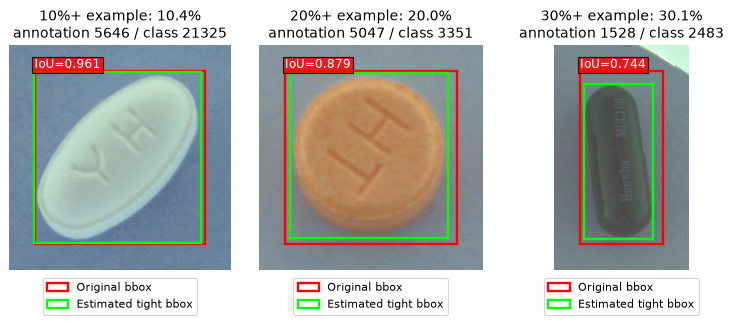

In [245]:
# 앞의 여백 집계 셀을 실행한 뒤 실행한다. 각 구간의 하한에 가장 가까운 예시를 고른다.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

if "bbox_padding_measurements" not in globals():
    raise RuntimeError("바로 위의 bbox 여백 집계 셀을 먼저 실행해 주세요.")

fig, axes = plt.subplots(1, 3, figsize=(9, 4), dpi=85)
bbox_padding_examples = []
for ax, lower, upper in zip(axes, (0.1, 0.2, 0.3), (0.2, 0.3, 1.01), strict=True):
    candidates = bbox_padding_measurements.loc[
        bbox_padding_measurements["status"].eq("estimated")
        & bbox_padding_measurements["padding_ratio"].ge(lower)
        & bbox_padding_measurements["padding_ratio"].lt(upper)
    ].sort_values(["padding_ratio", "image", "annotation_id"])
    if candidates.empty:
        ax.set_title(f"{lower:.0%}: no example")
        ax.axis("off")
        continue
    example = candidates.iloc[0]
    bbox_padding_examples.append(example)
    img_path = PROJECT_ROOT / "data/raw/train_images" / example["image"]
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(img_path)
    left, top, width, height = example["bbox"]
    tight_left, tight_top, tight_width, tight_height = example["tight_bbox"]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            fill=False,
            edgecolor="red",
            linewidth=2,
            label="Original bbox",
        )
    )
    ax.add_patch(
        Rectangle(
            (tight_left, tight_top),
            tight_width,
            tight_height,
            fill=False,
            edgecolor="lime",
            linewidth=2,
            label="Estimated tight bbox",
        )
    )
    ax.text(
        left,
        top,
        f"IoU={example['bbox_iou']:.3f}",
        color="white",
        fontsize=10,
        va="bottom",
        bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
    )
    # 알약 주변을 확대하되 원본 좌표를 유지한다.
    margin = max(width, height) * 0.15
    ax.set_xlim(max(0, left - margin), min(img.shape[1], left + width + margin))
    ax.set_ylim(min(img.shape[0], top + height + margin), max(0, top - margin))
    ax.set_title(
        f"{lower:.0%}+ example: {example['padding_ratio']:.1%}\n"
        f"annotation {example['annotation_id']} / class {example['category_id']}"
    )
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 여백 후보가 포함된 사진 미리보기

- **하는 일:** 지정한 여백 기준 이상인 알약이 있는 사진을 골라 최대 8장까지 전체 화면으로 표시한다.
- **사용 이유:** 확대한 알약만 보지 않고 같은 사진의 다른 알약과 박스의 위치도 함께 확인하기 위해 사용한다.
- **결과 읽기:** 빨간색은 후보의 원본 bbox, 초록색은 추정 bbox, 회색은 나머지 알약이다. IoU는 원본·추정 박스 사이의 값이다. 전체 후보 수와 실제 표시한 사진 수를 구분해 읽는다.
- **실행 조건:** `GrabCut으로 bbox 여백 추정·집계` 후 실행한다. `bbox_padding_threshold` 기본값은 0.20이며 화면 출력만 8장으로 제한한다.


추정 여백 후보 173개 / 사진 120장 중 8장 표시


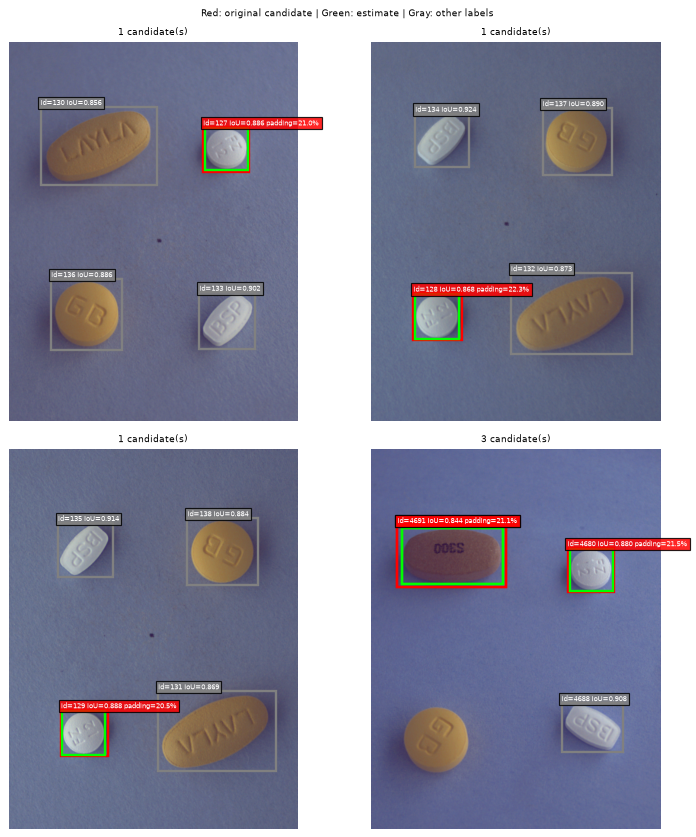

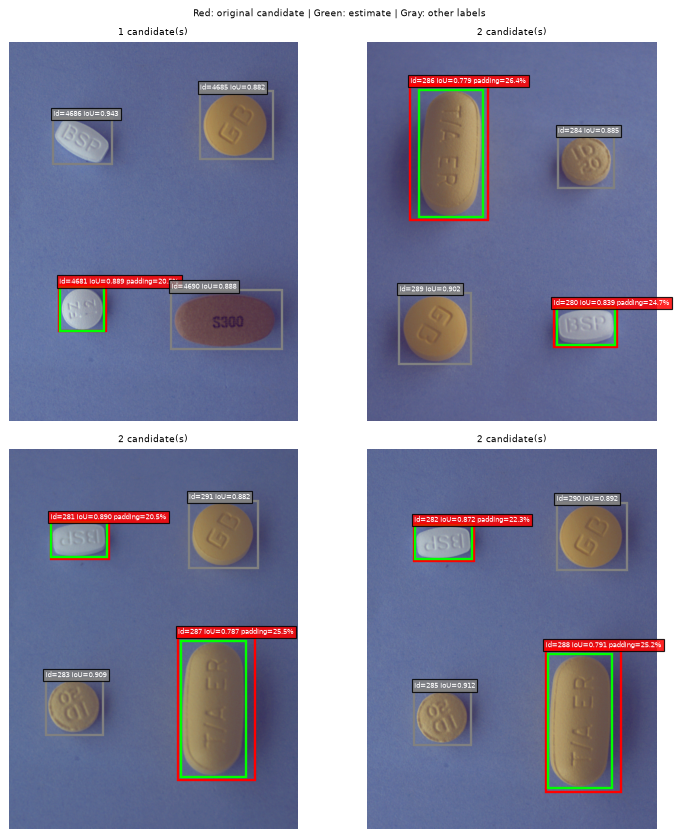

In [244]:
# 여백 후보 사진 중 최대 8장만 작게 표시한다. 저장하거나 원본을 수정하지 않는다.
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

if "bbox_padding_measurements" not in globals() or "bbox_iou" not in bbox_padding_measurements:
    raise RuntimeError("IoU가 추가된 bbox 여백 집계 셀을 먼저 다시 실행해 주세요.")

# 필요하면 0.10 또는 0.30으로 바꾸어 다시 실행한다.
bbox_padding_threshold = 0.20
bbox_padding_candidates = bbox_padding_measurements.loc[
    bbox_padding_measurements["status"].eq("estimated")
    & bbox_padding_measurements["padding_ratio"].ge(bbox_padding_threshold)
].copy()
bbox_padding_image_names = sorted(bbox_padding_candidates["image"].unique())
bbox_padding_image_paths = [
    PROJECT_ROOT / "data/raw/train_images" / name for name in bbox_padding_image_names
]
bbox_padding_image_summary = bbox_padding_candidates.groupby("image", as_index=False).agg(
    candidate_count=("annotation_id", "size"),
    max_padding_ratio=("padding_ratio", "max"),
    min_bbox_iou=("bbox_iou", "min"),
)

# 전체 집계는 유지하고 화면 출력만 제한한다.
bbox_padding_preview_names = bbox_padding_image_names[:8]
# 네 장씩 나누어 출력하며 각 그림의 메모리를 해제한다.
print(
    f"추정 여백 후보 {len(bbox_padding_candidates)}개 / "
    f"사진 {len(bbox_padding_image_names)}장 중 {len(bbox_padding_preview_names)}장 표시"
)
for start in range(0, len(bbox_padding_preview_names), 4):
    image_names = bbox_padding_preview_names[start : start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(9, 10), dpi=85, squeeze=False)
    for ax, image_name in zip(axes.flat, image_names, strict=False):
        img_path = PROJECT_ROOT / "data/raw/train_images" / image_name
        img = cv2.imread(str(img_path))
        if img is None:
            plt.close(fig)
            raise FileNotFoundError(img_path)
        original_height, original_width = img.shape[:2]
        scale = min(1.0, 640 / max(original_height, original_width))
        img = cv2.resize(
            img,
            (max(1, round(original_width * scale)), max(1, round(original_height * scale))),
            interpolation=cv2.INTER_AREA,
        )
        ax.imshow(
            cv2.cvtColor(img, cv2.COLOR_BGR2RGB), extent=(0, original_width, original_height, 0)
        )
        del img
        labels = bbox_padding_measurements.loc[bbox_padding_measurements["image"].eq(image_name)]
        candidate_count = 0
        for row in labels.to_dict("records"):
            is_candidate = (
                row["status"] == "estimated" and row["padding_ratio"] >= bbox_padding_threshold
            )
            color = "red" if is_candidate else "gray"
            left, top, width, height = row["bbox"]
            ax.add_patch(
                Rectangle((left, top), width, height, fill=False, edgecolor=color, linewidth=2)
            )
            label = f"id={row['annotation_id']}"
            if pd.notna(row["bbox_iou"]):
                label += f" IoU={row['bbox_iou']:.3f}"
            else:
                label += " IoU=N/A"
            if is_candidate:
                candidate_count += 1
                tight_left, tight_top, tight_width, tight_height = row["tight_bbox"]
                ax.add_patch(
                    Rectangle(
                        (tight_left, tight_top),
                        tight_width,
                        tight_height,
                        fill=False,
                        edgecolor="lime",
                        linewidth=2,
                    )
                )
                label += f" padding={row['padding_ratio']:.1%}"
            ax.text(
                left,
                top,
                label,
                color="white",
                fontsize=6,
                va="bottom",
                bbox={"facecolor": color, "alpha": 0.85, "pad": 2},
            )
        ax.set_title(f"{candidate_count} candidate(s)", fontsize=8)
        # 모든 bbox를 그린 뒤에도 원본 전체 이미지의 범위를 유지한다.
        ax.set_xlim(0, original_width)
        ax.set_ylim(original_height, 0)
        ax.axis("off")
    for ax in list(axes.flat)[len(image_names) :]:
        ax.axis("off")
    fig.suptitle("Red: original candidate | Green: estimate | Gray: other labels", fontsize=8)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 원본·추정 bbox의 IoU 분포 집계

- **하는 일:** 원본과 추정 bbox 사이의 IoU를 0.1 간격으로 나눠 알약 수와 이미지 수를 집계한다.
- **사용 이유:** 원본 박스와 차이가 큰 알약이 얼마나 있는지 보고, 우선 검토할 IoU 구간을 파악하기 위해 사용한다.
- **결과 읽기:** 이미지는 그 사진에서 판별된 알약 중 최저 IoU로 한 번만 분류한다. 같은 행의 알약 수와 이미지 수는 서로 다른 집계다. 낮은 IoU에는 원본 여백뿐 아니라 추정 오류도 섞일 수 있으며 모델 평가 점수는 아니다.
- **실행 조건:** `GrabCut으로 bbox 여백 추정·집계` 셀을 먼저 실행한다. 빈 구간은 출력에서 숨기고 전체 표는 `bbox_iou_image_counts`에 보관한다.


In [243]:
# 이미지별 최저 IoU로 분류하므로 이미지 수 합계에 중복이 없다.
import pandas as pd
from IPython.display import display

if "bbox_padding_measurements" not in globals() or "bbox_iou" not in bbox_padding_measurements:
    raise RuntimeError("IoU가 추가된 bbox 여백 집계 셀을 먼저 실행해 주세요.")

bbox_iou_valid = bbox_padding_measurements.loc[
    bbox_padding_measurements["status"].eq("estimated")
    & bbox_padding_measurements["bbox_iou"].notna()
].copy()
bbox_iou_per_image = bbox_iou_valid.groupby("image")["bbox_iou"].min()
bbox_iou_edges = [index / 10 for index in range(11)]
bbox_iou_labels = [
    f"{lower:.1f} ≤ IoU < {upper:.1f}" if upper < 1 else f"{lower:.1f} ≤ IoU ≤ {upper:.1f}"
    for lower, upper in zip(bbox_iou_edges[:-1], bbox_iou_edges[1:], strict=True)
]
# 마지막 구간에 IoU=1을 포함한다.
bbox_iou_cut_edges = bbox_iou_edges[:-1] + [1.000000001]
bbox_iou_per_image_bins = pd.cut(
    bbox_iou_per_image, bins=bbox_iou_cut_edges, labels=bbox_iou_labels, right=False
)
bbox_iou_per_label_bins = pd.cut(
    bbox_iou_valid["bbox_iou"], bins=bbox_iou_cut_edges, labels=bbox_iou_labels, right=False
)
bbox_iou_image_counts = pd.DataFrame(
    {
        "이미지 수 (이미지별 최저 IoU)": bbox_iou_per_image_bins.value_counts(sort=False),
        "알약 bbox 수": bbox_iou_per_label_bins.value_counts(sort=False),
    }
).rename_axis("IoU 구간")
bbox_iou_image_counts.loc["합계"] = bbox_iou_image_counts.sum()

bbox_iou_unresolved_names = set(
    bbox_padding_measurements.loc[~bbox_padding_measurements["status"].eq("estimated"), "image"]
)
bbox_iou_unmeasured_names = set(bbox_padding_measurements["image"]) - set(bbox_iou_per_image.index)

print("원본↔보정 bbox IoU 분포 · 이미지는 알약 중 최저 IoU로 분류")
display(bbox_iou_image_counts.loc[bbox_iou_image_counts.gt(0).any(axis=1)])
if bbox_iou_unresolved_names:
    print(
        f"미판별 알약이 포함된 사진 {len(bbox_iou_unresolved_names)}장 / "
        f"전부 미판별인 사진 {len(bbox_iou_unmeasured_names)}장"
    )

원본↔보정 bbox IoU 분포 · 이미지는 알약 중 최저 IoU로 분류


,이미지 수 (이미지별 최저 IoU),알약 bbox 수
IoU 구간,,
0.5 ≤ IoU < 0.6,1,1
0.6 ≤ IoU < 0.7,3,3
0.7 ≤ IoU < 0.8,13,21
0.8 ≤ IoU < 0.9,195,458
0.9 ≤ IoU ≤ 1.0,20,273
합계,232,756


미판별 알약이 포함된 사진 7장 / 전부 미판별인 사진 0장


## 처음 저 IoU였던 후보 다시 추정하기

- **하는 일:** 초기 색상 전용 추정에서 IoU가 0.7 미만이었던 대상을 현재 GrabCut 방식으로 다시 계산하고 대표 8개 이하를 표시한다.
- **사용 이유:** 알약 잘림·그림자 혼입을 개선했는지 같은 대상에서 확인하고, 저장된 이전 박스를 다시 표시하는 문제를 피하기 위해 사용한다.
- **결과 읽기:** 빨간색 원본 박스와 초록색 새 추정을 비교한다. IoU가 개선되어도 기존 검토 대상에 계속 남으며, 화면의 IoU는 원본·새 박스 사이의 값이다. 재추정이 실패하면 이전 박스를 재사용하지 않고 확인 필요 이유를 표시한다.
- **실행 조건:** `GrabCut으로 bbox 여백 추정·집계`를 최신 코드로 실행한 뒤 사용한다. 전체 재추정 결과는 `bbox_padding_recheck`에 남는다.


In [ ]:
# 처음 IoU < 0.7이었던 11개를 실행할 때마다 다시 추정해 표시한다. 이전 계산값은 그리지 않는다.
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

if (
    "bbox_padding_measurements" not in globals()
    or "previous_bbox_iou" not in bbox_padding_measurements
):
    raise RuntimeError("수정된 bbox 여백 집계 셀을 먼저 다시 실행해 주세요.")

if globals().get("BBOX_ESTIMATION_VERSION") != "shadow_chroma_reference_v3":
    raise RuntimeError(
        "최신 그림자 분리 함수가 없습니다. 수정된 bbox 여백 집계 셀을 먼저 실행해 주세요."
    )

bbox_padding_recheck_sources = bbox_padding_measurements.loc[
    bbox_padding_measurements["previous_status"].eq("estimated")
    & bbox_padding_measurements["previous_bbox_iou"].lt(0.7)
].sort_values(["previous_bbox_iou", "image", "annotation_id"])
# 첫 셀의 DataFrame에 예전 추정이 남아 있어도 원본 사진에서 직접 재계산한다.
fresh_rows = []
for _, row in bbox_padding_recheck_sources.iterrows():
    img_path = PROJECT_ROOT / "data/raw/train_images" / row["image"]
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(img_path)
    result = measure_padding(img, row["bbox"])
    fresh_row = row.to_dict()
    # 재추정 실패 시 이전의 초록 박스와 IoU를 재사용하지 않는다.
    fresh_row.update(
        {
            "tight_bbox": None,
            "bbox_iou": float("nan"),
            "review_reason": "",
            "segmentation_agreement": float("nan"),
        }
    )
    fresh_row.update(result)
    if isinstance(result.get("tight_bbox"), list):
        if result.get("estimation_version") != BBOX_ESTIMATION_VERSION:
            raise RuntimeError(
                "이전 추정 함수가 남아 있습니다. bbox 여백 집계 셀을 다시 실행해 주세요."
            )
        fresh_row["bbox_iou"] = calculate_bbox_iou(row["bbox"], result["tight_bbox"])
    fresh_rows.append(fresh_row)
bbox_padding_recheck = pd.DataFrame(
    fresh_rows, columns=bbox_padding_measurements.columns.union(["estimation_version"], sort=False)
)
bbox_recheck_preview_rows = bbox_padding_recheck.head(8)
print(f"재검토 {len(bbox_padding_recheck)}개 / 표시 {len(bbox_recheck_preview_rows)}개")
for number, (_, row) in enumerate(bbox_recheck_preview_rows.iterrows(), 1):
    img_path = PROJECT_ROOT / "data/raw/train_images" / row["image"]
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(img_path)
    original_height, original_width = img.shape[:2]
    scale = min(1.0, 640 / max(original_height, original_width))
    img = cv2.resize(
        img,
        (max(1, round(original_width * scale)), max(1, round(original_height * scale))),
        interpolation=cv2.INTER_AREA,
    )
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    del img
    left, top, width, height = row["bbox"]
    fig, axes = plt.subplots(1, 2, figsize=(9, 6), dpi=85)
    for ax in axes:
        ax.imshow(rgb, extent=(0, original_width, original_height, 0))
        for box, color in ((row["bbox"], "red"), (row.get("tight_bbox"), "lime")):
            if not isinstance(box, list):
                continue
            box_left, box_top, box_width, box_height = box
            ax.add_patch(
                Rectangle(
                    (box_left, box_top),
                    box_width,
                    box_height,
                    fill=False,
                    edgecolor=color,
                    linewidth=2,
                )
            )
        ax.text(
            left,
            top,
            f"IoU={row['bbox_iou']:.3f}",
            color="white",
            va="bottom",
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
        )
        ax.axis("off")
    axes[0].set_xlim(0, original_width)
    axes[0].set_ylim(original_height, 0)
    axes[0].set_title("Full image")
    boxes = [box for box in (row["bbox"], row.get("tight_bbox")) if isinstance(box, list)]
    view_left, view_top = min(box[0] for box in boxes), min(box[1] for box in boxes)
    view_right = max(box[0] + box[2] for box in boxes)
    view_bottom = max(box[1] + box[3] for box in boxes)
    margin = max(view_right - view_left, view_bottom - view_top) * 0.15
    axes[1].set_xlim(max(0, view_left - margin), min(original_width, view_right + margin))
    axes[1].set_ylim(min(original_height, view_bottom + margin), max(0, view_top - margin))
    axes[1].set_title("Zoom")
    fig.suptitle(
        f"{number}/{len(bbox_recheck_preview_rows)} | ID {row['annotation_id']} | "
        f"IoU {row['bbox_iou']:.3f}"
    )
    if row["status"] != "estimated":
        print(f"ID {row['annotation_id']} 확인 필요: {row['review_reason']}")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## GrabCut 보정 전후의 여백 개수 비교

- **하는 일:** 경계 여유를 넣기 전의 같은 추정 몸체 사각형을 기준으로 원본·보정 후의 여백과 IoU를 계산하고, 여백 구간별 개수를 비교한다.
- **사용 이유:** 전후에 서로 다른 기준을 쓰지 않고, 여백 20% 이상 후보를 보정했을 때 분포가 어떻게 달라지는지 확인하기 위해 사용한다.
- **결과 읽기:** 표의 구간은 10% 미만·10~20%·20~30%·30% 이상이며 서로 겹치지 않는다. 같은 알약을 전후 모두 집계하고 불확실한 경우는 양쪽에서 제외한다. 20% 미만은 원본 박스를 유지한다. 여기의 IoU는 공통 추정 몸체 기준이어서 앞의 원본↔보정 박스 IoU와 기준이 다르며, 독립적인 정확도 검증은 아니다.
- **실행 조건:** `GrabCut으로 bbox 여백 추정·집계` 후 실행한다. `bbox_correction_min_padding` 기본값은 0.20이며 비교 결과는 `bbox_compare_results`에 보관하고 원본 JSON은 수정하지 않는다.


In [ ]:
# bbox 여백의 보정 전후 개수 비교: 같은 GrabCut 몸체 경계를 참조한다.
import pandas as pd
from IPython.display import display

if globals().get("BBOX_ESTIMATION_VERSION") != "shadow_chroma_reference_v3":
    raise RuntimeError("수정된 bbox 여백 집계 셀을 먼저 실행해 주세요.")

# 이 기준 이상인 알약만 보정한다. 원본 JSON은 변경하지 않는다.
bbox_correction_min_padding = 0.20
if not 0 <= bbox_correction_min_padding <= 1:
    raise ValueError("보정 기준은 0~1 사이로 설정해 주세요.")
if (
    "bbox_padding_measurements" not in globals()
    or "foreground_bbox" not in bbox_padding_measurements
    or bbox_padding_measurements.attrs.get("estimation_version") != BBOX_ESTIMATION_VERSION
):
    bbox_padding_measurements, bbox_padding_summary = count_bbox_padding()


def bbox_padding_fraction(box: list[float], reference: list[float]) -> float:
    """몸체의 최소 사각형 밖에 남은 박스 면적의 비율을 계산한다."""
    left, top, width, height = box
    ref_left, ref_top, ref_width, ref_height = reference
    intersection_width = max(0.0, min(left + width, ref_left + ref_width) - max(left, ref_left))
    intersection_height = max(0.0, min(top + height, ref_top + ref_height) - max(top, ref_top))
    area = width * height
    return 1 - intersection_width * intersection_height / area if area > 0 else float("nan")


bbox_compare_rows = []
for row in bbox_padding_measurements.to_dict("records"):
    # 양쪽 모두 같은 알약을 비교한다. 경계가 불확실한 결과는 양쪽 집계에서 제외한다.
    if row["status"] != "estimated" or not isinstance(row.get("foreground_bbox"), list):
        continue
    before = row["bbox"]
    reference = row["foreground_bbox"]
    proposal = row["tight_bbox"]
    padding_before = bbox_padding_fraction(before, reference)
    iou_before = calculate_bbox_iou(before, reference)
    corrected = (
        padding_before >= bbox_correction_min_padding
        and calculate_bbox_iou(proposal, reference) > iou_before
    )
    after = proposal if corrected else before
    bbox_compare_rows.append(
        {
            **row,
            "bbox_before": before,
            "bbox_after": after,
            "corrected": corrected,
            "padding_before": padding_before,
            "padding_after": bbox_padding_fraction(after, reference),
            "iou_before": iou_before,
            "iou_after": calculate_bbox_iou(after, reference),
        }
    )
bbox_compare_columns = [
    "image",
    "annotation_id",
    "bbox_before",
    "bbox_after",
    "corrected",
    "padding_before",
    "padding_after",
    "iou_before",
    "iou_after",
]
bbox_compare_results = pd.DataFrame(bbox_compare_rows)
if bbox_compare_results.empty:
    bbox_compare_results = pd.DataFrame(columns=bbox_compare_columns)
bbox_compare_results.attrs["estimation_version"] = BBOX_ESTIMATION_VERSION
bbox_compare_results.attrs["correction_threshold"] = bbox_correction_min_padding
bbox_padding_bin_edges = [0.0, 0.1, 0.2, 0.3, 1.000000001]
bbox_padding_bin_labels = ["0~10% 미만", "10~20% 미만", "20~30% 미만", "30% 이상"]
bbox_padding_before_after_counts = pd.DataFrame(
    {
        "보정 전 알약 수": pd.cut(
            bbox_compare_results["padding_before"],
            bins=bbox_padding_bin_edges,
            labels=bbox_padding_bin_labels,
            right=False,
        ).value_counts(sort=False),
        "보정 후 알약 수": pd.cut(
            bbox_compare_results["padding_after"],
            bins=bbox_padding_bin_edges,
            labels=bbox_padding_bin_labels,
            right=False,
        ).value_counts(sort=False),
    }
).rename_axis("추정 여백 비율")
bbox_padding_before_after_counts.loc["합계"] = bbox_padding_before_after_counts.sum()
bbox_corrected_rows = bbox_compare_results.loc[bbox_compare_results["corrected"].eq(True)].copy()
bbox_comparison_excluded = len(bbox_padding_measurements) - len(bbox_compare_results)

print(f"비교 {len(bbox_compare_results)}개 / 불확실해 제외 {bbox_comparison_excluded}개")
print(
    f"여백 {bbox_correction_min_padding:.0%} 이상 보정: 알약 {len(bbox_corrected_rows)}개 / "
    f"사진 {bbox_corrected_rows['image'].nunique()}장"
)
display(bbox_padding_before_after_counts)
print("IoU·여백의 공통 기준은 GrabCut 추정 몸체이며 모델 평가 점수는 아닙니다.")

## 보정 전후 이미지를 작게 나란히 비교

- **하는 일:** 보정 대상 사진 중 재현 가능한 무작위 예시를 최대 8장 골라, 긴 변 640픽셀 이하의 작은 전후 비교 그림을 만든다.
- **사용 이유:** 개수 변화뿐 아니라 알약이 잘리지 않았는지 직접 확인하면서 대량 이미지 출력의 메모리 사용을 줄이기 위해 사용한다.
- **결과 읽기:** 왼쪽은 원본 bbox, 오른쪽은 GrabCut 보정 bbox다. 각 박스의 라벨 ID·IoU·여백 비율을 비교한다. 양쪽 IoU는 같은 추정 몸체 사각형 기준이며, 대표 그림 수와 전체 보정 사진 수는 다르다.
- **실행 조건:** `GrabCut 보정 전후의 여백 개수 비교` 후 실행한다. `bbox_preview_count`로 예시 수, `bbox_preview_max_side`로 크기, `bbox_preview_seed`로 선택을 조절한다. 집계 대상이나 원본 라벨에는 영향을 주지 않는다.


In [ ]:
# 보정 이미지 중 최대 8장만 작은 크기로 전후 비교한다. 전체 집계에는 영향을 주지 않는다.
import random

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

if "bbox_compare_results" not in globals():
    raise RuntimeError("바로 위의 bbox 여백 보정 전후 집계 셀을 먼저 실행해 주세요.")
if bbox_compare_results.attrs.get("estimation_version") != globals().get("BBOX_ESTIMATION_VERSION"):
    raise RuntimeError("이전 비교 결과입니다. 바로 위의 보정 전후 집계 셀을 다시 실행해 주세요.")

if bbox_compare_results.attrs.get("correction_threshold") != bbox_correction_min_padding:
    raise RuntimeError("보정 기준이 바뀌었습니다. 바로 위의 집계 셀을 다시 실행해 주세요.")

# 표시 개수는 5~10장 정도로 조절한다. 같은 seed는 같은 예시를 선택한다.
bbox_preview_count = 8
bbox_preview_max_side = 640
bbox_preview_seed = 42
if bbox_preview_count < 1 or bbox_preview_max_side < 1:
    raise ValueError("표시 개수와 최대 이미지 크기는 양수여야 합니다.")
bbox_corrected_rows = bbox_compare_results.loc[bbox_compare_results["corrected"].eq(True)]
bbox_corrected_image_names = sorted(bbox_corrected_rows["image"].unique())
bbox_corrected_image_count = len(bbox_corrected_image_names)
bbox_preview_names = sorted(
    random.Random(bbox_preview_seed).sample(
        bbox_corrected_image_names, min(bbox_preview_count, bbox_corrected_image_count)
    )
)
print(f"미리보기 {len(bbox_preview_names)}장 / 전체 {bbox_corrected_image_count}장")
for number, image_name in enumerate(bbox_preview_names, 1):
    labels = bbox_corrected_rows.loc[bbox_corrected_rows["image"].eq(image_name)]
    img_path = PROJECT_ROOT / "data/raw/train_images" / image_name
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(img_path)
    # 읽은 사진을 즉시 축소하고 bbox에도 실제 가로·세로 축소 비율을 적용한다.
    original_height, original_width = img.shape[:2]
    scale = min(1.0, bbox_preview_max_side / max(original_height, original_width))
    preview_width = max(1, round(original_width * scale))
    preview_height = max(1, round(original_height * scale))
    img = cv2.resize(img, (preview_width, preview_height), interpolation=cv2.INTER_AREA)
    scale_x, scale_y = preview_width / original_width, preview_height / original_height
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    del img
    fig, axes = plt.subplots(1, 2, figsize=(9, 6), dpi=85)
    for ax, stage, color, title in zip(
        axes, ("before", "after"), ("red", "lime"), ("Before", "After GrabCut"), strict=True
    ):
        ax.imshow(rgb)
        for row in labels.to_dict("records"):
            left, top, width, height = row[f"bbox_{stage}"]
            left, width = left * scale_x, width * scale_x
            top, height = top * scale_y, height * scale_y
            ax.add_patch(
                Rectangle((left, top), width, height, fill=False, edgecolor=color, linewidth=2)
            )
            ax.text(
                left,
                top,
                f"ID {row['annotation_id']} | IoU={row[f'iou_{stage}']:.3f}\n"
                f"padding={row[f'padding_{stage}']:.1%}",
                color="white",
                fontsize=6,
                va="bottom",
                bbox={
                    "facecolor": "darkred" if stage == "before" else "darkgreen",
                    "alpha": 0.85,
                    "pad": 2,
                },
            )
        ax.set_xlim(0, preview_width)
        ax.set_ylim(preview_height, 0)
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"Example {number}/{len(bbox_preview_names)} | {len(labels)} corrected pill(s)")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## GrabCut 보정본을 processed에 실제 저장

- **하는 일:** 여백 20% 이상 보정 후보의 사진과 연결된 모든 JSON을 `data/processed/bbox_grabcut/`에 복사하고, 선택한 라벨의 bbox와 area를 보정값으로 바꾼다.
- **사용 이유:** 시각화용 메모리 값으로만 남아 있던 보정을 실제 데이터 파일에 반영하면서 원본과 기존 보정 기록을 보존하기 위해 사용한다.
- **결과 읽기:** 저장한 이미지·JSON·보정 bbox 개수가 나온다. `train_images`는 픽셀을 바꾸지 않은 사진 복사본, `train_annotations`는 같은 사진의 다른 라벨까지 포함한 전체 JSON이다. 변경 전후 좌표·IoU·여백과 해시는 `correction_records` 및 `manifest.json`에 남는다. 자동 추정을 적용한 것이며 별도의 수동 검수 완료를 뜻하지 않는다.
- **실행 조건:** `GrabCut 보정 전후의 여백 개수 비교`를 최신 코드로 실행한 뒤 사용한다. 원본 JSON과 사진은 읽기만 하며, 저장 중 원본 변경이 없는지 해시로 확인한다. 같은 결과로 다시 실행하면 기존 파일을 검증하고 재사용하며, 내용이 다르면 덮어쓰지 않는다.


In [ ]:
# GrabCut 보정을 원본과 분리한 이미지·JSON 복사본에 실제 반영한다.
import copy
import hashlib
import json
import shutil
import tempfile
from datetime import UTC, datetime
from pathlib import Path

import pandas as pd


def file_sha256(path: Path) -> str:
    """큰 이미지도 작은 블록으로 읽어 파일의 해시를 계산한다."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def prepare_grabcut_targets(comparison: pd.DataFrame, root: Path) -> dict:
    """검증된 보정 행을 원본 JSON 상대 경로와 라벨 ID로 묶는다."""
    if comparison.attrs.get("estimation_version") != BBOX_ESTIMATION_VERSION:
        raise ValueError("최신 보정 전후 집계 셀을 먼저 실행해 주세요.")
    threshold = comparison.attrs.get("correction_threshold")
    if threshold is None:
        raise ValueError("보정 기준이 없는 결과는 저장할 수 없습니다.")
    targets = {}
    annotation_root = (root / "data/raw/train_annotations").resolve()
    for row in comparison.loc[comparison["corrected"].eq(True)].to_dict("records"):
        if row["status"] != "estimated" or row["padding_before"] < threshold:
            raise ValueError("경계가 불확실하거나 기준에 못 미치는 보정이 포함되어 있습니다.")
        source = (root / row["source"]).resolve()
        relative = source.relative_to(annotation_root).as_posix()
        key = (relative, int(row["annotation_id"]))
        if key in targets:
            raise ValueError(f"중복된 보정 대상입니다: {key}")
        after = row["bbox_after"]
        if len(after) != 4 or any(float(value) != int(value) for value in after):
            raise ValueError(f"정수 xywh 좌표가 필요합니다: {key}")
        after = list(map(int, after))
        left, top, width, height = after
        body_left, body_top, body_width, body_height = row["foreground_bbox"]
        if (
            min(left, top) < 0
            or min(width, height) <= 0
            or left > body_left
            or top > body_top
            or left + width < body_left + body_width
            or top + height < body_top + body_height
            or row["iou_after"] <= row["iou_before"]
        ):
            raise ValueError(f"몸체 포함·IoU 개선 검사를 통과하지 못했습니다: {key}")
        targets[key] = {**row, "bbox_after": after}
    if not targets:
        raise ValueError("저장할 GrabCut 보정 대상이 없습니다.")
    return targets


def update_grabcut_document(data: dict, relative: str, targets: dict) -> tuple[dict, list]:
    """선택한 라벨의 bbox·area만 바꾸고 나머지 필드는 그대로 유지한다."""
    updated = copy.deepcopy(data)
    images = {image["id"]: image for image in data["images"]}
    changes = []
    for label in updated["annotations"]:
        target = targets.get((relative, int(label["id"])))
        if target is None:
            continue
        image = images[label["image_id"]]
        if (
            image["file_name"] != target["image"]
            or label["category_id"] != target["category_id"]
            or label["bbox"] != target["bbox_before"]
        ):
            raise ValueError(f"집계 이후 입력 라벨이 달라졌습니다: {relative}")
        if label.get("segmentation"):
            raise ValueError(f"segmentation이 있는 라벨은 별도 검토가 필요합니다: {relative}")
        left, top, width, height = target["bbox_after"]
        if left + width > image["width"] or top + height > image["height"]:
            raise ValueError(f"보정 좌표가 이미지 범위를 벗어났습니다: {relative}")
        changes.append(
            {
                "annotation_id": int(label["id"]),
                "category_id": int(label["category_id"]),
                "image": image["file_name"],
                "before_bbox": label["bbox"],
                "after_bbox": target["bbox_after"],
                "before_area": label.get("area"),
                "after_area": width * height,
                "foreground_bbox": target["foreground_bbox"],
                "padding_before": float(target["padding_before"]),
                "padding_after": float(target["padding_after"]),
                "iou_before": float(target["iou_before"]),
                "iou_after": float(target["iou_after"]),
            }
        )
        label["bbox"] = target["bbox_after"]
        label["area"] = width * height
    return updated, changes


def plan_grabcut_documents(root: Path, targets: dict) -> tuple[list, dict]:
    """대상 사진의 모든 라벨을 모으고 기존 수정본이 있으면 입력으로 이어받는다."""
    annotation_root = root / "data/raw/train_annotations"
    selected_images = {row["image"] for row in targets.values()}
    plans = []
    raw_hashes = {}
    for source in sorted(annotation_root.rglob("*.json")):
        relative = source.relative_to(annotation_root).as_posix()
        raw_hashes[source] = file_sha256(source)
        correction_root = next(
            (
                root / "data/processed" / folder
                for folder in ("bbox_area", "bbox_range")
                if (root / "data/processed" / folder / "corrected_annotations" / relative).is_file()
            ),
            None,
        )
        input_path = (
            correction_root / "corrected_annotations" / relative
            if correction_root is not None
            else source
        )
        data = json.loads(input_path.read_text(encoding="utf-8"))
        names = {image["file_name"] for image in data["images"]}
        if not names.intersection(selected_images):
            continue
        if not names.issubset(selected_images):
            raise ValueError(f"다른 사진이 함께 묶인 JSON은 별도 확인이 필요합니다: {relative}")
        updated, changes = update_grabcut_document(data, relative, targets)
        inherited_path = (
            correction_root / "correction_records" / relative
            if correction_root is not None
            else None
        )
        inherited = (
            json.loads(inherited_path.read_text(encoding="utf-8"))
            if inherited_path is not None and inherited_path.is_file()
            else None
        )
        plans.append(
            {
                "relative": relative,
                "input_path": input_path,
                "input_sha256": file_sha256(input_path),
                "raw_sha256": raw_hashes[source],
                "before": data,
                "after": updated,
                "changes": changes,
                "inherited_record": inherited,
            }
        )
    matched = {
        (plan["relative"], row["annotation_id"]) for plan in plans for row in plan["changes"]
    }
    if matched != set(targets):
        raise ValueError("보정 대상과 실제 JSON 라벨의 연결이 일치하지 않습니다.")
    return plans, raw_hashes


def verify_grabcut_export(output: Path, manifest: dict) -> None:
    """저장된 모든 사진·라벨·수정 기록이 기록된 해시와 같은지 검증한다."""
    for item in manifest["files"]:
        if file_sha256(output / item["path"]) != item["sha256"]:
            raise ValueError(f"복사본 검증 실패: {item['path']}")


def export_grabcut_copies(
    comparison: pd.DataFrame, root: Path, output: Path, excluded_count: int = 0
) -> dict:
    """원본을 보존하고 보정된 전체 라벨과 사진을 별도 데이터셋으로 저장한다."""
    root, output = root.resolve(), output.resolve()
    processed_root = (root / "data/processed").resolve()
    if output == processed_root or not output.is_relative_to(processed_root):
        raise ValueError("processed 아래의 별도 하위 폴더를 지정해 주세요.")
    targets = prepare_grabcut_targets(comparison, root)
    plans, raw_hashes = plan_grabcut_documents(root, targets)
    image_names = sorted({row["image"] for row in targets.values()})
    image_sources = {
        name: (root / "data/raw/train_images" / name).resolve() for name in image_names
    }
    image_hashes = {}
    for name, source in image_sources.items():
        source.relative_to((root / "data/raw/train_images").resolve())
        image_hashes[name] = file_sha256(source)
    signature_data = {
        "version": BBOX_ESTIMATION_VERSION,
        "threshold": comparison.attrs["correction_threshold"],
        "images": image_hashes,
        "annotations": [
            (plan["relative"], plan["input_sha256"], plan["changes"]) for plan in plans
        ],
    }
    signature = hashlib.sha256(json.dumps(signature_data, sort_keys=True).encode()).hexdigest()
    if output.exists():
        manifest_path = output / "manifest.json"
        if not manifest_path.is_file():
            raise FileExistsError("기존 폴더를 덮어쓰지 않습니다. 다른 저장 경로를 지정해 주세요.")
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if manifest["signature"] != signature:
            raise FileExistsError("기존 저장 결과와 다릅니다. 다른 저장 경로를 지정해 주세요.")
        verify_grabcut_export(output, manifest)
        return manifest
    processed_root.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".grabcut-export-", dir=processed_root) as temporary:
        stage = Path(temporary) / "dataset"
        stage.mkdir()
        files = []
        for name, source in image_sources.items():
            destination = stage / "train_images" / name
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)
            if file_sha256(destination) != image_hashes[name]:
                raise ValueError(f"이미지 복사 검증 실패: {name}")
            files.append(
                {"path": destination.relative_to(stage).as_posix(), "sha256": image_hashes[name]}
            )
        for plan in plans:
            destination = stage / "train_annotations" / plan["relative"]
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_text(
                json.dumps(plan["after"], ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
            )
            record = {
                "raw_source": f"data/raw/train_annotations/{plan['relative']}",
                "raw_sha256": plan["raw_sha256"],
                "input_source": plan["input_path"].relative_to(root).as_posix(),
                "input_sha256": plan["input_sha256"],
                "method": BBOX_ESTIMATION_VERSION,
                "changes": plan["changes"],
                "inherited_record": plan["inherited_record"],
            }
            record_path = stage / "correction_records" / plan["relative"]
            record_path.parent.mkdir(parents=True, exist_ok=True)
            record_path.write_text(
                json.dumps(record, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
            )
            for saved in (destination, record_path):
                files.append(
                    {"path": saved.relative_to(stage).as_posix(), "sha256": file_sha256(saved)}
                )
            if json.loads(destination.read_text(encoding="utf-8")) != plan["after"]:
                raise ValueError("JSON 저장 후 내용이 달라졌습니다.")
        if any(file_sha256(source) != digest for source, digest in raw_hashes.items()):
            raise ValueError("작업 중 원본 JSON의 변경이 감지되었습니다.")
        if any(file_sha256(image_sources[name]) != digest for name, digest in image_hashes.items()):
            raise ValueError("작업 중 원본 이미지의 변경이 감지되었습니다.")
        if any(file_sha256(plan["input_path"]) != plan["input_sha256"] for plan in plans):
            raise ValueError("작업 중 입력 수정본의 변경이 감지되었습니다.")
        manifest = {
            "method": BBOX_ESTIMATION_VERSION,
            "signature": signature,
            "created_at_utc": datetime.now(UTC).isoformat(),
            "threshold": comparison.attrs["correction_threshold"],
            "images": len(image_names),
            "annotation_files": len(plans),
            "corrected_annotations": len(targets),
            "all_annotations_in_copies": sum(len(plan["after"]["annotations"]) for plan in plans),
            "compared_annotations": len(comparison),
            "excluded_annotations": excluded_count,
            "inherited_annotation_files": sum(
                plan["input_path"].is_relative_to(processed_root) for plan in plans
            ),
            "raw_unchanged_verified": True,
            "parameters": {
                "seed": 42,
                "iterations": 4,
                "max_crop_size": 360,
                "minimum_padding_pixels": 4,
                "minimum_padding_short_side_ratio": 0.01,
                "foreground_seed_ratios": [0.12, 0.20],
                "shadow_score_threshold": 0.25,
                "shadow_darkness_ratio": 0.95,
            },
            "files": files,
        }
        (stage / "manifest.json").write_text(
            json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
        )
        verify_grabcut_export(stage, manifest)
        stage.rename(output)
    return manifest


if "bbox_compare_results" not in globals():
    raise RuntimeError("GrabCut 보정 전후의 여백 개수 비교 셀을 먼저 실행해 주세요.")
bbox_export_dir = PROJECT_ROOT / "data/processed/bbox_grabcut"
bbox_export_manifest = export_grabcut_copies(
    bbox_compare_results, PROJECT_ROOT, bbox_export_dir, bbox_comparison_excluded
)
print(
    f"저장 완료: 이미지 {bbox_export_manifest['images']}장 / "
    f"JSON {bbox_export_manifest['annotation_files']}개 / "
    f"보정 bbox {bbox_export_manifest['corrected_annotations']}개"
)
print("저장 위치: data/processed/bbox_grabcut / 원본 변경 없음 검증 완료")

## 미분류 이미지 전체 보기 — bbox 포함

- **하는 일:** 미분류가 있는 사진을 중복 없이 최대 8장 골라 사진 전체를 한 장씩 보여준다. 빨강은 현재 라벨 bbox, 초록은 GrabCut 추정 bbox, 회색은 같은 사진의 다른 알약 bbox이다.
- **사용 이유:** 캡슐 주변만 자른 그림에서 놓칠 수 있는 실제 알약의 위치와 다른 알약과의 관계를 전체 사진으로 확인하기 위해 사용한다.
- **결과 읽기:** 사진마다 대상 라벨 ID·클래스·확인 사유와 박스 간 IoU가 표시된다. 기존 미분류 8개 중 라벨 5178은 `bbox_area` 보정 후 정상 분류되어 최신 집계에서는 7장이다. 원본 좌표 오류(5662), 추정 누락(2944), 추가 여유에 따른 제외(58·5029), 미세한 하단 초과(3000·5578), 사진 끝 경계 접촉(4192)을 구분해 확인한다.
- **실행 조건:** 앞부분의 최신 `GrabCut으로 bbox 여백 추정·집계` 셀을 먼저 실행한 뒤 이 마지막 셀을 실행한다. 사진은 자르지 않고 최대 480×640으로 축소하며, 그림은 표시 후 닫아 메모리 사용을 줄인다. 이미지와 원본·수정본 JSON은 변경하지 않는다. 앞으로 추가하는 코드는 노트북 맨 아래에 둔다.


In [ ]:
# 미분류 이미지마다 사진 전체에 bbox를 표시한다. 최대 8장을 한 장씩 보여준다.
import os
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

if "bbox_padding_measurements" not in globals():
    raise RuntimeError("앞부분의 GrabCut bbox 여백 추정·집계 셀을 먼저 실행해 주세요.")
if bbox_padding_measurements.attrs.get("estimation_version") != globals().get(
    "BBOX_ESTIMATION_VERSION"
):
    raise RuntimeError("현재 코드로 bbox 여백 추정·집계 셀을 다시 실행해 주세요.")

bbox_padding_needs_review = bbox_padding_measurements.loc[
    bbox_padding_measurements["status"].ne("estimated")
].copy()
bbox_review_images = (
    bbox_padding_needs_review.sort_values(["source", "annotation_id"])["image"]
    .drop_duplicates()
    .head(8)
    .tolist()
)
bbox_review_notes = {
    2944: "캡슐 윗부분 누락",
    5662: "원본 bbox가 배경에 위치",
    3000: "추정 하단 2px 초과",
    58: "추가 여유로 경계 밖",
    5029: "추가 여유로 경계 밖",
    5578: "추정 하단 1px 초과",
    4192: "사진 우측 끝 경계 접촉",
}
bbox_review_font = None
for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
    try:
        bbox_review_font = font_manager.FontProperties(
            fname=font_manager.findfont(font_name, fallback_to_default=False)
        )
        break
    except ValueError:
        continue
if bbox_review_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        bbox_review_font = font_manager.FontProperties(fname=font_path)

print(
    f"미분류 알약 {len(bbox_padding_needs_review)}개 / "
    f"이미지 {bbox_padding_needs_review['image'].nunique()}장 / "
    f"전체 사진 표시 {len(bbox_review_images)}장"
)
for number, image_name in enumerate(bbox_review_images, 1):
    review_rows = bbox_padding_needs_review.loc[
        bbox_padding_needs_review["image"].eq(image_name)
    ].to_dict("records")
    image_labels = bbox_padding_measurements.loc[
        bbox_padding_measurements["image"].eq(image_name)
    ].to_dict("records")
    target_ids = {row["annotation_id"] for row in review_rows}
    with Image.open(PROJECT_ROOT / "data/raw/train_images" / image_name) as image:
        image_width, image_height = image.size
        # 자르지 않고 사진 전체를 축소한다. bbox는 원본 좌표계를 유지한다.
        preview = image.convert("RGB")
        preview.thumbnail((480, 640))
    fig, ax = plt.subplots(figsize=(5.4, 7.1), dpi=85, layout="constrained")
    ax.imshow(preview, extent=(0, image_width, image_height, 0))
    for label in image_labels:
        if label["annotation_id"] in target_ids:
            continue
        left, top, width, height = label["bbox"]
        ax.add_patch(
            Rectangle(
                (left, top),
                width,
                height,
                fill=False,
                edgecolor="silver",
                linewidth=1,
                alpha=0.8,
            )
        )
    captions, iou_labels = [], []
    for row in review_rows:
        for box, color in ((row["bbox"], "red"), (row.get("tight_bbox"), "lime")):
            if isinstance(box, list):
                left, top, width, height = box
                ax.add_patch(
                    Rectangle(
                        (left, top),
                        width,
                        height,
                        fill=False,
                        edgecolor=color,
                        linewidth=1.6,
                    )
                )
        left, top = row["bbox"][:2]
        ax.text(
            left,
            top,
            f"ID {row['annotation_id']}",
            fontsize=8,
            color="white",
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 1.5},
        )
        reason = bbox_review_notes.get(row["annotation_id"], row.get("review_reason", ""))
        if bbox_review_font is not None:
            captions.append(f"라벨 {row['annotation_id']} · 클래스 {row['category_id']}\n{reason}")
        else:
            captions.append(f"ID {row['annotation_id']} | {row['status']}")
        iou_labels.append(
            f"ID {row['annotation_id']}: BBox IoU {row.get('bbox_iou', float('nan')):.3f}"
        )
    ax.text(
        0.02,
        0.02,
        "\n".join(iou_labels),
        transform=ax.transAxes,
        color="white",
        fontsize=8,
        bbox={"facecolor": "black", "alpha": 0.65, "pad": 2},
    )
    title = f"[{number}/{len(bbox_review_images)}] " + "\n".join(captions)
    legend = (
        "빨강: 현재 라벨 · 초록: GrabCut 추정 · 회색: 다른 알약"
        if bbox_review_font is not None
        else "Red: label | Green: GrabCut | Gray: other pills"
    )
    ax.set_title(title, fontproperties=bbox_review_font, fontsize=10)
    fig.suptitle(textwrap.fill(legend, 45), fontproperties=bbox_review_font, fontsize=9)
    ax.set_xlim(0, image_width)
    ax.set_ylim(image_height, 0)
    ax.axis("off")
    plt.show()
    plt.close(fig)

## 미분류 1·3·4·5·6번 GrabCut 보정 및 전체 이미지 확인

- **하는 일:** 바로 앞의 미분류 7장 번호를 고정해 라벨 2944(1번), 3000(3번), 58(4번), 5029(5번), 5578(6번)을 재보정한다. 2번(5662)과 7번(4192)은 적용 대상에서 제외한다.
- **사용 이유:** 긴 캡슐에는 긴 축을 따라 두 부분을 포함하는 전경 씨앗을 주고, 어두운 캡슐에 색도 기반 강제 배경을 적용하지 않아 윗부분 누락을 줄인다. 나머지는 기존 그림자 분리를 유지하며, 몸체 경계 초과와 추가 안전 여유를 별도로 판단한다. 몸체의 3픽셀 이내 초과는 반올림·미세 경계 차이로 허용하되 두 초기 조건의 마스크·bbox 일치도와 탐색 경계·면적 검사는 유지한다.
- **결과 읽기:** 기존 7개에 대한 별도 재검토 결과이며 5개를 보정하고 2개를 남긴다. 사진 전체에 이전 GrabCut 추정(주황 점선)과 보정 bbox(초록)를 함께 그린다. 그림 안 IoU는 **새로 추정한 몸체 bbox를 공통 기준으로 한 이전·새 추정 bbox의 IoU**이며, 독립 정답이나 모델 평가 점수가 아니다. 경계 검사만 달라진 사례는 IoU가 같을 수 있다. 중복 표나 이미지 파일명 목록은 출력하지 않는다.
- **실행 조건:** 앞부분의 최신 GrabCut 집계와 바로 앞 전체 이미지 확인 셀을 실행한 뒤 사용한다. 원본과 기존 보정본을 보존하고 `data/processed/bbox_grabcut/review_fixed/`에 사진 복사본·같은 사진의 전체 라벨 JSON·보정 이력·manifest를 저장한다. 기존 GrabCut 보정이 있는 다른 알약은 그 값을 이어받는다. 같은 결과로 재실행하면 해시를 검증해 재사용하고 다른 내용은 덮어쓰지 않는다. 사진은 최대 480×640으로 축소해 5장만 표시하고 그림을 닫는다. bbox가 표시된 확인용 이미지는 `review_fixed/previews/`에 따로 저장하며 학습용 사진은 픽셀을 바꾸지 않는다.


In [ ]:
# 미분류 7장 중 2·7번을 제외한 5장을 재보정하고 복사본 저장 후 전체 사진으로 확인한다.
import copy
import hashlib
import json
from datetime import UTC, datetime
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

if "bbox_padding_measurements" not in globals() or "mark_shadow_background" not in globals():
    raise RuntimeError("앞부분의 최신 GrabCut 여백 집계 셀을 먼저 실행해 주세요.")

REVIEW_FIX_METHOD = "grabcut_review_body_boundary_v4"
REVIEW_FIX_NUMBERS = {2944: 1, 3000: 3, 58: 4, 5029: 5, 5578: 6}
REVIEW_KEEP_IDS = {5662, 4192}
REVIEW_FIX_PARAMETERS = {
    "seed": 42,
    "iterations": 6,
    "max_crop_size": 360,
    "long_axis_aspect_ratio": 1.6,
    "long_seed_ratios": [[0.18, 0.32], [0.22, 0.38]],
    "round_seed_ratios": [[0.12, 0.12], [0.20, 0.20]],
    "minimum_padding_pixels": 4,
    "padding_short_side_ratio": 0.01,
    "body_boundary_tolerance_pixels": 3,
    "minimum_box_agreement": 0.90,
    "minimum_mask_agreement": 0.90,
}


def refine_review_grabcut(img: np.ndarray, bbox: list[float], cfg: dict) -> dict:
    """긴 캡슐의 전경 씨앗을 확장하고 몸체 경계와 안전 여유를 분리해 검사한다."""
    left, top, width, height = map(int, bbox)
    image_height, image_width = img.shape[:2]
    if (
        min(left, top) < 0
        or min(width, height) <= 0
        or left + width > image_width
        or top + height > image_height
    ):
        raise ValueError("원본 bbox가 유효하지 않아 재보정을 중단합니다.")
    margin = max(20, round(max(width, height) * 0.25))
    crop_left, crop_top = max(0, left - margin), max(0, top - margin)
    crop_right = min(image_width, left + width + margin)
    crop_bottom = min(image_height, top + height + margin)
    original_crop = img[crop_top:crop_bottom, crop_left:crop_right]
    scale = min(1.0, cfg["max_crop_size"] / max(original_crop.shape[:2]))
    crop = cv2.resize(original_crop, None, fx=scale, fy=scale)
    scale_x, scale_y = (
        crop.shape[1] / original_crop.shape[1],
        crop.shape[0] / original_crop.shape[0],
    )
    rectangle = (
        round((left - crop_left) * scale_x),
        round((top - crop_top) * scale_y),
        round((left + width - crop_left) * scale_x),
        round((top + height - crop_top) * scale_y),
    )
    rect_left, rect_top, rect_right, rect_bottom = rectangle
    center = (round((rect_left + rect_right) / 2), round((rect_top + rect_bottom) / 2))
    long_axis = max(width, height) / min(width, height) >= cfg["long_axis_aspect_ratio"]
    seed_ratios = cfg["long_seed_ratios"] if long_axis else cfg["round_seed_ratios"]
    masks, boxes = [], []
    for short_ratio, long_ratio in seed_ratios:
        mask = np.full(crop.shape[:2], cv2.GC_PR_BGD, dtype=np.uint8)
        mask[rect_top:rect_bottom, rect_left:rect_right] = cv2.GC_PR_FGD
        mask[:3, :] = mask[-3:, :] = mask[:, :3] = mask[:, -3:] = cv2.GC_BGD
        radii = (
            max(
                2,
                round((rect_right - rect_left) * (short_ratio if height >= width else long_ratio)),
            ),
            max(
                2,
                round((rect_bottom - rect_top) * (long_ratio if height >= width else short_ratio)),
            ),
        )
        cv2.ellipse(mask, center, radii, 0, 0, 360, cv2.GC_FGD, -1)
        # 어두운 긴 캡슐은 씨앗이 두 부분을 포함하게 하고 색도 기반 강제 배경을 적용하지 않는다.
        if not long_axis:
            mark_shadow_background(crop, mask, rectangle)
        cv2.setRNGSeed(cfg["seed"])
        cv2.grabCut(
            crop,
            mask,
            None,
            np.zeros((1, 65)),
            np.zeros((1, 65)),
            cfg["iterations"],
            cv2.GC_INIT_WITH_MASK,
        )
        foreground = np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8)
        foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, np.ones((3, 3), dtype=np.uint8))
        _, components, stats, _ = cv2.connectedComponentsWithStats(foreground)
        component_id = int(components[center[1], center[0]])
        if component_id == 0:
            raise ValueError("알약 중앙과 연결된 윤곽이 없습니다.")
        masks.append(components == component_id)
        boxes.append(list(map(int, stats[component_id, :4])))
    union = np.logical_or(*masks)
    mask_left, mask_top, mask_width, mask_height = cv2.boundingRect(union.astype(np.uint8))
    body_left = int(np.floor(crop_left + mask_left / scale_x))
    body_top = int(np.floor(crop_top + mask_top / scale_y))
    body_right = int(np.ceil(crop_left + (mask_left + mask_width) / scale_x))
    body_bottom = int(np.ceil(crop_top + (mask_top + mask_height) / scale_y))
    body = [body_left, body_top, body_right - body_left, body_bottom - body_top]
    padding = max(
        cfg["minimum_padding_pixels"],
        int(np.ceil(min(width, height) * cfg["padding_short_side_ratio"])),
    )
    new_left, new_top = max(0, body_left - padding), max(0, body_top - padding)
    new_right, new_bottom = (
        min(image_width, body_right + padding),
        min(image_height, body_bottom + padding),
    )
    after = [new_left, new_top, new_right - new_left, new_bottom - new_top]
    box_agreement = calculate_bbox_iou(*boxes)
    mask_agreement = float(np.logical_and(*masks).sum() / union.sum())
    # 추가 여유가 원본 밖으로 나오는 것은 몸체의 초과와 구분한다.
    body_outside = max(
        left - body_left, top - body_top, body_right - left - width, body_bottom - top - height, 0
    )
    reasons = []
    if (
        box_agreement < cfg["minimum_box_agreement"]
        or mask_agreement < cfg["minimum_mask_agreement"]
    ):
        reasons.append("두 초기 조건의 윤곽이 일치하지 않음")
    if body_outside > cfg["body_boundary_tolerance_pixels"]:
        reasons.append("알약 몸체가 원본 경계를 허용치보다 크게 초과")
    if (
        mask_left <= 3
        or mask_top <= 3
        or mask_left + mask_width >= crop.shape[1] - 3
        or mask_top + mask_height >= crop.shape[0] - 3
    ):
        reasons.append("탐색 경계 접촉")
    foreground_ratio = float(union.sum() / (width * height * scale_x * scale_y))
    if not 0.15 <= foreground_ratio <= 1.1 or after[2] * after[3] < width * height * 0.5:
        reasons.append("전경 면적 또는 축소량 이상")
    intersection_width = max(0, min(left + width, body_right) - max(left, body_left))
    intersection_height = max(0, min(top + height, body_bottom) - max(top, body_top))
    return {
        "padding_ratio": 1 - intersection_width * intersection_height / (width * height),
        "bbox_iou": calculate_bbox_iou(bbox, after),
        "segmentation_agreement": box_agreement,
        "estimation_version": REVIEW_FIX_METHOD,
        "status": "estimated" if not reasons else "review_required",
        "review_reason": "; ".join(reasons),
        "foreground_bbox": body,
        "tight_bbox": after,
        "box_agreement": box_agreement,
        "mask_agreement": mask_agreement,
        "body_outside_pixels": body_outside,
        "long_axis_seed": long_axis,
        "label_iou_before": calculate_bbox_iou(bbox, body),
        "label_iou_after": calculate_bbox_iou(after, body),
        "method": REVIEW_FIX_METHOD,
    }


def review_file_sha256(path: Path) -> str:
    """이미지와 JSON을 작은 블록으로 읽어 해시를 계산한다."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def save_review_fixed_copies(rows: list[dict], root: Path, cfg: dict) -> tuple[Path, dict]:
    """기존 보정을 이어받아 선택 사진의 전체 라벨과 새 수정 이력을 복사본으로 저장한다."""
    base = root / "data/processed/bbox_grabcut"
    output = base / "review_fixed"
    image_names = {row["image"] for row in rows}
    targets = {(row["source"], int(row["annotation_id"])): row for row in rows}
    plans, matched = [], set()
    annotation_root = root / "data/raw/train_annotations"
    for source in sorted(annotation_root.rglob("*.json")):
        relative = source.relative_to(annotation_root)
        candidates = [base / "train_annotations" / relative]
        candidates += [
            root / "data/processed" / folder / "corrected_annotations" / relative
            for folder in ("bbox_area", "bbox_range")
        ]
        input_path = next((path for path in candidates if path.is_file()), source)
        before = json.loads(input_path.read_text(encoding="utf-8"))
        names = {image["file_name"] for image in before["images"]}
        if not names.intersection(image_names):
            continue
        if not names.issubset(image_names):
            raise ValueError("선택하지 않은 이미지가 같은 JSON에 포함되어 있습니다.")
        after, changes = copy.deepcopy(before), []
        for label in after["annotations"]:
            key = (source.relative_to(root).as_posix(), int(label["id"]))
            target = targets.get(key)
            if target is None:
                continue
            if label["bbox"] != target["bbox_before"] or label.get("segmentation"):
                raise ValueError("입력 bbox가 달라졌거나 segmentation 검토가 필요합니다.")
            changes.append(
                {
                    "annotation_id": int(label["id"]),
                    "category_id": int(label["category_id"]),
                    "review_number": target["review_number"],
                    "before_bbox": label["bbox"],
                    "before_area": label.get("area"),
                    "after_bbox": target["tight_bbox"],
                    "after_area": target["tight_bbox"][2] * target["tight_bbox"][3],
                    "foreground_bbox": target["foreground_bbox"],
                    "label_iou_before": target["label_iou_before"],
                    "label_iou_after": target["label_iou_after"],
                    "mask_agreement": target["mask_agreement"],
                    "box_agreement": target["box_agreement"],
                    "body_outside_pixels": target["body_outside_pixels"],
                }
            )
            label["bbox"] = target["tight_bbox"]
            label["area"] = target["tight_bbox"][2] * target["tight_bbox"][3]
            matched.add(key)
        inherited_path = base / "correction_records" / relative
        record = {
            "raw_source": source.relative_to(root).as_posix(),
            "raw_sha256": review_file_sha256(source),
            "input_source": input_path.relative_to(root).as_posix(),
            "input_sha256": review_file_sha256(input_path),
            "method": REVIEW_FIX_METHOD,
            "changes": changes,
            "inherited_record": json.loads(inherited_path.read_text(encoding="utf-8"))
            if inherited_path.is_file()
            else None,
        }
        plans.append((relative, after, record))
    if matched != set(targets):
        raise ValueError("선택한 5개와 저장 대상 라벨이 일치하지 않습니다.")
    image_hashes = {
        name: review_file_sha256(root / "data/raw/train_images" / name)
        for name in sorted(image_names)
    }
    signature = hashlib.sha256(
        json.dumps(
            {
                "method": REVIEW_FIX_METHOD,
                "parameters": cfg,
                "images": image_hashes,
                "records": [record for _, _, record in plans],
            },
            sort_keys=True,
        ).encode()
    ).hexdigest()
    if output.exists():
        manifest = json.loads((output / "manifest.json").read_text(encoding="utf-8"))
        if manifest["signature"] != signature:
            raise FileExistsError("기존 review_fixed 보정과 다릅니다. 덮어쓰지 않습니다.")
        for item in manifest["files"]:
            if review_file_sha256(output / item["path"]) != item["sha256"]:
                raise ValueError("기존 저장본 검증에 실패했습니다.")
        return output, manifest
    base.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix=".review-fixed-", dir=base) as temporary:
        stage = Path(temporary) / "dataset"
        stage.mkdir()
        files = []
        for name, digest in image_hashes.items():
            destination = stage / "train_images" / name
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(root / "data/raw/train_images" / name, destination)
            if review_file_sha256(destination) != digest:
                raise ValueError("이미지 복사 검증 실패")
            files.append({"path": destination.relative_to(stage).as_posix(), "sha256": digest})
        for relative, after, record in plans:
            for folder, data in (("train_annotations", after), ("correction_records", record)):
                path = stage / folder / relative
                path.parent.mkdir(parents=True, exist_ok=True)
                path.write_text(
                    json.dumps(data, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
                )
                if json.loads(path.read_text(encoding="utf-8")) != data:
                    raise ValueError("JSON 저장 검증 실패")
                files.append(
                    {"path": path.relative_to(stage).as_posix(), "sha256": review_file_sha256(path)}
                )
            if (
                review_file_sha256(root / record["raw_source"]) != record["raw_sha256"]
                or review_file_sha256(root / record["input_source"]) != record["input_sha256"]
            ):
                raise ValueError("작업 중 입력 JSON 변경 감지")
        for name, digest in image_hashes.items():
            if review_file_sha256(root / "data/raw/train_images" / name) != digest:
                raise ValueError("작업 중 원본 이미지 변경 감지")
        manifest = {
            "method": REVIEW_FIX_METHOD,
            "parameters": cfg,
            "signature": signature,
            "created_at_utc": datetime.now(UTC).isoformat(),
            "images": len(image_names),
            "annotation_files": len(plans),
            "corrected_annotations": len(rows),
            "excluded_review_numbers": [2, 7],
            "excluded_annotation_ids": sorted(REVIEW_KEEP_IDS),
            "files": files,
        }
        (stage / "manifest.json").write_text(
            json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
        )
        stage.rename(output)
    return output, manifest


cv2.setNumThreads(1)
bbox_review_fixed_rows = []
bbox_review_source_rows = bbox_padding_measurements.loc[
    bbox_padding_measurements["annotation_id"].isin(REVIEW_FIX_NUMBERS)
].to_dict("records")
if len(bbox_review_source_rows) != len(REVIEW_FIX_NUMBERS):
    raise ValueError("보정 대상 5개를 찾지 못했습니다. 최신 집계를 확인해 주세요.")
for row in bbox_review_source_rows:
    img = cv2.imread(str(PROJECT_ROOT / "data/raw/train_images" / row["image"]))
    if img is None:
        raise FileNotFoundError(row["image"])
    result = refine_review_grabcut(img, row["bbox"], REVIEW_FIX_PARAMETERS)
    if result["status"] != "estimated":
        raise ValueError(f"라벨 {row['annotation_id']}: {result['review_reason']}")
    bbox_review_fixed_rows.append(
        {
            **row,
            **result,
            "review_number": REVIEW_FIX_NUMBERS[row["annotation_id"]],
            "bbox_before": row["bbox"],
            "previous_estimate_bbox": row["tight_bbox"],
        }
    )
bbox_review_fixed_rows.sort(key=lambda row: row["review_number"])
bbox_review_fixed_results = pd.DataFrame(bbox_review_fixed_rows)
bbox_review_fixed_results.attrs["estimation_version"] = REVIEW_FIX_METHOD
bbox_review_remaining = bbox_padding_measurements.loc[
    bbox_padding_measurements["status"].ne("estimated")
    & ~bbox_padding_measurements["annotation_id"].isin(REVIEW_FIX_NUMBERS)
].copy()
bbox_review_fixed_dir, bbox_review_fixed_manifest = save_review_fixed_copies(
    bbox_review_fixed_rows, PROJECT_ROOT, REVIEW_FIX_PARAMETERS
)
print(f"보정 {len(bbox_review_fixed_rows)}개 / 미분류 {len(bbox_review_remaining)}개 (2·7번)")
print("저장: data/processed/bbox_grabcut/review_fixed/ (사진·전체 라벨·수정 이력)")

bbox_review_saved_labels = {}
for saved_path in (bbox_review_fixed_dir / "train_annotations").rglob("*.json"):
    saved_data = json.loads(saved_path.read_text(encoding="utf-8"))
    saved_images = {image["id"]: image["file_name"] for image in saved_data["images"]}
    for label in saved_data["annotations"]:
        bbox_review_saved_labels.setdefault(saved_images[label["image_id"]], []).append(label)
bbox_review_preview_dir = bbox_review_fixed_dir / "previews"
bbox_review_preview_dir.mkdir(parents=True, exist_ok=True)

for row in bbox_review_fixed_rows:
    with Image.open(PROJECT_ROOT / "data/raw/train_images" / row["image"]) as image:
        image_width, image_height = image.size
        preview = image.convert("RGB")
        preview.thumbnail((480, 640))
    fig, ax = plt.subplots(figsize=(5.4, 7.1), dpi=85, layout="constrained")
    ax.imshow(preview, extent=(0, image_width, image_height, 0))
    for other in bbox_review_saved_labels[row["image"]]:
        if other["id"] == row["annotation_id"]:
            continue
        left, top, width, height = other["bbox"]
        ax.add_patch(
            Rectangle(
                (left, top), width, height, fill=False, edgecolor="silver", linewidth=1, alpha=0.8
            )
        )
    for box, color, style in (
        (row["previous_estimate_bbox"], "orange", "--"),
        (row["tight_bbox"], "lime", "-"),
    ):
        left, top, width, height = box
        ax.add_patch(
            Rectangle(
                (left, top),
                width,
                height,
                fill=False,
                edgecolor=color,
                linewidth=1.8,
                linestyle=style,
            )
        )
    before_iou = calculate_bbox_iou(row["previous_estimate_bbox"], row["foreground_bbox"])
    after_iou = calculate_bbox_iou(row["tight_bbox"], row["foreground_bbox"])
    ax.text(
        0.02,
        0.02,
        f"Estimate IoU {before_iou:.3f} -> {after_iou:.3f}",
        transform=ax.transAxes,
        color="white",
        fontsize=8,
        bbox={"facecolor": "black", "alpha": 0.65, "pad": 2},
    )
    font = globals().get("bbox_review_font")
    title = f"[{row['review_number']}] 보정 완료 · 라벨 {row['annotation_id']}"
    legend = "주황: 이전 추정 · 초록: 보정 bbox · 회색: 다른 알약"
    if font is None:
        title = f"[{row['review_number']}] Corrected ID {row['annotation_id']}"
        legend = "Orange: previous | Green: corrected | Gray: other pills"
    ax.set_title(title, fontproperties=font, fontsize=10)
    fig.suptitle(legend, fontproperties=font, fontsize=9)
    ax.set_xlim(0, image_width)
    ax.set_ylim(image_height, 0)
    ax.axis("off")
    fig.savefig(bbox_review_preview_dir / f"case_{row['review_number']}.png", dpi=95)
    plt.show()
    plt.close(fig)

## 7번과 같은 알약 배열의 다른 촬영 사진 비교

- **하는 일:** 7번 사진과 같은 4개 클래스 조합의 사진을 찾고, 클래스별 bbox 중심을 비교해 정방향 또는 180도 회전으로 배치가 맞는 사진을 최대 8장 표시한다.
- **사용 이유:** 우측 경계에 닿은 알약을 다른 촬영 사진에서도 확인하고, 전체가 보이는 비교 후보가 있는지 살펴보기 위해 사용한다. 파일명이 같은 조합이라는 이유만으로 같은 배치라고 단정하지 않고 정규화된 중심 위치를 함께 비교한다.
- **결과 읽기:** 원본 70° 사진과 추가 75°·90° 사진, 총 3장이 나온다. 75°·90°는 화면 방향이 반대여서 보기에서만 180도 돌리고 bbox 좌표도 같은 방식으로 변환한다. 빨강은 클래스 30308, 회색은 나머지 알약의 원본 bbox이며 화면에 나온 숫자는 클래스 ID다. 중심 거리 기준은 유사 배치 후보를 찾는 휴리스틱이며 픽셀 중복이나 같은 촬영 시점의 증거는 아니다.
- **실행 조건:** 단독 실행 가능하다. 해당 조합의 이미지 3장과 연결된 JSON만 읽으며 원본 이미지·JSON과 기존 보정본은 변경하지 않는다. 전체 사진을 최대 420×560으로 축소해 표시하고, 미리보기만 `data/processed/bbox_grabcut/previews/same_layout_7.png`에 저장한다.


같은 배열 후보 3장 (7번 포함 / 추가 2장)


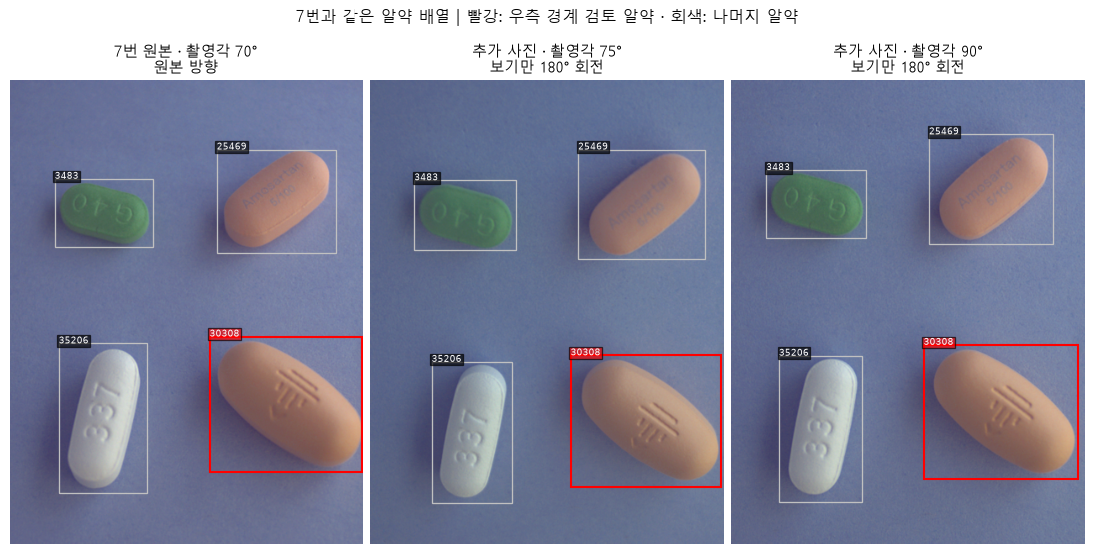

In [246]:
# 7번과 같은 알약 조합의 다른 촬영 사진을 전체 이미지와 bbox로 비교한다.
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from PIL import Image

layout_root = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "data/raw/train_annotations").is_dir()
)
layout_combination = "K-003483-025469-030308-035206"
layout_reference_name = f"{layout_combination}_0_2_0_2_70_000_200.png"
layout_target_class = 30308
layout_paths = sorted((layout_root / "data/raw/train_images").glob(f"{layout_combination}_*.png"))
layout_paths.sort(key=lambda path: (path.name != layout_reference_name, path.name))


def read_layout_labels(image_path: Path, root: Path) -> tuple[dict, list[dict]]:
    """해당 조합·사진의 JSON만 읽어 촬영 정보와 모든 알약 라벨을 모은다."""
    combination = image_path.stem.split("_", 1)[0]
    folder = root / "data/raw/train_annotations" / f"{combination}_json"
    metadata, labels = None, {}
    for source in sorted(folder.rglob(f"{image_path.stem}.json")):
        data = json.loads(source.read_text(encoding="utf-8"))
        image = next(item for item in data["images"] if item["file_name"] == image_path.name)
        if metadata is None:
            metadata = image
        for label in data["annotations"]:
            if label["image_id"] == image["id"]:
                labels[label["id"]] = label
    if metadata is None or not labels:
        raise ValueError(f"사진의 연결 라벨을 찾지 못했습니다: {image_path.name}")
    return metadata, list(labels.values())


def layout_centers(metadata: dict, labels: list[dict]) -> dict[int, tuple[float, float]]:
    """클래스별 bbox 중심을 사진 크기로 정규화해 배치 비교에 사용한다."""
    return {
        label["category_id"]: (
            (label["bbox"][0] + label["bbox"][2] / 2) / metadata["width"],
            (label["bbox"][1] + label["bbox"][3] / 2) / metadata["height"],
        )
        for label in labels
    }


layout_reference_path = layout_root / "data/raw/train_images" / layout_reference_name
layout_reference_metadata, layout_reference_labels = read_layout_labels(
    layout_reference_path, layout_root
)
layout_reference_centers = layout_centers(layout_reference_metadata, layout_reference_labels)
layout_comparison_rows = []
for path in layout_paths:
    metadata, labels = read_layout_labels(path, layout_root)
    centers = layout_centers(metadata, labels)
    if set(centers) != set(layout_reference_centers):
        continue
    # 같은 클래스의 중심을 비교해 정방향과 180도 중 원본 배치에 가까운 방향을 고른다.
    distances = []
    for rotated in (False, True):
        distance = sum(
            ((1 - x if rotated else x) - layout_reference_centers[class_id][0]) ** 2
            + ((1 - y if rotated else y) - layout_reference_centers[class_id][1]) ** 2
            for class_id, (x, y) in centers.items()
        ) / len(centers)
        distances.append(distance)
    rotated = distances[1] < distances[0]
    # 동일 조합이어도 배치가 크게 다르면 같은 배열 후보에서 제외한다.
    if min(distances) ** 0.5 > 0.12:
        continue
    layout_comparison_rows.append(
        {
            "path": path,
            "metadata": metadata,
            "labels": labels,
            "rotate_180": rotated,
            "center_distance": min(distances) ** 0.5,
        }
    )
if not layout_comparison_rows:
    raise ValueError("7번과 같은 배치의 사진을 찾지 못했습니다.")
layout_font = globals().get("bbox_review_font")
if layout_font is None:
    for font_name in ("Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "AppleGothic"):
        try:
            layout_font = font_manager.FontProperties(
                fname=font_manager.findfont(font_name, fallback_to_default=False)
            )
            break
        except ValueError:
            continue
if layout_font is None:
    font_path = Path(os.environ.get("WINDIR", "/mnt/c/Windows")) / "Fonts/malgun.ttf"
    if font_path.is_file():
        layout_font = font_manager.FontProperties(fname=font_path)

layout_preview_rows = layout_comparison_rows[:8]
print(
    f"같은 배열 후보 {len(layout_comparison_rows)}장 "
    f"(7번 포함 / 추가 {len(layout_comparison_rows) - 1}장)"
)
fig, axes = plt.subplots(
    1,
    len(layout_preview_rows),
    figsize=(3.8 * len(layout_preview_rows), 6.2),
    dpi=95,
    squeeze=False,
    layout="constrained",
)
for ax, row in zip(axes.flat, layout_preview_rows, strict=True):
    metadata = row["metadata"]
    width, height = metadata["width"], metadata["height"]
    with Image.open(row["path"]) as image:
        preview = image.convert("RGB")
        if row["rotate_180"]:
            preview = preview.transpose(Image.Transpose.ROTATE_180)
        preview.thumbnail((420, 560))
    ax.imshow(preview, extent=(0, width, height, 0))
    for label in row["labels"]:
        left, top, box_width, box_height = label["bbox"]
        if row["rotate_180"]:
            left, top = width - left - box_width, height - top - box_height
        target = label["category_id"] == layout_target_class
        color = "red" if target else "silver"
        ax.add_patch(
            Rectangle(
                (left, top),
                box_width,
                box_height,
                fill=False,
                edgecolor=color,
                linewidth=1.6 if target else 1,
            )
        )
        ax.text(
            left,
            top,
            f"{label['category_id']}",
            color="white",
            fontsize=7,
            bbox={"facecolor": "red" if target else "black", "alpha": 0.65, "pad": 1},
        )
    angle = metadata.get("camera_la", "?")
    reference = row["path"].name == layout_reference_name
    if layout_font is not None:
        title = f"{'7번 원본' if reference else '추가 사진'} · 촬영각 {angle}°"
        title += "\n보기만 180° 회전" if row["rotate_180"] else "\n원본 방향"
    else:
        title = f"{'Reference #7' if reference else 'Additional'} | {angle} deg"
        title += "\nDisplay rotated 180 deg" if row["rotate_180"] else "\nOriginal direction"
    ax.set_title(title, fontproperties=layout_font, fontsize=11)
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.axis("off")
legend = (
    "7번과 같은 알약 배열 | 빨강: 우측 경계 검토 알약 · 회색: 나머지 알약"
    if layout_font is not None
    else "Same arrangement | Red: target pill | Gray: other pills"
)
fig.suptitle(legend, fontproperties=layout_font, fontsize=12)
layout_preview_path = layout_root / "data/processed/bbox_grabcut/previews/same_layout_7.png"
layout_preview_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(layout_preview_path, dpi=110)
plt.show()
plt.close(fig)